# Data Analysis (live-edit)

Self-contained copy of `qubit_analysis_funcs.py`: every helper and analysis function is defined
in its own cell below, so small changes can be made and tested right here.

- **To change an analysis:** edit its function cell, run it (Shift+Enter), then run the cell below it.
- **Run order after a kernel restart:** run everything from the top through *Helpers* once
  (or *Run All Above* on the first experiment heading), then any section.
- This notebook does **not** import `qubit_analysis_funcs.py`, so edits here stay here.
  When a change is final, copy the cell back into the `.py` so the scripts and other notebooks get it.
- If you edit `_accepts_folder`, re-run the decorated `analyze_*` cells too (they were wrapped by the old one).


## Setup

In [4]:
%matplotlib inline

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import json
import pprint as pp
import os
import datetime
import functools

from fitting import *
from qualang_tools.plot import Fit
from plotting_helpers import *
from dsfit_copy import fithanger_new_withQc, hangerfunc_new_withQc
from circle_fit_dcm import notch_circlefit, model_S21

# Default color cycle for multi-trace plots
COLORS = ['b', 'g', 'r', 'c', 'm', 'y', 'k', 'orange']

No module named 'visa'
Warning VISA library import failed
Warning serial library import failed.
Could not load InstrumentManagerWindow
2026-09-29 20:40:51,585 - qm - INFO     - Starting session: 0c1d3877-96b3-44fa-b390-af600ed5a2cd


In [173]:
global_data_path = r"C:\\Users\\G41Lab\\Dropbox\\_Data\\20260727 - Shishir - 7Q1D FUN13PUR1D4\\AllQubitsZeroFlux\\data"

## Helpers

Shared by the analysis functions below. Re-run a cell here after editing it.

In [23]:
def dac_to_power(dac, dac_ref, dbm_ref, units='dBm'):
    """
    Convert a DAC gain value to output RF power, calibrated from a single
    reference point.

    Assumes DAC gain (in [0, 1]) scales linearly with the pulse's output
    voltage amplitude (true for QICK gen-channel gain), so power follows
    dBm = dbm_ref + 20*log10(dac/dac_ref).

    Parameters
    ----------
    dac : float or array
        DAC gain value(s) to convert, in [0, 1].
    dac_ref : float
        Reference DAC gain used for calibration, in [0, 1].
    dbm_ref : float
        Measured/known power in dBm at dac_ref.
    units : str
        'dBm' (default) or 'mW' for the returned power units.

    Returns
    -------
    power : float or array
        Power in the requested units.
    """
    dbm = dbm_ref + 20 * np.log10(dac / dac_ref)
    if units == 'dBm':
        return dbm
    elif units == 'mW':
        return 10 ** (dbm / 10)
    else:
        raise ValueError(f"Unknown units: {units!r} (use 'dBm' or 'mW')")

In [24]:
def power_to_dac(power, dac_ref, dbm_ref, units='dBm'):
    """
    Convert a target RF power to the DAC gain value that should produce it,
    calibrated from a single reference point (inverse of ``dac_to_power``).

    Parameters
    ----------
    power : float or array
        Target power, in the units given by ``units``.
    dac_ref : float
        Reference DAC gain used for calibration, in [0, 1].
    dbm_ref : float
        Measured/known power in dBm at dac_ref.
    units : str
        Units of ``power``: 'dBm' (default) or 'mW'.

    Returns
    -------
    dac : float or array
        DAC gain value(s) implied by ``power``. Not clipped to [0, 1] --
        check the result is in range before using it as a gain setting.
    """
    if units == 'dBm':
        dbm = power
    elif units == 'mW':
        dbm = 10 * np.log10(power)
    else:
        raise ValueError(f"Unknown units: {units!r} (use 'dBm' or 'mW')")
    return dac_ref * 10 ** ((dbm - dbm_ref) / 20)

In [25]:
def sequential_filenames(first_filename, num_files):
    """
    Expand the first file of a run into the list of consecutive filenames.

    Data files are named by get_next_filename with a zero-padded counter in
    front, e.g. "00004_repeat_X90_pulse_ge_Q1_2026-09-02.h5". Given that first
    name and how many files there are (counting the first), this returns the
    consecutive names with only the counter changed, for handing straight to
    the analysis functions that take a list.

    Parameters
    ----------
    first_filename : str
        Filename of the first file in the run, counter included.
    num_files : int
        Number of files in the run, including the first.

    Returns
    -------
    list of str
        The filenames, counter incremented one at a time; the counter keeps the
        same zero-padded width as the input.

    Examples
    --------
    >>> sequential_filenames("00004_repeat_X90_pulse_ge_Q1_2026-09-02.h5", 3)
    ['00004_repeat_X90_pulse_ge_Q1_2026-09-02.h5',
     '00005_repeat_X90_pulse_ge_Q1_2026-09-02.h5',
     '00006_repeat_X90_pulse_ge_Q1_2026-09-02.h5']
    """
    if num_files < 1:
        raise ValueError(f"num_files must be at least 1, got {num_files}")

    digits = 0
    while digits < len(first_filename) and first_filename[digits].isdigit():
        digits += 1
    if digits == 0:
        raise ValueError(
            f"{first_filename!r} does not start with a counter - expected "
            "something like '00004_<name>.h5'")

    start = int(first_filename[:digits])
    rest = first_filename[digits:]
    return [f"{start + i:0{digits}d}{rest}" for i in range(num_files)]

In [26]:
def _build_path(global_data_path, filename):
    """Join the global data directory and the experiment filename."""
    return global_data_path + "\\" + filename

In [27]:
def _load_config(slab_file_handle):
    """Extract and parse the JSON config from an open SlabFile."""
    return json.loads(slab_file_handle.attrs['config'])

In [28]:
def _qubit_prefix(config):
    """
    "Q1 - " for a config that recorded its qubit index, "" otherwise.

    initialize_configs only stores 'qubit_index' for non-MUX experiments, and
    files taken before it did so have no such key, so this quietly returns an
    empty string rather than guessing.
    """
    qubit_index = config.get('qubit_index', None)
    return f"Q{qubit_index} - " if qubit_index is not None else ""

In [29]:
# Fit results that belong in system_config.json, collected by
# _report_config_values so a folder-wide analysis can assemble the per-qubit
# lists at the end. Entries are (qubit_index, key, value, num_qubits).
_CONFIG_REPORTS = []


def _report_config_values(config, values):
    """
    Print fit results as the config entries they belong in, ready to paste.

    Each value is printed as its system_config.json key for this qubit, and
    remembered so that when a whole meas_list folder is analysed the wrapper
    can print the assembled 7-element lists afterwards.

    Parameters
    ----------
    config : dict
        The saved config of the file being analysed (for qubit_index).
    values : dict
        {config key: fitted value}, e.g. {'qubit_freq_ge': 5069.64}.
    """
    qubit_index = config.get('qubit_index', None)
    tag = f" (Q{qubit_index})" if qubit_index is not None else ""
    print(f"  --- config values{tag} ---")
    for key, value in values.items():
        print(f'  "{key}": {json.dumps(value)},')
        _CONFIG_REPORTS.append((qubit_index, key, value, config.get('num_qubits', None)))

In [30]:
def _print_config_lists():
    """Assemble what _report_config_values collected into per-qubit lists."""
    if not _CONFIG_REPORTS:
        return
    keys = []
    for _, key, _, _ in _CONFIG_REPORTS:
        if key not in keys:
            keys.append(key)
    known_n = [n for _, _, _, n in _CONFIG_REPORTS if n is not None]
    known_q = [q for q, _, _, _ in _CONFIG_REPORTS if q is not None]
    n_qubits = max(known_n) if known_n else (max(known_q) if known_q else 0)
    print("")
    print(f"  --- config lists, Q1..Q{n_qubits} (null = not in this folder) ---")
    for key in keys:
        values = [None] * n_qubits
        for q, k, v, _ in _CONFIG_REPORTS:
            if k == key and q is not None and 1 <= q <= n_qubits:
                values[q - 1] = v
        print(f'  "{key}": {json.dumps(values)},')

In [31]:
def _accepts_folder(func):
    """
    Let a single-file analysis function take a meas_list folder instead.

    If the name passed as filename is a folder under global_data_path, the
    function is run on every .h5 in it (sorted, so in qubit order as written),
    a list of its results is returned, and the config values each run reported
    are printed as per-qubit lists at the end. A plain filename behaves
    exactly as before.

    collage=True (folder only) draws every file as one panel of a single
    figure instead of a figure each - a 4 x 2 grid for a 7-qubit folder, the
    spare slot left empty - and returns that figure. Only functions that take
    an ax argument can be drawn this way (see _plot_collage).
    """
    @functools.wraps(func)
    def wrapper(global_data_path, filename, *args, collage=False, **kwargs):
        target = _build_path(global_data_path, filename)
        if not os.path.isdir(target):
            return func(global_data_path, filename, *args, **kwargs)
        files = sorted(f for f in os.listdir(target) if f.endswith('.h5'))
        if not files:
            raise ValueError(f"No .h5 files found in {target}")
        print(f"Data folder: {target}  ({len(files)} files)")
        del _CONFIG_REPORTS[:]
        if collage:
            fig = _plot_collage(func, target, files, args, kwargs)
            _print_config_lists()
            return fig
        results = []
        for f in files:
            print("")
            results.append(func(target, f, *args, **kwargs))
        _print_config_lists()
        return results
    return wrapper

In [68]:
import inspect
import textwrap


def _plot_collage(func, folder, files, args, kwargs, n_cols=4):
    """
    Draw one analysis per file as the panels of a single figure.

    Used by _accepts_folder when called with collage=True. The panels fill a
    grid n_cols wide (4 x 2 for seven qubits); unused slots are left blank.
    func must take an ax argument and draw into it instead of opening its
    own figure. The folder is stamped once, under the whole figure.
    """
    if 'ax' not in inspect.signature(func).parameters:
        raise ValueError(f"{func.__name__} cannot be drawn as a collage yet "
                         f"(it has no ax argument)")
    n_rows = -(-len(files) // n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(8 * n_cols, 6 * n_rows),
                             squeeze=False)
    axes = axes.ravel()

    # Anything a panel calls plt.show() for (the g/e calibration blobs, the
    # resonator phase plot) would otherwise display the collage half-drawn,
    # so every show is held until all the panels are in. A panel that fails
    # (a fit that does not converge, say) is marked as such and the rest
    # still get drawn.
    real_show = plt.show
    plt.show = lambda *a, **k: None
    try:
        for ax, f in zip(axes, files):
            print("")
            try:
                func(folder, f, *args, ax=ax, **kwargs)
            except Exception as err:
                print(f"  FAILED: {type(err).__name__}: {err}")
                if not ax.get_title():
                    ax.set_title(f)
                ax.text(0.5, 0.5, f"failed:\n{type(err).__name__}", transform=ax.transAxes,
                        ha='center', va='center', color='red', fontsize=14)
            # the single-plot font sizes are too big for a panel
            ax.title.set_fontsize(16)
            ax.xaxis.label.set_fontsize(16)
            ax.yaxis.label.set_fontsize(16)
            ax.tick_params(labelsize=14)
            # long titles and x labels (Ramsey, the single-shot notes) would
            # run into the next panel; wrap them to the panel width
            width_in = 0.95 * ax.get_position().width * fig.get_figwidth()
            # for text in (ax.title, ax.xaxis.label):
            #     chars = max(20, int(width_in * 72 / (0.55 * text.get_fontsize())))
            #     text.set_text(chr(10).join(textwrap.fill(line, chars)
            #                                for line in text.get_text().split(chr(10))))
    finally:
        plt.show = real_show
    for ax in axes[len(files):]:
        ax.axis('off')

    fig.tight_layout(rect=(0, 0.03, 1, 1))
    parent, name = os.path.split(folder.rstrip('/' + os.sep))
    fig.text(0.5, 0.005, parent + chr(10) + name, ha='center', va='bottom',
             fontsize=14, color='black')
    plt.show()
    return fig

In [33]:
def _stamp_data_path(data_path, fig=None, footnote=None):
    """
    Print the source data path in small text at the bottom of the figure.

    A single path is written as two lines, the folder above the file (or
    scan-folder) name, so it fits on a square figure. Anything already
    containing line breaks is written as given.

    footnote, if given, is written on its own line just above the path - for
    a short note about how the data was taken, like which pulse prepared it.
    """
    if fig is None:
        fig = plt.gcf()
    fig.subplots_adjust(bottom=0.22)
    if footnote:
        fig.text(0.5, 0.085, footnote, ha='center', va='bottom', fontsize=9)
    if chr(10) not in data_path:
        folder, name = os.path.split(data_path.rstrip('/' + os.sep))
        if folder and name:
            data_path = folder + chr(10) + name
    fig.text(0.5, 0.02, data_path, ha='center', va='bottom', fontsize=7, color='black')

In [34]:
def _normalize_population(I, Q, Ig, Qg, Ie, Qe,
                           ef=False, If=None, Qf=None):
    """
    Compute normalised qubit population from averaged IQ data and
    single-shot reference blobs.

    Parameters
    ----------
    I, Q : array
        Averaged I/Q quadrature data from the experiment sweep.
    Ig, Qg, Ie, Qe : array
        Single-shot reference means for |g> and |e>.
    ef : bool
        If True, normalise for e-f transition instead of g-e.
    If, Qf : array or None
        Single-shot reference for |f>, required when ef=True.

    Returns
    -------
    pop_norm : array
        Normalised population.
    """
    e = np.mean(Ie + 1j * Qe)
    g = np.mean(Ig + 1j * Qg)

    if ef:
        f = np.mean(If + 1j * Qf)
        pop_norm = np.abs(((I + 1j * Q) - e) * (f - e) / abs(f - e) ** 2)
    else:
        pop_norm = np.abs(((I + 1j * Q) - g) * (e - g) / abs(e - g) ** 2)

    return pop_norm

In [35]:
def _compute_fidelity_by_projection(I_g, Q_g, I_e, Q_e,
                                     bin_num=100,
                                     n_threshold_pts=1000,
                                     plot=True,
                                     title_prefix="",
                                     data_path=None, footnote=None):
    """
    Fidelity estimate — Method 1 (manual IQ projection + threshold sweep).

    Projects both blobs onto the line connecting their centroids, then sweeps
    a discrimination threshold to find the maximum fidelity.

    Parameters
    ----------
    I_g, Q_g : array   Single-shot I/Q for |g>.
    I_e, Q_e : array   Single-shot I/Q for |e>.
    bin_num : int       Number of histogram bins.
    n_threshold_pts : int  Number of threshold points to sweep.
    plot : bool         Show the projected histogram.
    title_prefix : str  Optional prefix for the plot title.
    data_path : str or None  If given (and plot), stamp it at the bottom
        of the figure.

    Returns
    -------
    fidelity : float    Best fidelity (contrast), range [0, 1].
    sigma_g : float     Std dev of projected |g> distribution.
    sigma_e : float     Std dev of projected |e> distribution.
    """
    vec_I = np.mean(I_e) - np.mean(I_g)
    vec_Q = np.mean(Q_e) - np.mean(Q_g)
    norm = abs(vec_I + 1j * vec_Q) ** 2

    gstate = ((I_g - np.mean(I_g)) * vec_I + (Q_g - np.mean(Q_g)) * vec_Q) / norm
    estate = ((I_e - np.mean(I_g)) * vec_I + (Q_e - np.mean(Q_g)) * vec_Q) / norm

    if plot:
        plt.figure()
        plt.hist(gstate, bins=bin_num, label='g', density=True)
        plt.hist(estate, bins=bin_num, label='e', alpha=0.7, density=True)
        plt.legend()

    th_list = np.linspace(min(gstate), max(estate), n_threshold_pts)
    fidelity_curve = [
        (np.sum(gstate < th) + np.sum(estate > th)) / len(gstate) / 2
        for th in th_list
    ]
    best_fid = max(fidelity_curve) * 2 - 1
    sigma_g = np.std(gstate)
    sigma_e = np.std(estate)

    if plot:
        plt.title(f"{title_prefix}Readout Fidelity: {best_fid:.3f}")
        if data_path is not None:
            _stamp_data_path(data_path, footnote=footnote)
        plt.show()

    print(f"  Method 1 fidelity = {best_fid:.4f}")
    print(f"  sigma_g = {sigma_g:.4f}")
    print(f"  sigma_e = {sigma_e:.4f}")

    return best_fid, sigma_g, sigma_e

In [36]:
def _compute_fidelity_by_hist(I_g, Q_g, I_e, Q_e,
                               plot=True, ran=50, data_path=None,
                               footnote=None):
    """
    Fidelity estimate — Method 2 (using the ``hist`` helper from
    plotting_helpers, which performs an optimal-angle rotation).

    Parameters
    ----------
    I_g, Q_g : array   Single-shot I/Q for |g>.
    I_e, Q_e : array   Single-shot I/Q for |e>.
    plot : bool         Show the rotated histogram.
    ran : float         Histogram range parameter passed to ``hist()``.
    data_path : str or None  If given (and plot), stamp it at the bottom
        of the figure.

    Returns
    -------
    fid : float         Fidelity after rotation.
    threshold : float   Optimal discrimination threshold.
    angle : float       Rotation angle used.
    """
    fid, threshold, angle = hist(
        data=[I_g, Q_g, I_e, Q_e], plot=plot, ran=ran
    )
    if plot and data_path is not None:
        _stamp_data_path(data_path, footnote=footnote)
    print(f"  Method 2 fidelity = {fid:.3f}")
    print(f"  threshold = {threshold:.4f},  angle = {angle:.4f}")
    return fid, threshold, angle

In [37]:
def _compute_fidelity_gf_projection(I_g, Q_g, I_f, Q_f,
                                     bin_num=100,
                                     n_threshold_pts=1000,
                                     plot=True,
                                     data_path=None, footnote=None):
    """
    Fidelity by projection for g-f discrimination.

    Same projection method as Method 1 but between |g> and |f> blobs.
    """
    vec_I = np.mean(I_f) - np.mean(I_g)
    vec_Q = np.mean(Q_f) - np.mean(Q_g)
    norm = abs(vec_I + 1j * vec_Q) ** 2

    gstate = ((I_g - np.mean(I_g)) * vec_I + (Q_g - np.mean(Q_g)) * vec_Q) / norm
    fstate = ((I_f - np.mean(I_g)) * vec_I + (Q_f - np.mean(Q_g)) * vec_Q) / norm

    if plot:
        plt.figure()
        plt.hist(gstate, bins=bin_num, label='g')
        plt.hist(fstate, bins=bin_num, label='f', alpha=0.7, color='g')
        plt.legend()
        plt.title("Readout g-f")
        if data_path is not None:
            _stamp_data_path(data_path, footnote=footnote)
        plt.show()

    th_list = np.linspace(min(gstate), max(fstate), n_threshold_pts)
    fidelity_curve = [
        (np.sum(gstate < th) + np.sum(fstate > th)) / len(gstate) / 2
        for th in th_list
    ]
    best_fid = max(fidelity_curve) * 2 - 1

    print(f"  g-f fidelity = {best_fid:.4f}")
    print(f"  sigma_g = {np.std(gstate):.4f}")
    print(f"  sigma_f = {np.std(fstate):.4f}")
    return best_fid

In [38]:
def _compute_fidelity_ef_projection(I_e, Q_e, I_f, Q_f,
                                     bin_num=100,
                                     n_threshold_pts=1000,
                                     plot=True,
                                     data_path=None, footnote=None):
    """
    Fidelity by projection for e-f discrimination.

    Same projection method as Method 1 but between |e> and |f> blobs.
    """
    vec_I = np.mean(I_f) - np.mean(I_e)
    vec_Q = np.mean(Q_f) - np.mean(Q_e)
    norm = abs(vec_I + 1j * vec_Q) ** 2

    estate = ((I_e - np.mean(I_e)) * vec_I + (Q_e - np.mean(Q_e)) * vec_Q) / norm
    fstate = ((I_f - np.mean(I_e)) * vec_I + (Q_f - np.mean(Q_e)) * vec_Q) / norm

    if plot:
        plt.figure()
        plt.hist(estate, bins=bin_num, label='e')
        plt.hist(fstate, bins=bin_num, label='f', alpha=0.7)
        plt.legend()
        plt.title("Readout e-f")
        if data_path is not None:
            _stamp_data_path(data_path, footnote=footnote)
        plt.show()

    th_list = np.linspace(min(estate), max(fstate), n_threshold_pts)
    fidelity_curve = [
        (np.sum(estate < th) + np.sum(fstate > th)) / len(estate) / 2
        for th in th_list
    ]
    best_fid = max(fidelity_curve) * 2 - 1

    print(f"  e-f fidelity = {best_fid:.4f}")
    print(f"  sigma_e = {np.std(estate):.4f}")
    print(f"  sigma_f = {np.std(fstate):.4f}")
    return best_fid

In [39]:
def _plot_ge_calibration(Ig, Qg, Ie, Qe, title_prefix=""):
    """
    Plot the g/e single-shot calibration blobs and compute their fidelity.

    Called by experiment functions when both SS=True and plot_cal=True.

    Parameters
    ----------
    Ig, Qg : array   Single-shot I/Q for |g> calibration.
    Ie, Qe : array   Single-shot I/Q for |e> calibration.
    title_prefix : str  Optional label prepended to plot titles.
    """
    print(f"  --- {title_prefix}g-e calibration ---")

    # IQ scatter
    plt.figure()
    plt.title(f"{title_prefix}Calibration IQ Blob")
    plt.plot(Ig, Qg, '.', label='g')
    plt.plot(Ie, Qe, '.', label='e')
    plt.xlabel("I")
    plt.ylabel("Q")
    plt.legend()
    plt.axis('square')
    plt.show()

    # Fidelity via projection
    _compute_fidelity_by_projection(Ig, Qg, Ie, Qe,
                                     plot=True,
                                     title_prefix=f"{title_prefix}Cal ")

---
# Experiments

Each section: the analysis function, then a cell that runs it on a data file.

### Time of Flight

In [79]:
@_accepts_folder
def analyze_time_of_flight(global_data_path, filename, show_plot=True, ax=None):
    """
    Time-of-flight measurement.

    Loads the TOF data and plots I, Q, and magnitude vs time.

    Parameters
    ----------
    global_data_path : str
        Root directory for all data files.
    filename : str
        HDF5 filename, e.g. "00000_tof_Q1_2026-06-06.h5".
    show_plot : bool
        If True, add a legend and display the figure.

    ax : matplotlib Axes, optional
        Draw into this axes (one panel of a collage) instead of a new figure;
        the data-path stamp is then left to the caller.

    Returns
    -------
    fig : matplotlib Figure
        Handle to the plotted figure, for further modification.
    """
    data = _build_path(global_data_path, filename)
    print(f"Data path: {data}")

    with SlabFile(data, 'r') as f:
        t = array(f['t'])[0]
        I = array(f['avgi'])[0]
        Q = array(f['avgq'])[0]
        config = _load_config(f)

    if ax is None:
        fig = plt.figure()
    else:
        plt.sca(ax)
        fig = ax.figure
    plt.plot(t, I, label="I value")
    plt.plot(t, Q, label="Q value")
    plt.plot(t, np.abs(I + 1j * Q), label="magnitude")
    if show_plot:
        plt.legend()
    plt.ylabel("ADC Units")
    plt.xlabel("us")
    plt.title(_qubit_prefix(config) + "Time of Flight Experiment")
    if ax is None:
        _stamp_data_path(data)
        if show_plot:
            plt.show()

    return fig

Data path: C:\\Users\\G41Lab\\Dropbox\\_Data\\20260727 - Shishir - 7Q1D FUN13PUR1D4\\AllQubitsZeroFlux\\data\00002_tof_Q7_2026-09-29.h5


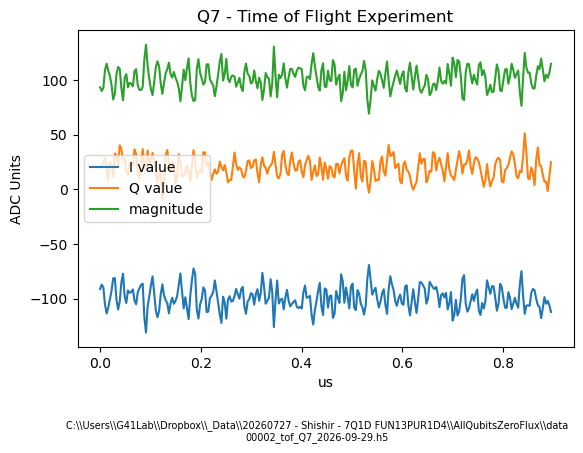

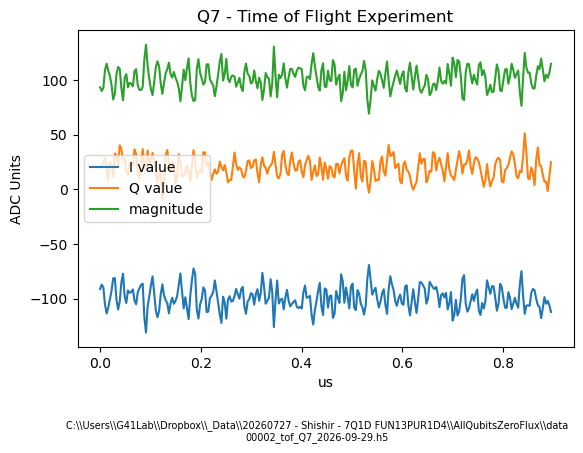

In [84]:
filename = r"00002_tof_Q7_2026-09-29.h5"
analyze_time_of_flight(global_data_path, filename, show_plot=True)

# add line option for analysis

### Resonator Spectroscopy

In [63]:
@_accepts_folder
def analyze_resonator_spectroscopy(global_data_path, filename,
                                    fit_resonator=True, fit_method='circle',
                                    logscale=False, show_plot=True,
                                    perform_fit=True, plot_phase=False, ax=None):
    """
    Single-resonator spectroscopy (amplitude + phase).

    Parameters
    ----------
    global_data_path : str
        Root directory for all data files.
    filename : str
        HDF5 filename, e.g. "00000_res_spec_ge_Q1_2026-06-06.h5".
    perform_fit : bool
        If True (default), fit the resonator and draw the fit. If False, only
        the data is plotted - same scaling, labels and stamp, no fit.
    fit_resonator : bool
        If True, fit the resonator lineshape using ``fit_method``.
    fit_method : str
        "circle" (default) - notch-type circle fit using the Diameter
            Correction Method (``circle_fit_dcm.notch_circlefit``), fit
            directly to the complex avgi/avgq data. This is the standard
            method for extracting Qi/Qc/Ql and correctly accounts for
            impedance-mismatch asymmetry and cable delay.
        "hanger" - hanger-with-asymmetry lineshape fit
            (``hangerfunc_new_withQc`` from dsfit_copy), fit in dB scale
            to the amplitude data only.
    logscale : bool
        If True, plot the amplitude data and fit in dB (log) scale instead
        of linear a.u.
    show_plot : bool
        If True, add a legend and display both figures.
    ax : matplotlib Axes, optional
        Draw the amplitude plot into this axes (one panel of a collage)
        instead of a new figure; the data-path stamp is then left to the
        caller.

    Returns
    -------
    fig_amp, fig_phase : matplotlib Figure
        Handles to the amplitude and phase figures, for further modification.
    """
    data = _build_path(global_data_path, filename)
    print(f"Data path: {data}")

    with SlabFile(data, 'r') as f:
        freqs = array(f['fpts'])[0]
        amps = array(f['amps'])[0]
        phases = array(f['phases'])[0]
        avgi = array(f['avgi'])[0]
        avgq = array(f['avgq'])[0]
        config = _load_config(f)

    amps_db = 20 * np.log10(amps)

    # --- Amplitude plot ---
    if ax is None:
        fig_amp = plt.figure(figsize=(8, 6))
    else:
        plt.sca(ax)
        fig_amp = ax.figure
    plt.plot(freqs, amps_db if logscale else amps, marker='o', label='data')
    plt.ylabel("dB" if logscale else "a.u.", fontsize=16)
    plt.xlabel("Resonator Frequency (MHz)", fontsize=16)
    plt.tick_params(labelsize=12)
    plt.title(_qubit_prefix(config) + f"Resonator Spectroscopy, Gain = {config['res_gain_ge']}", fontsize=16)

    if perform_fit and fit_resonator:
        freqs_fit = np.linspace(freqs[0], freqs[-1], 1000)

        if fit_method == 'circle':
            # Diameter Correction Method circle fit on the complex S21 data.
            z_data = avgi + 1j * avgq
            fit = notch_circlefit(freqs, z_data, correct_delay=True)
            fit_curve_lin = np.abs(model_S21(freqs_fit, fit['fr'], fit['Ql'],
                                              fit['Qc'], fit['phi0'],
                                              fit['P_off'], fit['delay']))
            fit_curve = 20 * np.log10(fit_curve_lin) if logscale else fit_curve_lin
            f0 = fit['fr']

            plt.plot(freqs_fit, fit_curve, c='red', label='fit')
            plt.axvline(f0, c='red', linestyle='--', label=f'fit f0: {f0:.3f}')
            plt.axvline(freqs[np.argmin(amps)], c='blue', linestyle='--',
                        label=f"min amp: {freqs[np.argmin(amps)]:.3f}")
            print(f"  Min amp at {freqs[np.argmin(amps)]} MHz")
            print("  Circle fit (DCM) results:")
            print(f"    f0 = {fit['fr']} MHz")
            print(f"    Ql = {fit['Ql']}")
            print(f"    Qc = {fit['Qc']}")
            print(f"    Qi = {fit['Qi']}")
            print(f"    phi0 = {fit['phi0']} rad")
            print(f"    delay = {fit['delay']} us")

        elif fit_method == 'hanger':
            # hangerfunc_new_withQc fits in dB, so fit on the log-scale data
            # regardless of the display scale, then undo the log for a linear
            # display curve via the inverse of the dB equation (amp = 10**(dB/20)).
            f0, Qi, Qc, df, scale = fithanger_new_withQc(freqs, amps_db, showfit=False)
            fit_curve_db = hangerfunc_new_withQc([f0, Qi, Qc, df, scale], freqs_fit)
            fit_curve = fit_curve_db if logscale else 10 ** (fit_curve_db / 20)

            plt.plot(freqs_fit, fit_curve, c='red', label='fit')
            plt.axvline(f0, c='red', linestyle='--', label=f'fit f0: {f0:.3f}')
            plt.axvline(freqs[np.argmin(amps)], c='blue', linestyle='--',
                        label=f"min amp: {freqs[np.argmin(amps)]:.3f}")
            print(f"  Min amp at {freqs[np.argmin(amps)]} MHz")
            print("  Hanger fit results:")
            print(f"    f0 = {f0} MHz")
            print(f"    Qi = {Qi}")
            print(f"    Qc = {Qc}")
            print(f"    df = {df} MHz")
            print(f"    scale = {scale:.4f}")

        else:
            raise ValueError(f"Unknown fit_method: {fit_method!r} (use 'circle' or 'hanger')")

        _report_config_values(config, {'res_freq_ge': float(f0)})

    if show_plot:
        plt.legend(fontsize=12)
    if ax is None:
        _stamp_data_path(data)
        if show_plot:
            plt.show()

    # --- Phase plot ---
    if plot_phase:
        fig_phase = plt.figure(figsize=(8, 12))
        plt.plot(freqs, np.unwrap(phases), marker='o', label='phase data')
        plt.ylabel("radians", fontsize=16)
        plt.xlabel("Resonator Frequency (MHz)", fontsize=16)
        plt.tick_params(labelsize=14)
        plt.title(_qubit_prefix(config) + "Resonator Spectroscopy Phase")
        _stamp_data_path(data)
        if show_plot:
            plt.show()



Data path: C:\\Users\\G41Lab\\Dropbox\\_Data\\20260727 - Shishir - 7Q1D FUN13PUR1D4\\AllQubitsZeroFlux\\data\00004_res_spec_ge_Q7_2026-09-29.h5
  Min amp at 7147.111927986145 MHz
  Hanger fit results:
    f0 = 7147.084733046789 MHz
    Qi = 81633.24219323216
    Qc = 6903.883958351842
    df = -0.29891886008278556 MHz
    scale = 321.4708
  --- config values (Q7) ---
  "res_freq_ge": 7147.084733046789,


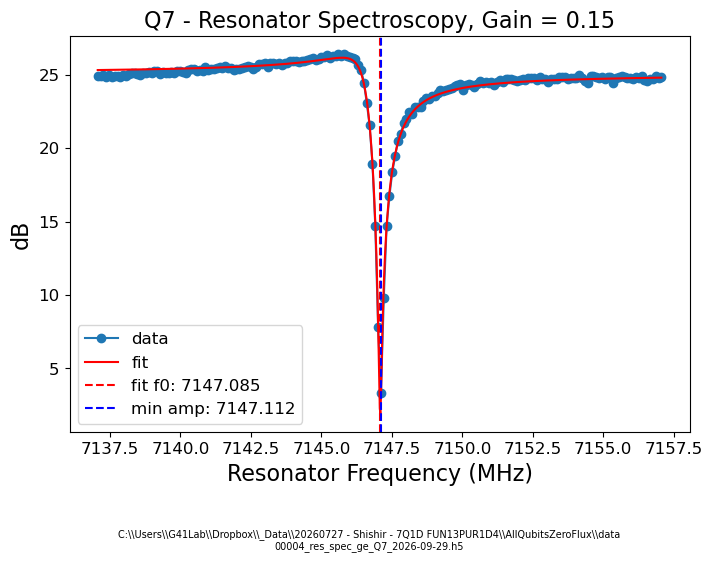

In [74]:
path = r"00005_res_spec_ge_all_2026-09-29"
path = r"00004_res_spec_ge_Q7_2026-09-29.h5"
analyze_resonator_spectroscopy(global_data_path, path, fit_method = "hanger", collage=True, logscale=True)

# every qubit of a meas_list folder in one figure
# analyze_resonator_spectroscopy(global_data_path, folder, fit_method="hanger", collage=True)

### Qubit Spectroscopy

In [98]:
@_accepts_folder
def analyze_qubit_spectroscopy(global_data_path, filename,
                                SS=False, ef=False, dac=0.0,
                                plot_cal=False, show_plot=True,
                                perform_fit=True, ax=None):
    """
    Single-qubit spectroscopy.

    Parameters
    ----------
    global_data_path : str
        Root directory for all data files.
    filename : str
        HDF5 filename, e.g. "00000_qubit_spec_ge_Q1_2026-06-06.h5".
    SS : bool
        True if single-shot normalisation data was collected.
    ef : bool
        True if this is an e-f spectroscopy experiment.
    dac : float
        DAC current in mA (for plot labelling).
    plot_cal : bool
        If True (and SS=True), plot the g/e calibration IQ blobs and fidelity.
    show_plot : bool
        If True, add a legend and display the figure.
    perform_fit : bool
        If True (default), fit the data and draw the fit. If False, only the
        data is plotted - same scaling, labels and stamp, no fit.
    ax : matplotlib Axes, optional
        Draw into this axes (one panel of a collage) instead of a new figure;
        the data-path stamp is then left to the caller.

    Returns
    -------
    fig : matplotlib Figure
        Handle to the plotted figure, for further modification.
    """
    data = _build_path(global_data_path, filename)
    print(f"Data path: {data}")

    with SlabFile(data, 'r') as f:
        freqs = array(f['fpts'])[0]
        I = array(f['avgi'])[0]
        Q = array(f['avgq'])[0]
        amps = array(f['amps'])[0]
        config = _load_config(f)

        if SS:
            Ig = array(f['I_g'])[0]
            Qg = array(f['Q_g'])[0]
            Ie = array(f['I_e'])[0]
            Qe = array(f['Q_e'])[0]
            If_data = array(f['I_f'])[0] if ef else None
            Qf_data = array(f['Q_f'])[0] if ef else None

    if SS:
        if plot_cal:
            _plot_ge_calibration(Ig, Qg, Ie, Qe, title_prefix=_qubit_prefix(config) + "Qubit Spec ")
        ydata = _normalize_population(I, Q, Ig, Qg, Ie, Qe,
                                       ef=ef, If=If_data, Qf=Qf_data)
    else:
        ydata = amps

    if ax is None:
        fig = plt.figure(figsize=(8, 6))
    else:
        plt.sca(ax)
        fig = ax.figure
    plt.plot(freqs, ydata, marker='o', label='data')
    if SS:
        plt.ylabel("Qubit Population", fontsize=14)
        plt.axhline(1, color='black', linestyle='--')
    else:
        plt.ylabel("a.u.", fontsize=14)
    plt.xlabel("Qubit Frequency (MHz)", fontsize=14)
    plt.tick_params(labelsize=12)
    plt.title(_qubit_prefix(config) + f"Qubit Spectroscopy\nGain = {config['qubit_gain_ge']}, "
              + r"$\sigma$" + f" (us) = {config['sigma_ge']}, DAC (mA) = {dac}")

    if perform_fit:
        fit = Fit()
        fit_results = fit.transmission_resonator_spectroscopy(freqs, ydata, plot=show_plot)
        plt.axvline(fit_results['f'][0], c='red', linestyle='--')
        print("  Fit results:")
        pp.pprint(fit_results)
        _report_config_values(config, {'qubit_freq_ge': float(fit_results['f'][0])})

    if show_plot:
        plt.legend()
    if ax is None:
        _stamp_data_path(data)
        if show_plot:
            plt.show()

    return fig

Data path: C:\\Users\\G41Lab\\Dropbox\\_Data\\20260727 - Shishir - 7Q1D FUN13PUR1D4\\AllQubitsZeroFlux\\data\00000_qubit_spec_ge_Q3_2026-09-29.h5
  Fit results:
{'f': [3740.899992250234, 0.03924228675337904],
 'fit_func': <function Fit.transmission_resonator_spectroscopy.<locals>.<lambda> at 0x000002597B366B60>,
 'k': [2.841075007629444, 0.10353109434924536],
 'kc': [23.875170784226874, 0.02217635630452612],
 'ki': [-21.03409577659743, 0.08135473804471924],
 'offset': [2.3380813733088215, 0.011647292362417705]}
  --- config values (Q3) ---
  "qubit_freq_ge": 3740.899992250234,


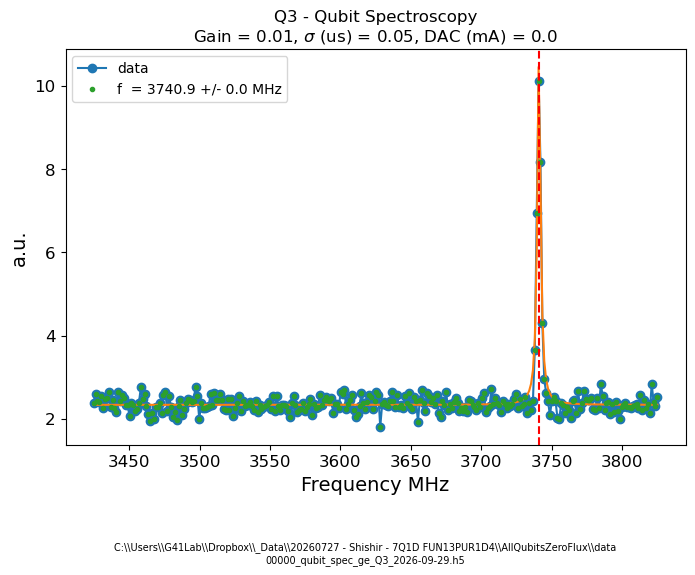

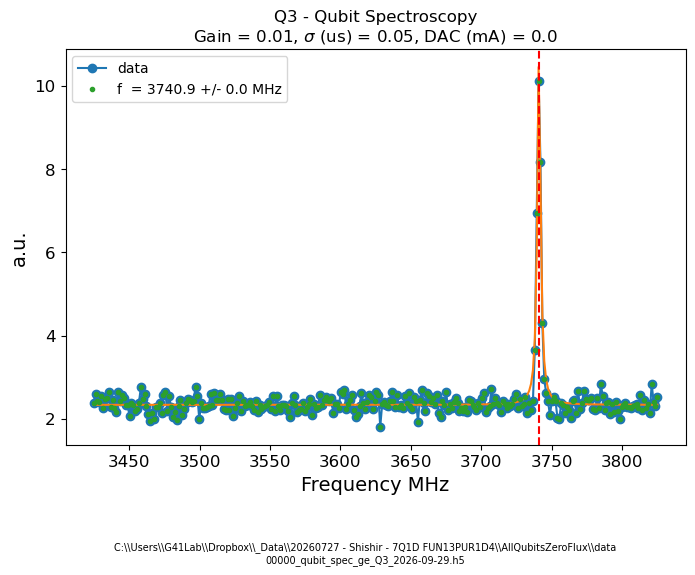

In [106]:
path = r"00007_qubit_spec_ge_all_2026-09-29"
path = r"00000_qubit_spec_ge_Q3_2026-09-29.h5"
analyze_qubit_spectroscopy(global_data_path, path, collage=True)#, SS = True)

# every qubit of a meas_list folder in one figure
# analyze_qubit_spectroscopy(global_data_path, folder, collage=True)

### Qubit Spectroscopy Temporal

In [ ]:
def analyze_qubit_spec_temporal_scan(global_data_path, folder_name,
                                      time_spacing_min=5.0, show_plot=True,
                                      perform_fit=True):
    """
    Qubit spectroscopy temporal scan (e.g. a folder of overnight qubit
    spectroscopy runs), plotted as a frequency-vs-time colormap.

    Loads every qubit spectroscopy data file in a folder and plots a 2D
    colormap: x = elapsed time, y = frequency, z = spectroscopy
    amplitude (magnitude). The peak frequency of each individual spectrum
    (the frequency of its maximum amplitude) is overlaid as a line, and
    the qubit frequency is also fit for each file. Measurements are
    assumed to be evenly spaced ``time_spacing_min`` minutes apart
    (matching e.g. the night_wait interval used by
    003a_overnight_qubit_spec_ge.py), in the order the files sort
    alphabetically (i.e. by their sequential file number).

    Parameters
    ----------
    global_data_path : str
        Root directory for all data files.
    folder_name : str
        Name of the subfolder (under global_data_path) containing the
        qubit spectroscopy data files, e.g.
        "2026-08-17overnight _qubit_spec_ge".
    time_spacing_min : float
        Assumed time in minutes between consecutive measurements.
    show_plot : bool
        If True, add a legend and display the figure.

    perform_fit : bool
        If True (default), fit the data and draw the fit. If False, only the
        data is plotted - same scaling, labels and stamp, no fit.
    Returns
    -------
    fig : matplotlib Figure
        Handle to the plotted figure, for further modification.
    freq_values : 1D np.array
        Fitted qubit frequency (MHz) for each file, in the order plotted.
    peaks : 1D np.array
        Frequency (MHz) of the maximum amplitude point of each individual
        spectrum -- this is the line overlaid on the colormap.
    """
    folder_path = os.path.join(global_data_path, folder_name)
    print(f"Data folder: {folder_path}")

    files = sorted(f for f in os.listdir(folder_path) if f.endswith('.h5'))
    if not files:
        raise ValueError(f"No .h5 files found in {folder_path}")

    freq_values = []
    peaks = []
    amps_list = []
    freqs_ref = None
    config = {}
    for fname in files:
        with SlabFile(os.path.join(folder_path, fname), 'r') as f:
            freqs = array(f['fpts'])[0]
            amps = array(f['amps'])[0]
            if not config:
                config = _load_config(f)

        if freqs_ref is None:
            freqs_ref = freqs
        elif len(freqs) != len(freqs_ref):
            raise ValueError(
                f"{fname} has a different number of frequency points "
                f"({len(freqs)}) than earlier files ({len(freqs_ref)}); "
                "can't build a shared colormap frequency axis.")
        amps_list.append(amps)

        if perform_fit:
            fit = Fit()
            fit_results = fit.transmission_resonator_spectroscopy(freqs, amps,
                                                                  plot=False)
            freq_values.append(fit_results['f'][0])
        else:
            freq_values.append(np.nan)
        peaks.append(freqs[np.argmax(amps)])

    freq_values = np.array(freq_values)
    peaks = np.array(peaks)
    time_axis = np.arange(len(files)) * time_spacing_min
    z_data = np.array(amps_list).T  # shape (n_freqs, n_files)

    # earliest file's timestamp, for the start-time stamp
    mtimes = [os.path.getmtime(os.path.join(folder_path, fname)) for fname in files]
    start_time = datetime.datetime.fromtimestamp(min(mtimes))

    fig = plt.figure(figsize=(12,8))
    mesh = plt.pcolormesh(time_axis, freqs_ref, z_data, shading='auto')
    plt.colorbar(mesh, label='Amplitude (a.u.)')
    plt.plot(time_axis, peaks, marker='o', linestyle='-', c='red', label='peak')
    plt.xlabel("Elapsed Time (min)")
    plt.ylabel("Qubit Frequency (MHz)")
    plt.title(_qubit_prefix(config) + f"Qubit Spectroscopy Temporal Scan ({len(files)} measurements, "
              f"{time_spacing_min:.1f} min spacing)")
    if show_plot:
        plt.legend()
    _stamp_data_path(
        f"{folder_path}\nStart time: {start_time.strftime('%Y-%m-%d %H:%M:%S')}",
        fig)
    if show_plot:
        plt.show()

    return fig, freq_values, peaks

In [ ]:
data_folder = "2026-08-17overnight_qubit_spec_ge"
analyze_qubit_spec_temporal_scan(global_data_path, data_folder)

### Length Rabi

In [40]:
@_accepts_folder
def analyze_length_rabi(global_data_path, filename,
                         SS=False, ef=False,
                         plot_cal=False, show_plot=True,
                         perform_fit=True, ax=None):
    """
    Length (time) Rabi oscillation experiment.

    Parameters
    ----------
    global_data_path : str
        Root directory for all data files.
    filename : str
        HDF5 filename, e.g. "00000_time_rabi_ge_Q1_2026-05-31.h5".
    SS : bool
        True if single-shot normalisation data was collected.
    ef : bool
        True if this is an e-f Rabi experiment.
    plot_cal : bool
        If True (and SS=True), plot the g/e calibration IQ blobs and fidelity.
    show_plot : bool
        If True, add a legend and display the figure.

    perform_fit : bool
        If True (default), fit the data and draw the fit. If False, only the
        data is plotted - same scaling, labels and stamp, no fit.
    ax : matplotlib Axes, optional
        Draw into this axes (one panel of a collage) instead of a new figure;
        the data-path stamp is then left to the caller.

    Returns
    -------
    fig : matplotlib Figure
        Handle to the plotted figure, for further modification.
    """
    data = _build_path(global_data_path, filename)
    print(f"Data path: {data}")

    with SlabFile(data, 'r') as f:
        lengths = array(f['lengths'])[0]
        I = array(f['avgi'])[0]
        Q = array(f['avgq'])[0]
        amps = array(f['amps'])[0]
        config = _load_config(f)

        if SS:
            Ig = array(f['I_g'])[0]
            Qg = array(f['Q_g'])[0]
            Ie = array(f['I_e'])[0]
            Qe = array(f['Q_e'])[0]
            If_data = array(f['I_f'])[0] if ef else None
            Qf_data = array(f['Q_f'])[0] if ef else None

    if SS:
        if plot_cal:
            _plot_ge_calibration(Ig, Qg, Ie, Qe, title_prefix=_qubit_prefix(config) + "Length Rabi ")
        ydata = _normalize_population(I, Q, Ig, Qg, Ie, Qe,
                                       ef=ef, If=If_data, Qf=Qf_data)
    else:
        ydata = amps

    if ax is None:
        fig = plt.figure(figsize=(8,6))
    else:
        plt.sca(ax)
        fig = ax.figure
    plt.plot(lengths, ydata, marker='o', label='data')
    if SS:
        plt.ylabel("Qubit Population")
        plt.axhline(1, linestyle='--', c='gray')
        plt.axhline(0, linestyle='--', c='gray')
    else:
        plt.ylabel("a.u.")
    plt.xlabel(r"Pulse Length ($\mu s$)")
    plt.title(_qubit_prefix(config) + f"Length Rabi Oscillations (Qubit gain = {config['qubit_gain_ge']:.2f})")

    if perform_fit:
        # Fit with decaying sinusoid
        fit_results = fitdecaysin(lengths, ydata, showfit=show_plot)
        print("  fitdecaysin results:")
        pp.pprint(fit_results)

        peak = lengths[np.argmax(ydata[lengths < 0.07])]
        print(f"  Pi-pulse length (first peak): {peak:.4f} us")
        print(f"  Rabi frequency: {fit_results[1]:.4f} MHz")

        # Plot fit curve
        x = np.linspace(0, lengths[-1], 1000)
        y = (fit_results[0]
             * np.sin(2.0 * np.pi * fit_results[1] * x + fit_results[2] * np.pi / 180.0)
             * np.exp(-1.0 * (x - lengths[0]) / fit_results[3])
             + fit_results[4])
        plt.plot(x, y, label='fit')
        plt.axvline(peak, linestyle='--', c='red',
                    label=f'pi pulse: {peak:.3f} us')
    if show_plot:
        plt.legend(12)
    if ax is None:
        _stamp_data_path(data)
        if show_plot:
            plt.show()

    return fig

In [41]:
filename = r"00000_time_rabi_ge_Q1_2026-06-11.h5"
analyze_length_rabi(global_data_path, filename)

# every qubit of a meas_list folder in one figure
# analyze_length_rabi(global_data_path, r"<meas_list folder>", collage=True)

Data path: C:\\Users\\G41Lab\\Dropbox\\_Data\\20260727 - Shishir - 7Q1D FUN13PUR1D4\\AllQubitsZeroFlux\\data\00000_time_rabi_ge_Q1_2026-06-11.h5


FileNotFoundError: [Errno 2] Unable to synchronously open file (unable to open file: name = 'C:\\Users\\G41Lab\\Dropbox\\_Data\\20260727 - Shishir - 7Q1D FUN13PUR1D4\\AllQubitsZeroFlux\\data\00000_time_rabi_ge_Q1_2026-06-11.h5', errno = 2, error message = 'No such file or directory', flags = 0, o_flags = 0)

### Amplitude Rabi

In [42]:
dac_to_power(dac=0.059, dac_ref=0.016, dbm_ref=-9.4)               # -> dBm

1.9346405797243857

In [50]:
@_accepts_folder
def analyze_amplitude_rabi(global_data_path, filename,
                            SS=False, ef=False,
                            gain_cutoff_low=0.0, gain_cutoff_high=1.0,
                            plot_cal=False, show_plot=True,
                            full_pi_offset=0.0, half_pi_offset=0.0, title_append="",
                            perform_fit=True, ax=None):
    """
    Amplitude (power) Rabi oscillation experiment.

    Parameters
    ----------
    global_data_path : str
        Root directory for all data files.
    filename : str
        HDF5 filename, e.g. "00001_power_rabi_ge_Q1_2026-06-06.h5".
    SS : bool
        True if single-shot normalisation data was collected.
    ef : bool
        True if this is an e-f Rabi experiment.
    gain_cutoff_low : float
        Lower bound of gain range to include in the fit.
    gain_cutoff_high : float
        Upper bound of gain range to include in the fit.
    plot_cal : bool
        If True (and SS=True), plot the g/e calibration IQ blobs and fidelity.
    show_plot : bool
        If True, add a legend and display the figure.
    full_pi_offset : float
        Added to the fitted pi-pulse gain (peak).
    half_pi_offset : float
        Added to the fitted pi/2-pulse gain (half_pi).

    perform_fit : bool
        If True (default), fit the data and draw the fit. If False, only the
        data is plotted - same scaling, labels and stamp, no fit.
    ax : matplotlib Axes, optional
        Draw into this axes (one panel of a collage) instead of a new figure;
        the data-path stamp is then left to the caller.

    Returns
    -------
    fig : matplotlib Figure
        Handle to the plotted figure, for further modification.
    """
    data = _build_path(global_data_path, filename)
    print(f"Data path: {data}")

    with SlabFile(data, 'r') as f:
        gains = array(f['gains'])[0]
        I = array(f['avgi'])[0]
        Q = array(f['avgq'])[0]
        amps = array(f['amps'])[0]
        config = _load_config(f)

        if SS:
            Ig = array(f['I_g'])[0]
            Qg = array(f['Q_g'])[0]
            Ie = array(f['I_e'])[0]
            Qe = array(f['Q_e'])[0]
            If_data = array(f['I_f'])[0] if ef else None
            Qf_data = array(f['Q_f'])[0] if ef else None

    if SS:
        if plot_cal:
            _plot_ge_calibration(Ig, Qg, Ie, Qe, title_prefix=_qubit_prefix(config) + "Amp Rabi ")
        ydata = _normalize_population(I, Q, Ig, Qg, Ie, Qe,
                                       ef=ef, If=If_data, Qf=Qf_data)
    else:
        ydata = amps

    if ax is None:
        fig = plt.figure(figsize=(8,6))
    else:
        plt.sca(ax)
        fig = ax.figure
    if SS:
        plt.ylabel("Qubit Population")
        plt.axhline(1, color='black', linestyle='--')
        plt.axhline(0, color='black', linestyle='--')
        plt.axhline(0.5, color='gray', linestyle='--')
    else:
        plt.ylabel("a.u.")
    plt.xlabel("Pulse Gain (DAC units)")

    if perform_fit:
        # Fit within the specified gain window
        cutoff = (gains >= gain_cutoff_low) & (gains <= gain_cutoff_high)
        fit_results = fitdecaysin(gains[cutoff], ydata[cutoff], showfit=True)
        print("  fitdecaysin results:")
        pp.pprint(fit_results)

        peak = 0.5 / fit_results[1]
        half_pi = peak / 2.0
        peak += full_pi_offset
        half_pi += half_pi_offset
        _report_config_values(config, {'qubit_gain_ge': round(float(peak), 5),
                                       'half_pi_gain_ge': round(float(half_pi), 5)})
        print(f"  Pi-pulse gain:    {peak:.5f} DAC units")
        print(f"  Pi/2-pulse gain:  {half_pi:.5f} DAC units")
        print(f"  Max population:   {ydata[np.argmax(ydata)]:.5f}")
        print(f"  Phase offset (deg from fit): "
              f"{(fit_results[2] * 180 / np.pi) / (2 * np.pi * fit_results[1]):.5f}")

        plt.axvline(peak, c='red', label=f'pi pulse: {peak:.3f} DAC')
        plt.axvline(half_pi, c='red', linestyle='--',
                    label=f'pi/2 pulse: {half_pi:.3f} DAC')
    else:
        # fitdecaysin draws the trace as well as the fit, so with the fit off
        # the data has to be plotted here or the axes come out empty.
        cutoff = (gains >= gain_cutoff_low) & (gains <= gain_cutoff_high)
        plt.plot(gains[cutoff], ydata[cutoff], marker='o', label='data')
    plt.title(_qubit_prefix(config) + f"Amplitude Rabi Oscillations (Sigma = {config['sigma_ge']:.5f})\n" + title_append)
    if show_plot:
        plt.legend(fontsize=12)
    if ax is None:
        _stamp_data_path(data)
        if show_plot:
            plt.show()

    return fig

Data path: C:\\Users\\G41Lab\\Dropbox\\_Data\\20260727 - Shishir - 7Q1D FUN13PUR1D4\\AllQubitsZeroFlux\\data\00017_power_rabi_ge_all_2026-09-29/00000_power_rabi_ge_Q1_2026-09-29.h5
[4.587229091378438, 200.77205882352942, 90.0, 0.02465970823414515, 10.16068681212944]
  fitdecaysin results:
array([6.32367119e+00, 2.27386916e+01, 6.57498984e+02, 4.22809089e+04,
       6.73141193e+00])
  --- config values (Q1) ---
  "qubit_gain_ge": 0.01899,
  "half_pi_gain_ge": 0.00999,
  Pi-pulse gain:    0.01899 DAC units
  Pi/2-pulse gain:  0.00999 DAC units
  Max population:   13.68668
  Phase offset (deg from fit): 263.67708


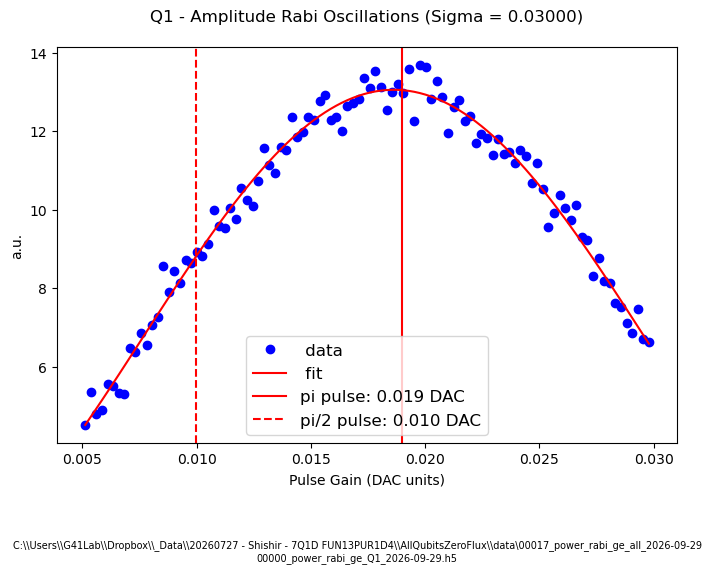

In [105]:
path = r"00017_power_rabi_ge_all_2026-09-29/00000_power_rabi_ge_Q1_2026-09-29.h5"
fig = analyze_amplitude_rabi(global_data_path, path, full_pi_offset=-0.003, half_pi_offset=-0.001, gain_cutoff_high=0.03, gain_cutoff_low=0.005, show_plot=True)#, title_append="Driving at Q1 frequency through feedline")

# every qubit of a meas_list folder in one figure
# path = r"00017_power_rabi_ge_all_2026-09-29"
# analyze_amplitude_rabi(global_data_path, path, collage=True)

### T2 Ramsey

In [183]:
@_accepts_folder
def analyze_t2_ramsey(global_data_path, filename, my_offset=0.0,
                       SS=False, ef=False,
                       plot_cal=False, show_plot=True,
                       perform_fit=True, ax=None):
    """
    T2 Ramsey fringe experiment.

    Prints the fitted T2* and the corrected qubit frequency.

    Parameters
    ----------
    global_data_path : str
        Root directory for all data files.
    filename : str
        HDF5 filename, e.g. "00001_Ramsey_ge_Q1_2026-06-07.h5".
    SS : bool
        True if single-shot normalisation data was collected.
    ef : bool
        True if this is an e-f Ramsey experiment.
    plot_cal : bool
        If True (and SS=True), plot the g/e calibration IQ blobs and fidelity.
    show_plot : bool
        If True, add a legend and display the figure.

    perform_fit : bool
        If True (default), fit the data and draw the fit. If False, only the
        data is plotted - same scaling, labels and stamp, no fit.
    ax : matplotlib Axes, optional
        Draw into this axes (one panel of a collage) instead of a new figure;
        the data-path stamp is then left to the caller.

    Returns
    -------
    fig : matplotlib Figure
        Handle to the plotted figure, for further modification.
    """
    data = _build_path(global_data_path, filename)
    print(f"Data path: {data}")

    with SlabFile(data, 'r') as f:
        delay_times = array(f['delay_times'])[0]
        delay_times -= delay_times[0]
        I = array(f['avgi'])[0]
        Q = array(f['avgq'])[0]
        amps = array(f['amps'])[0]
        config = _load_config(f)

        if SS:
            Ig = array(f['I_g'])[0]
            Qg = array(f['Q_g'])[0]
            Ie = array(f['I_e'])[0]
            Qe = array(f['Q_e'])[0]
            If_data = array(f['I_f'])[0] if ef else None
            Qf_data = array(f['Q_f'])[0] if ef else None

    if SS:
        if plot_cal:
            _plot_ge_calibration(Ig, Qg, Ie, Qe, title_prefix=_qubit_prefix(config) + "Ramsey ")
        ydata = _normalize_population(I, Q, Ig, Qg, Ie, Qe,
                                       ef=ef, If=If_data, Qf=Qf_data)
    else:
        ydata = amps

    x_ns = delay_times * 1000  # convert us -> ns

    if ax is None:
        fig = plt.figure(figsize=(8,6))
    else:
        plt.sca(ax)
        fig = ax.figure
    plt.plot(x_ns, ydata, marker='o', label='data')
    if SS:
        plt.ylabel("Qubit Population")
        plt.axhline(1, color='black', linestyle='--')
        plt.axhline(0, color='black', linestyle='--')
    else:
        plt.ylabel("a.u.")
    plt.xlabel("Delay Time (ns)")
    detuned = config.get('detuned_pulse', 'False') == 'True'
    plt.title(_qubit_prefix(config) + f"Ramsey Fringe Experiment, (Ramsey frequency = {config['ramsey_freq']:.2f} MHz{', detuned drive' if detuned else ''})"
              f"\n$\\sigma$ = {config['sigma_ge']:.2f} $\\mu$s"
              f", $\\pi / 2$ Gain = {config.get('half_pi_gain_ge', config.get('half_pi_gain', 'n/a'))}")

    if perform_fit:
        fit = Fit()
        fit_results = fit.ramsey(x_ns, ydata, plot=show_plot)
        print("  Ramsey fit results:")
        pp.pprint(fit_results)

        # Decay envelope. The fringe does not ride on a constant offset: in
        # the qualang_tools model the baseline relaxes towards final_offset as
        # exp(-t/T2), so an envelope drawn about a constant sits wrong exactly
        # where the fringe is biggest. Recover the baseline by taking the
        # oscillation back out of the fitted curve - that needs no assumption
        # about how the fit scales its initial_offset, which is not returned
        # in the same units as amp. fit_func is only valid on the points it
        # was fitted on, which is what x_ns is.
        T2 = fit_results['T2'][0]
        amp = fit_results['amp'][0]
        final_offset = fit_results['final_offset'][0]
        half_amp = (amp / 2) * np.exp(-x_ns / T2)
        baseline = fit_results['fit_func'](x_ns) - half_amp * np.cos(
            2 * np.pi * fit_results['f'][0] * x_ns + fit_results['phase'][0])
        # baseline = baseline + my_offset

        exp_lower = baseline - half_amp
        exp_upper = baseline + half_amp
        plt.plot(x_ns, exp_lower, label='fit lower bound')
        plt.plot(x_ns, exp_upper, label='fit upper bound')
        plt.plot(x_ns, baseline, color='black', linestyle='--',
                 label=f"offset = {baseline[0]:.3f})")

        # Corrected qubit frequency and the fitted starting phase, written
        # under the axes above the data-path stamp. The fit reports the phase
        # in radians; degrees, less 360, then mod 360.
        # The fringe sits at (drive - qubit). With detuned_pulse = 'True' both
        # pulses were played at qubit_freq_ge + ramsey_freq; otherwise the phase
        # advance on the second pulse stands in for that same detuning. The
        # saved qubit_freq_ge is the undetuned value either way, so the Ramsey
        # frequency is subtracted back off the same way in both cases.
        fringe = fit_results['f'][0] * 1e3
        drive_freq = config['qubit_freq_ge'] + config['ramsey_freq']
        new_freq_ge = drive_freq - fringe
        _report_config_values(config, {'qubit_freq_ge': float(new_freq_ge)})
        phase_deg = (np.degrees(fit_results['phase'][0]) - 360.0)
        breakdown = (f"  (drive {drive_freq:.3f} - fringe {fringe:.4f})" if detuned else "")
        summary = (f"Measured qubit frequency: {new_freq_ge:.6f} MHz{breakdown}      "
                   f"Starting phase: {phase_deg:.2f} deg")
        if ax is None:
            fig.text(0.5, 0.07, summary, ha='center', va='bottom', fontsize=9)
        else:
            # in a collage it goes under the panel's own x label
            ax.set_xlabel(ax.get_xlabel() + chr(10) + summary.replace("      ", chr(10)))
        if detuned:
            print(f"  Drive detuned by {config['ramsey_freq']:+g} MHz: "
                  f"{drive_freq:.6f} MHz drive - {fringe:.6f} MHz fringe")
        print(f"  Measured Qubit frequency: {new_freq_ge:.6f} MHz")
        print(f"  Starting phase:      {phase_deg:.2f} deg")
    if show_plot:
        plt.legend()
    if ax is None:
        _stamp_data_path(data)
        if show_plot:
            plt.show()

    return fig

Data path: C:\\Users\\G41Lab\\Dropbox\\_Data\\20260727 - Shishir - 7Q1D FUN13PUR1D4\\AllQubitsZeroFlux\\data\00004_Ramsey_ge_Q3_2026-09-30.h5
  --- Q3 - Ramsey g-e calibration ---


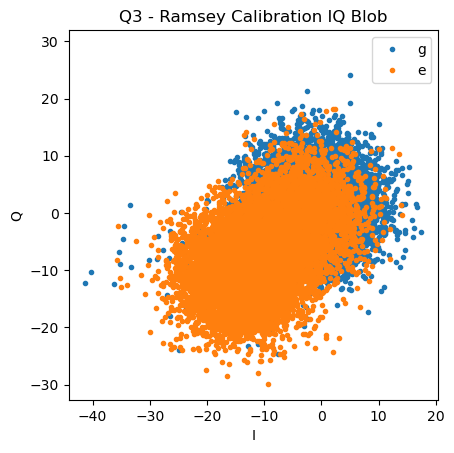

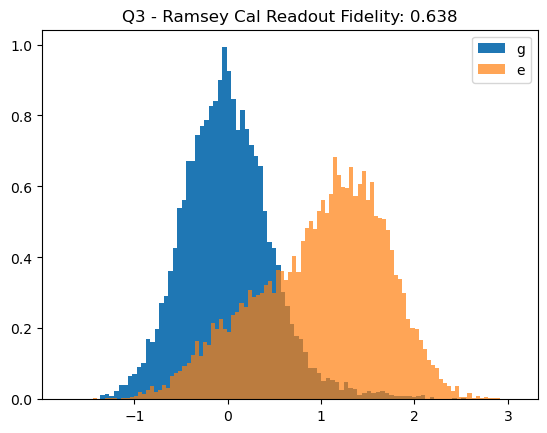

  Method 1 fidelity = 0.6377
  sigma_g = 0.4857
  sigma_e = 0.6824
  Ramsey fit results:
{'T2': [1506.1350070365115, 53.50311859002633],
 'amp': [0.9658441626337414, 0.01386063795841288],
 'f': [0.0019698740523109663, 4.010146484787649e-06],
 'final_offset': [0.5159504784673321, 0.008235393338194034],
 'fit_func': <function Fit.ramsey.<locals>.<lambda> at 0x000001D1CC2D5DA0>,
 'initial_offset': [0.4440690077070012, 0.007499483317774252],
 'phase': [0.058369788957042035, 0.01612895070127816]}
  --- config values (Q3) ---
  "qubit_freq_ge": 3740.623457494464,
  Measured Qubit frequency: 3740.623457 MHz
  Starting phase:      -356.66 deg


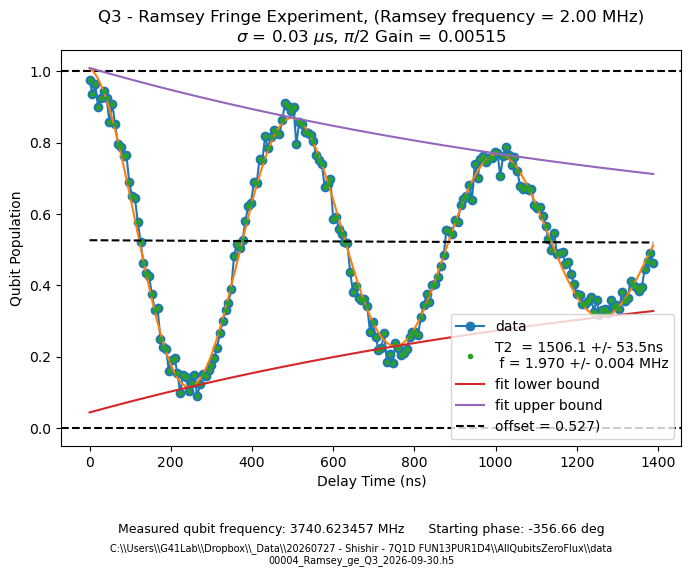

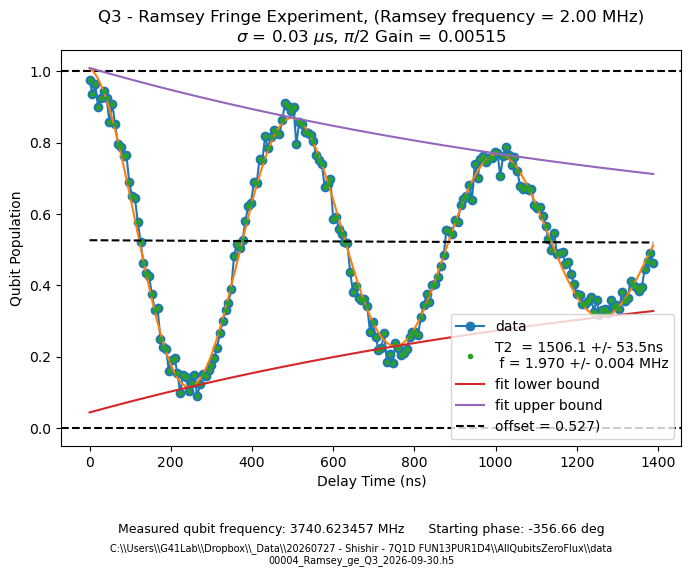

In [184]:
path = r"00004_Ramsey_ge_Q3_2026-09-30.h5"
#path = r"00015_Ramsey_ge_all_2026-09-29"
analyze_t2_ramsey(global_data_path, path, collage=True, SS = True, plot_cal=True)

#### Ramsey Frequency Calibration

In [53]:
def analyze_ramsey_freq_calibration(global_data_path, filenames,
                                     SS=False, ef=False,
                                     plot_each=False, plot_cal=False,
                                     plot_phase=False,
                                     show_plot=True, title_append="",
                                     perform_fit=True):
    """
    Ramsey frequency calibration.

    Runs the Ramsey fit on each file of a ramsey_freq_calibration_ge sweep and
    plots the fitted fringe frequency against the Ramsey frequency that was
    applied. The second Ramsey pulse has its phase advanced by
    wait_time * 360 * ramsey_freq, so a perfectly tuned qubit gives back
    exactly the frequency that was asked for, and a detuned one gives that
    plus a constant:

        measured = applied + b

    The slope is fixed at 1 rather than fitted - it is set by the phase
    advance, not by the qubit - so b is just the mean of (measured - applied),
    and that is the detuning offset to correct out. A slope that visibly is
    not 1 means something other than a constant detuning is going on, so the
    fitted slope is reported alongside for a sanity check.

    Parameters
    ----------
    global_data_path : str
        Root directory for all data files.
    filenames : list of str
        HDF5 filenames from the calibration sweep, one per applied Ramsey
        frequency, e.g. ["00000_ramsey_freq_calibration_ge_Q1_...h5", ...].
    SS : bool
        True if single-shot normalisation data was collected.
    ef : bool
        True if these are e-f Ramsey experiments.
    plot_each : bool
        If True, also run analyze_t2_ramsey on every file, so each individual
        fringe and its fit can be eyeballed.
    plot_cal : bool
        Passed through to analyze_t2_ramsey when plot_each is True.
    plot_phase : bool
        If True, also make a second figure of the fitted Ramsey phase against
        the applied frequency. The fit reports the phase in radians; it is
        converted to degrees and 360 subtracted, which puts a phase sitting
        just short of a full turn onto a small signed offset around zero.
    show_plot : bool
        If True, add a legend and display the figure.
    title_append : str
        Extra text appended to the plot title.

    perform_fit : bool
        Accepted for consistency with the other analysis functions, but
        must stay True here: the plotted quantity is itself a fit result.
    Returns
    -------
    fig : matplotlib Figure
        Handle to the summary figure.
    fig_phase : matplotlib Figure or None
        Handle to the phase figure, or None when plot_phase is False.
    applied : 1D np.array
        Applied Ramsey frequency (MHz) for each file, in the order plotted.
    measured : 1D np.array
        Fitted fringe frequency (MHz) for each file, in the order plotted.
    phases : 1D np.array
        Fitted phase (degrees, less 360) for each file, in the order plotted.
    """
    if isinstance(filenames, str):
        raise TypeError(
            "filenames must be a list, not a single string - wrap it in one: "
            f'["{filenames}"]')

    if not perform_fit:
        raise ValueError(
            "perform_fit=False has nothing to plot here - the y axis of this "
            "calibration is the fitted fringe frequency of each file, not raw "
            "data. Use analyze_t2_ramsey with perform_fit=False to look at an "
            "individual fringe.")

    applied, measured, phases, stamp_lines = [], [], [], []
    config = {}

    for fname in filenames:
        data = _build_path(global_data_path, fname)
        print(f"Data path: {data}")

        with SlabFile(data, 'r') as f:
            delay_times = array(f['delay_times'])[0]
            delay_times = delay_times - delay_times[0]
            I = array(f['avgi'])[0]
            Q = array(f['avgq'])[0]
            amps = array(f['amps'])[0]
            cfg = _load_config(f)

            if SS:
                Ig = array(f['I_g'])[0]
                Qg = array(f['Q_g'])[0]
                Ie = array(f['I_e'])[0]
                Qe = array(f['Q_e'])[0]
                If_data = array(f['I_f'])[0] if ef else None
                Qf_data = array(f['Q_f'])[0] if ef else None

        if not config:
            config = cfg

        ydata = (_normalize_population(I, Q, Ig, Qg, Ie, Qe,
                                        ef=ef, If=If_data, Qf=Qf_data)
                 if SS else amps)

        # Fit the fringe. x in ns puts fit_results['f'] in GHz, as
        # analyze_t2_ramsey assumes when it corrects the qubit frequency.
        x_ns = delay_times * 1000
        fit_results = Fit().ramsey(x_ns, ydata, plot=False)
        f_meas = fit_results['f'][0] * 1e3   # GHz -> MHz
        f_app = cfg['ramsey_freq']
        # The fit reports the phase in radians, near a full turn; degrees
        # less 360 puts it on a small signed offset about zero.
        phase_deg = np.degrees(fit_results['phase'][0]) - 360.0

        applied.append(f_app)
        measured.append(f_meas)
        phases.append(phase_deg)
        stamp_lines.append(f"{data}  (applied = {f_app} MHz)")
        print(f"  Applied {f_app} MHz -> measured {f_meas:.4f} MHz "
              f"(difference {f_meas - f_app:+.4f} MHz), "
              f"phase {phase_deg:+.2f} deg")

        if plot_each:
            analyze_t2_ramsey(global_data_path, fname, SS=SS, ef=ef,
                              plot_cal=plot_cal, show_plot=show_plot)

    applied = np.array(applied, dtype=float)
    measured = np.array(measured, dtype=float)
    phases = np.array(phases, dtype=float)

    order = np.argsort(applied)
    applied, measured = applied[order], measured[order]
    phases = phases[order]
    stamp_lines = [stamp_lines[i] for i in order]

    # Slope is fixed at 1, so the intercept is just the mean difference.
    offset = float(np.mean(measured - applied))
    spread = (float(np.std(measured - applied, ddof=1))
              if len(applied) > 1 else float('nan'))

    # Reported only as a sanity check on the fixed-slope assumption.
    if len(applied) > 1:
        free_slope, free_intercept = np.polyfit(applied, measured, 1)
    else:
        free_slope = free_intercept = float('nan')

    fig, ax = plt.subplots(figsize=(12,8))
    ax.plot(applied, measured, 'o', color='tab:blue', markersize=7,
            label='measured')

    x_line = np.linspace(applied.min(), applied.max(), 100)
    ax.plot(x_line, x_line + offset, 'r-', linewidth=1.5,
            label=f'y = x + b,  b = {offset:+.4f} MHz')
    ax.plot(x_line, x_line, color='gray', linestyle='--', linewidth=1,
            label='y = x (no detuning)')

    ax.set_xlabel("Applied Ramsey Frequency (MHz)")
    ax.set_ylabel("Measured Fringe Frequency (MHz)")
    ax.set_title(_qubit_prefix(config) + "Ramsey Frequency Calibration"
                 + chr(10) + title_append)

    print("")
    print(f"  Offset b:            {offset:+.6f} MHz  "
          f"(subtract from the qubit frequency)")
    print(f"  Scatter about y=x+b: {spread:.6f} MHz")
    print(f"  Free-fit slope:      {free_slope:.4f} "
          f"(sanity check, should be near 1)")
    if 'qubit_freq_ge' in config:
        print(f"  Corrected qubit frequency: "
              f"{config['qubit_freq_ge'] - offset:.6f} MHz")

    if show_plot:
        ax.legend()
    _stamp_data_path(chr(10).join(stamp_lines), fig)
    if show_plot:
        plt.show()

    # ----- Optional second figure: fitted phase ----- #
    fig_phase = None
    if plot_phase:
        fig_phase, ax_p = plt.subplots(figsize=(12,8))
        ax_p.plot(applied, phases, 'o-', color='tab:green', markersize=7,
                  label='fitted phase')
        ax_p.axhline(0, color='black', linestyle='--', linewidth=1)
        ax_p.set_xlabel("Applied Ramsey Frequency (MHz)")
        ax_p.set_ylabel("Fitted Phase - 360 (degrees)")
        ax_p.set_title(_qubit_prefix(config) + "Ramsey Fitted Phase"
                       + chr(10) + title_append)

        print("")
        print(f"  Mean phase:    {np.mean(phases):+.3f} deg")
        if len(phases) > 1:
            print(f"  Phase spread:  {np.std(phases, ddof=1):.3f} deg")

        if show_plot:
            ax_p.legend()
        _stamp_data_path(chr(10).join(stamp_lines), fig_phase)
        if show_plot:
            plt.show()

    return fig, fig_phase, applied, measured, phases

In [ ]:
files =sequential_filenames("00000_ramsey_freq_calibration_ge_Q1_2026-09-17.h5", 6)
analyze_ramsey_freq_calibration(global_data_path, files, plot_each=True, plot_phase=True, SS=True, perform_fit=True)

#### Ramsey Phase Calibration/ MIST detection???

In [ ]:
def analyze_ramsey_ro_length(global_data_path, folder_name,
                              SS=False, ef=False,
                              plot_each=False, plot_cal=False,
                              show_plot=True, title_append="",
                              perform_fit=True):
    """
    Ramsey fitted phase against readout duration.

    Reads a folder written by 006b_ramsey_ro_length_ge.py - one file per
    readout length, all at the same Ramsey frequency - fits each fringe and
    plots the fitted phase against the ro_length that produced it.

    The fit reports the phase in radians sitting just short of a full turn, so
    it is converted to degrees and 360 subtracted, the same convention
    analyze_ramsey_freq_calibration uses, which puts it on a small signed
    offset about zero.

    Parameters
    ----------
    global_data_path : str
        Root directory for all data files.
    folder_name : str
        Subfolder holding the scan, e.g.
        "00000_ramsey_ro_length_ge_Q1_2026-09-10". Every .h5 in it is used.
    SS : bool
        True if single-shot normalisation data was collected.
    ef : bool
        True if these are e-f Ramsey experiments.
    plot_each : bool
        If True, also run analyze_t2_ramsey on every file, so each individual
        fringe and its fit can be eyeballed.
    plot_cal : bool
        Passed through to analyze_t2_ramsey when plot_each is True.
    show_plot : bool
        If True, add a legend and display the figure.
    title_append : str
        Extra text appended to the plot title.
    perform_fit : bool
        Accepted for consistency with the other analysis functions, but must
        stay True here: the plotted quantity is itself a fit result.

    Returns
    -------
    fig : matplotlib Figure
        Handle to the phase figure.
    ro_lengths : 1D np.array
        Readout duration (us) for each file, in the order plotted.
    phases : 1D np.array
        Fitted phase (degrees, less 360) for each file, in the order plotted.
    freqs : 1D np.array
        Fitted fringe frequency (MHz) for each file, in the order plotted.
    """
    if not perform_fit:
        raise ValueError(
            "perform_fit=False has nothing to plot here - the y axis of this "
            "scan is the fitted phase of each file, not raw data. Use "
            "analyze_t2_ramsey with perform_fit=False to look at an "
            "individual fringe.")

    folder_path = os.path.join(global_data_path, folder_name)
    print(f"Data folder: {folder_path}")

    files = sorted(f for f in os.listdir(folder_path) if f.endswith('.h5'))
    if not files:
        raise ValueError(f"No .h5 files found in {folder_path}")

    ro_lengths, phases, freqs = [], [], []
    config = {}

    for fname in files:
        data = os.path.join(folder_path, fname)

        with SlabFile(data, 'r') as f:
            delay_times = array(f['delay_times'])[0]
            delay_times = delay_times - delay_times[0]
            I = array(f['avgi'])[0]
            Q = array(f['avgq'])[0]
            amps = array(f['amps'])[0]
            cfg = _load_config(f)

            if SS:
                Ig = array(f['I_g'])[0]
                Qg = array(f['Q_g'])[0]
                Ie = array(f['I_e'])[0]
                Qe = array(f['Q_e'])[0]
                If_data = array(f['I_f'])[0] if ef else None
                Qf_data = array(f['Q_f'])[0] if ef else None

        if not config:
            config = cfg

        ydata = (_normalize_population(I, Q, Ig, Qg, Ie, Qe,
                                        ef=ef, If=If_data, Qf=Qf_data)
                 if SS else amps)

        # x in ns puts fit_results['f'] in GHz, as analyze_t2_ramsey assumes.
        x_ns = delay_times * 1000
        fit_results = Fit().ramsey(x_ns, ydata, plot=False)
        phase_deg = np.degrees(fit_results['phase'][0]) - 360.0
        f_meas = fit_results['f'][0] * 1e3   # GHz -> MHz
        ro = cfg['ro_length']

        ro_lengths.append(ro)
        phases.append(phase_deg)
        freqs.append(f_meas)
        print(f"  ro_length {ro} us -> phase {phase_deg:+.2f} deg, "
              f"fringe {f_meas:.4f} MHz")

        if plot_each:
            analyze_t2_ramsey(folder_path, fname, SS=SS, ef=ef,
                              plot_cal=plot_cal, show_plot=show_plot)

    ro_lengths = np.array(ro_lengths, dtype=float)
    phases = np.array(phases, dtype=float)
    freqs = np.array(freqs, dtype=float)

    order = np.argsort(ro_lengths)
    ro_lengths, phases, freqs = ro_lengths[order], phases[order], freqs[order]

    fig, ax = plt.subplots(figsize=(12,8))
    ax.plot(ro_lengths, phases, 'o-', color='tab:green', markersize=7,
            label='fitted phase')
    ax.axhline(0, color='black', linestyle='--', linewidth=1)
    ax.set_xlabel("Readout Pulse Length (us)")
    ax.set_ylabel("Fitted Phase - 360 (degrees)")
    ramsey_freq = config.get('ramsey_freq', None)
    freq_note = (f" (Ramsey frequency = {ramsey_freq} MHz)"
                 if ramsey_freq is not None else "")
    ax.set_title(_qubit_prefix(config) + "Ramsey Phase vs Readout Duration"
                 + freq_note + chr(10) + title_append)

    print("")
    print(f"  Files:          {len(files)}")
    print(f"  ro_length:      {ro_lengths[0]:.3f} to {ro_lengths[-1]:.3f} us")
    print(f"  Phase span:     {np.max(phases) - np.min(phases):.3f} deg")
    print(f"  Mean phase:     {np.mean(phases):+.3f} deg")
    if len(phases) > 1:
        print(f"  Phase spread:   {np.std(phases, ddof=1):.3f} deg")
        print(f"  Fringe spread:  {np.std(freqs, ddof=1):.5f} MHz "
              f"(should be flat - the qubit does not know about ro_length)")

    if show_plot:
        ax.legend()
    _stamp_data_path(folder_path, fig)
    if show_plot:
        plt.show()

    return fig, ro_lengths, phases, freqs

In [ ]:
data_folder = "00000_ramsey_ro_length_ge_Q1_2026-09-10"
analyze_ramsey_ro_length(global_data_path, data_folder, plot_each=True)

#### Ramsey Phase Error Amplification

In [185]:
def analyze_ramsey_phase_error(global_data_path, folder_name,
                                SS=False, ef=False,
                                plot_each=False, plot_cal=False,
                                show_plot=True, title_append="",
                                perform_fit=True, custom_range = None, unwrap=False):
    """
    Ramsey fringe phase against the number of inserted identity pulses.

    Reads a folder written by 006c_ramsey_phase_error_ge.py - one Ramsey file
    per N, where N identity blocks (X90 then X90 shifted by 180 deg) sit after
    the first pi/2 pulse - fits each fringe, and plots the fitted phase against
    the number of extra pulses, 2N. A phase error between the two pulses of an
    identity rotates the equatorial state by a small angle, and N of them stack
    it, so the fringe phase should move linearly with N: the slope of the line
    is the phase error per pulse, and its intercept is the plain Ramsey phase
    (N = 0).

    Each fringe is fitted with the standard Ramsey model (Fit().ramsey, the
    same as analyze_t2_ramsey) and the phase taken from that fit. The model
    needs two or more fringe periods to converge, so the scan should be taken
    with N_PERIODS >= 2 in 006c. Phases use the same convention as the other
    Ramsey analyses (degrees, less 360), exactly as fitted - no unwrapping.

    Parameters
    ----------
    global_data_path : str
        Root directory for all data files.
    folder_name : str
        Subfolder holding the scan, e.g.
        "00000_ramsey_phase_error_ge_Q1_2026-09-17". Every .h5 in it is used.
    SS : bool
        True if single-shot normalisation data was collected.
    ef : bool
        True if these are e-f Ramsey experiments.
    plot_each : bool
        If True, also run analyze_t2_ramsey on every file, so each individual
        fringe and its fit can be eyeballed.
    plot_cal : bool
        Passed through to analyze_t2_ramsey when plot_each is True.
    show_plot : bool
        If True, add a legend and display the figure.
    title_append : str
        Extra text appended to the plot title.
    perform_fit : bool
        Accepted for consistency with the other analysis functions, but must
        stay True here: the plotted quantity is itself a fit result.
    custom_range : [N_min, N_max], optional
        Only use the files whose N (number of identity blocks) lies in this
        range, ends included, e.g. [0, 2] to stop before the phase wraps.
        Files outside it are not fitted or plotted. Default: every file.

    Returns
    -------
    fig : matplotlib Figure
        Handle to the phase-vs-pulses figure.
    fig_curves : matplotlib Figure
        Handle to the composite of every fringe with its fit, one colour per
        N, each labelled with its fitted phase.
    n_pulses : 1D np.array
        Number of extra pulses (2N) for each file, in the order plotted.
    phases : 1D np.array
        Fitted phase (degrees, less 360) for each file, in the order plotted.
    freqs : 1D np.array
        Fitted fringe frequency (MHz) for each file, in the order plotted.
    """
    if not perform_fit:
        raise ValueError(
            "perform_fit=False has nothing to plot here - the y axis of this "
            "scan is the fitted phase of each file, not raw data. Use "
            "analyze_t2_ramsey with perform_fit=False to look at an "
            "individual fringe.")

    folder_path = os.path.join(global_data_path, folder_name)
    print(f"Data folder: {folder_path}")

    files = sorted(f for f in os.listdir(folder_path) if f.endswith('.h5'))
    if not files:
        raise ValueError(f"No .h5 files found in {folder_path}")

    Ns, phases, freqs, traces = [], [], [], []
    config = {}

    for fname in files:
        data = os.path.join(folder_path, fname)

        with SlabFile(data, 'r') as f:
            delay_times = array(f['delay_times'])[0]
            delay_times = delay_times - delay_times[0]
            I = array(f['avgi'])[0]
            Q = array(f['avgq'])[0]
            amps = array(f['amps'])[0]
            cfg = _load_config(f)

            if SS:
                Ig = array(f['I_g'])[0]
                Qg = array(f['Q_g'])[0]
                Ie = array(f['I_e'])[0]
                Qe = array(f['Q_e'])[0]
                If_data = array(f['I_f'])[0] if ef else None
                Qf_data = array(f['Q_f'])[0] if ef else None

        N = cfg['N']
        if custom_range is not None and not custom_range[0] <= N <= custom_range[1]:
            continue

        if not config:
            config = cfg

        ydata = (_normalize_population(I, Q, Ig, Qg, Ie, Qe,
                                        ef=ef, If=If_data, Qf=Qf_data)
                 if SS else amps)

        # Standard Ramsey fit, as analyze_t2_ramsey does. x in ns puts
        # fit_results['f'] in GHz, as elsewhere.
        x_ns = delay_times * 1000
        try:
            fit_results = Fit().ramsey(x_ns, ydata, plot=False)
        except RuntimeError as e:
            raise RuntimeError(
                f"{fname}: the Ramsey fit did not converge ({e}). It needs two "
                "or more fringe periods in the window - check N_PERIODS in "
                "006c_ramsey_phase_error_ge.py.") from e
        phase_deg = np.degrees(fit_results['phase'][0])
        f_meas = fit_results['f'][0] * 1e3   # GHz -> MHz

        Ns.append(N)
        phases.append(phase_deg)
        freqs.append(f_meas)
        # fit_func is only valid on the points it was fitted on, so keep the
        # curve evaluated there for the composite figure.
        traces.append((x_ns, ydata, fit_results['fit_func'](x_ns)))
        print(f"  N = {N} ({2 * N} extra pulses) -> phase {phase_deg:+.2f} deg, "
              f"fringe {f_meas:.4f} MHz, T2* {fit_results['T2'][0] / 1e3:.2f} us")

        if plot_each:
            analyze_t2_ramsey(folder_path, fname, SS=SS, ef=ef,
                              plot_cal=plot_cal, show_plot=show_plot)

    if not Ns:
        raise ValueError(f"No files with N in {custom_range} in {folder_path}")
    Ns = np.array(Ns, dtype=int)
    phases = np.array(phases, dtype=float)
    freqs = np.array(freqs, dtype=float)

    order = np.argsort(Ns)
    Ns, phases, freqs = Ns[order], phases[order], freqs[order]
    traces = [traces[i] for i in order]
    n_pulses = 2 * Ns
    phases[0] = phases[0] + 360  # first point is just short of a full turn


    if unwrap:
        # Unwrap the phases so they are continuous, then subtract 360 to put
        # them on a small signed offset about zero. This is only for the
        # linear fit; the plotted points are still the raw fitted phases.
        phases = np.unwrap(phases, period=180)

    # Phase error per pulse from a straight line through the points; the
    # intercept is the plain Ramsey phase.
    if len(n_pulses) > 1:
        slope, intercept = np.polyfit(n_pulses, phases, 1)
        resid = phases - (slope * n_pulses + intercept)
        rms = float(np.sqrt(np.mean(resid ** 2)))
    else:
        slope, intercept, rms = float('nan'), float(phases[0]), float('nan')

    fig, ax = plt.subplots(figsize=(12,8))
    ax.plot(n_pulses, phases, 'o', color='tab:blue', markersize=8,
            label='fitted phase')
    if len(n_pulses) > 1:
        x_line = np.linspace(n_pulses.min(), n_pulses.max(), 100)
        ax.plot(x_line, slope * x_line + intercept, 'r-', linewidth=1.5,
                label=f'{slope:+.3f} deg / pulse  (N = 0: {intercept:+.2f} deg)')
    ax.set_xlabel("Number of Extra Pulses (2N)")
    ax.set_ylabel("Fitted Ramsey Phase (degrees)")
    ax.set_xticks(n_pulses)
    ramsey_freq = config.get('ramsey_freq', None)
    freq_note = (f" (Ramsey frequency = {ramsey_freq} MHz)"
                 if ramsey_freq is not None else "")
    ax.set_title(_qubit_prefix(config) + "Ramsey Phase Error Amplification"
                 + freq_note + chr(10) + title_append)

    print("")
    print(f"  Files:                  {len(Ns)} of {len(files)}"
          + (f" (N in {list(custom_range)})" if custom_range is not None else ""))
    print(f"  Phase error per pulse:  {slope:+.4f} deg")
    print(f"  Phase error per identity (X90, X90_neg): {2 * slope:+.4f} deg")
    print(f"  N = 0 phase (intercept): {intercept:+.3f} deg")
    print(f"  RMS residual from line: {rms:.3f} deg")
    if len(freqs) > 1:
        print(f"  Fringe spread:          {np.std(freqs, ddof=1):.5f} MHz "
              f"(should be flat - the identities do not change the detuning)")

    error_note = (f"Phase error per pulse: {slope:+.3f} deg      "
                  f"per identity (X90, X90_neg): {2 * slope:+.3f} deg      "
                  f"fringe: {np.mean(freqs):.4f} MHz")

    if show_plot:
        ax.legend()
    _stamp_data_path(folder_path, fig, footnote=error_note)
    if show_plot:
        plt.show()

    # ----- Composite: every fringe on one axes, labelled by its phase ----- #
    fig_curves, ax_c = plt.subplots(figsize=(12,8))
    colors = plt.cm.viridis(np.linspace(0, 0.9, len(traces)))
    for (x, y, y_fit), N, ph_deg, col in zip(traces, Ns, phases, colors):
        ax_c.plot(x, y, 'o', color=col, markersize=4,
                  label=f"N = {N} ({2 * N} pulses): {ph_deg:+.1f} deg")
        ax_c.plot(x, y_fit, '-', color=col, linewidth=1.2)
    if SS:
        ax_c.set_ylabel("Qubit Population")
        ax_c.axhline(1, color='black', linestyle='--', linewidth=1)
        ax_c.axhline(0, color='black', linestyle='--', linewidth=1)
    else:
        ax_c.set_ylabel("a.u.")
    ax_c.set_xlabel("Delay Time (ns)")
    ax_c.set_title(_qubit_prefix(config) + "Ramsey Phase Error Amplification - fringes"
                   + freq_note + chr(10) + title_append)
    if show_plot:
        ax_c.legend()
    _stamp_data_path(folder_path, fig_curves, footnote=error_note)
    if show_plot:
        plt.show()

    return fig, fig_curves, n_pulses, phases, freqs

Data folder: C:\\Users\\G41Lab\\Dropbox\\_Data\\20260727 - Shishir - 7Q1D FUN13PUR1D4\\AllQubitsZeroFlux\\data\00019_ramsey_phase_error_ge_Q3_2026-09-30
  N = 0 (0 extra pulses) -> phase +2.00 deg, fringe 1.9557 MHz, T2* 1.58 us
Data path: C:\\Users\\G41Lab\\Dropbox\\_Data\\20260727 - Shishir - 7Q1D FUN13PUR1D4\\AllQubitsZeroFlux\\data\00019_ramsey_phase_error_ge_Q3_2026-09-30\00000_ramsey_phase_error_ge_Q3_2026-09-30.h5
  --- Q3 - Ramsey g-e calibration ---


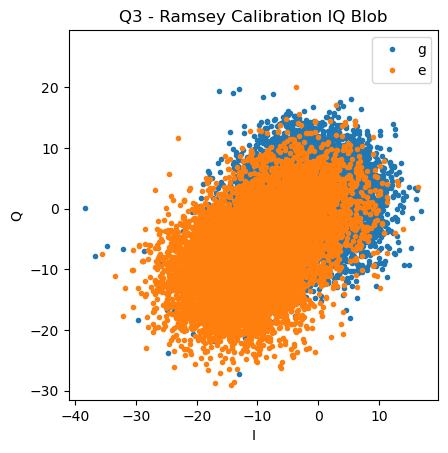

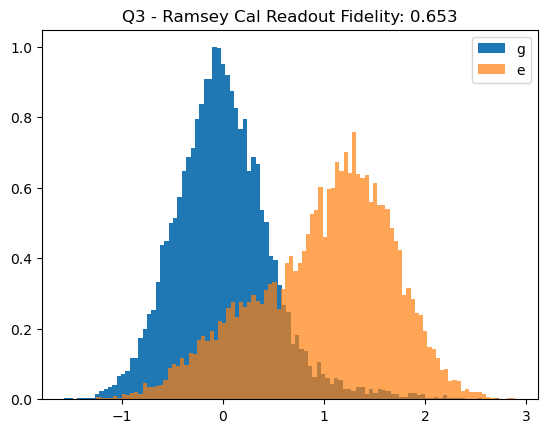

  Method 1 fidelity = 0.6530
  sigma_g = 0.4795
  sigma_e = 0.6707
  Ramsey fit results:
{'T2': [1580.2360603262493, 35.25014271781594],
 'amp': [1.0122512380619606, 0.010981832447299356],
 'f': [0.00195566206270273, 2.5033745034729468e-06],
 'final_offset': [0.5192978781944959, 0.004977882854862792],
 'fit_func': <function Fit.ramsey.<locals>.<lambda> at 0x000001D1D49B8F40>,
 'initial_offset': [0.459682498102574, 0.005906380083066478],
 'phase': [0.03489244213031731, 0.012082933446126898]}
  --- config values (Q3) ---
  "qubit_freq_ge": 3740.6376694840724,
  Measured Qubit frequency: 3740.637669 MHz
  Starting phase:      -358.00 deg


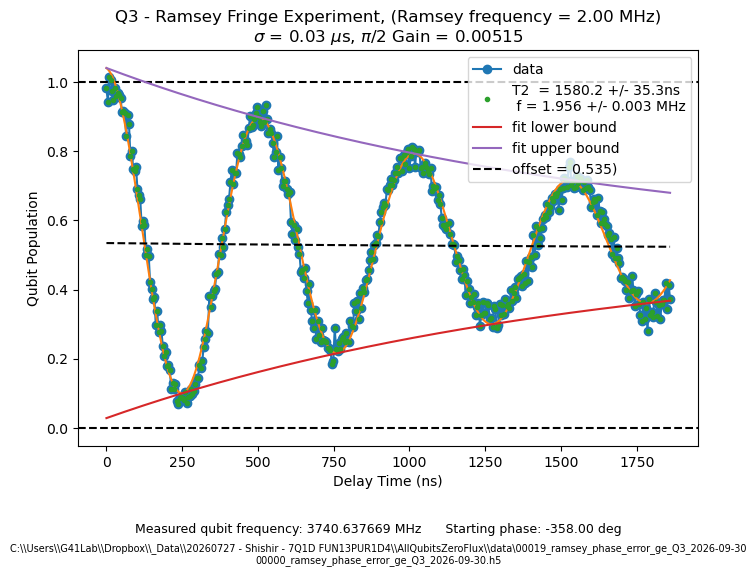

  N = 1 (2 extra pulses) -> phase +341.02 deg, fringe 1.9487 MHz, T2* 1.54 us
Data path: C:\\Users\\G41Lab\\Dropbox\\_Data\\20260727 - Shishir - 7Q1D FUN13PUR1D4\\AllQubitsZeroFlux\\data\00019_ramsey_phase_error_ge_Q3_2026-09-30\00001_ramsey_phase_error_ge_Q3_2026-09-30.h5
  --- Q3 - Ramsey g-e calibration ---


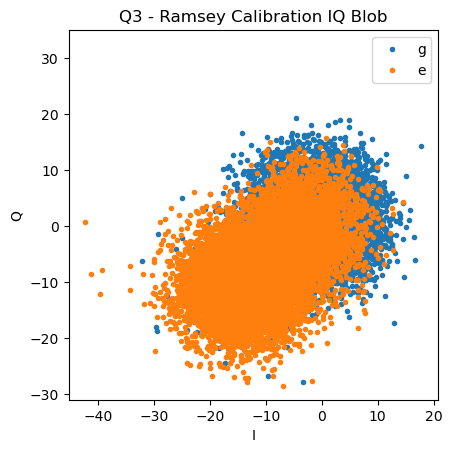

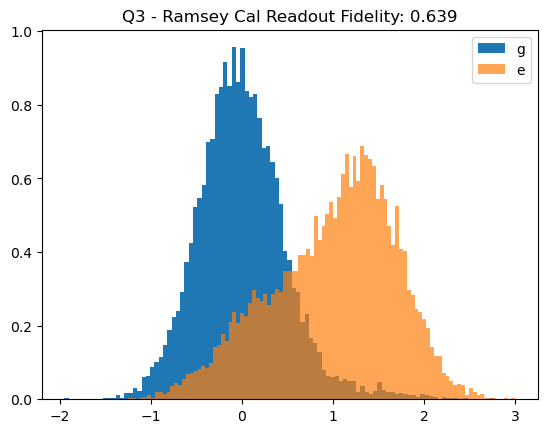

  Method 1 fidelity = 0.6395
  sigma_g = 0.4867
  sigma_e = 0.6788
  Ramsey fit results:
{'T2': [1537.2155446899546, 40.38122324359387],
 'amp': [0.8734675953837717, 0.01119763870290965],
 'f': [0.0019487407688563987, 3.1873231757901876e-06],
 'final_offset': [0.5119833259071802, 0.005220141844381622],
 'fit_func': <function Fit.ramsey.<locals>.<lambda> at 0x000001D1D6743B00>,
 'initial_offset': [0.4949657692937325, 0.007719016093440752],
 'phase': [5.951986373641582, 0.015389967474257213]}
  --- config values (Q3) ---
  "qubit_freq_ge": 3740.6445907779184,
  Measured Qubit frequency: 3740.644591 MHz
  Starting phase:      -18.98 deg


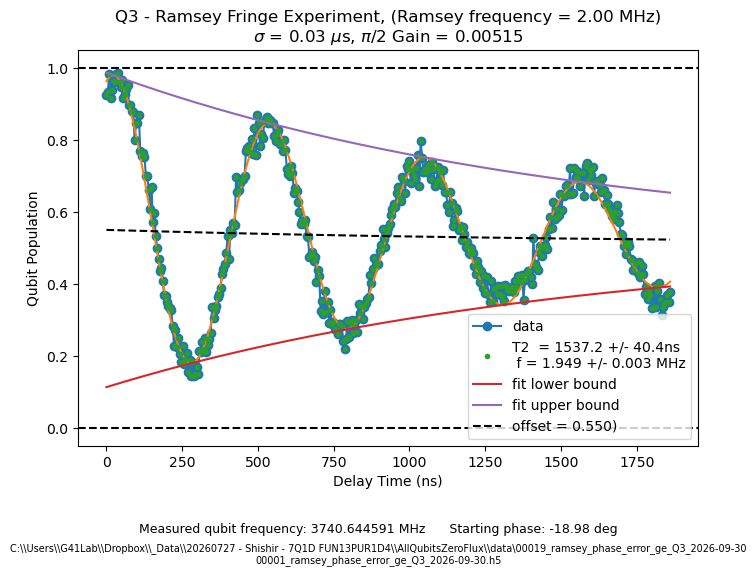

  N = 2 (4 extra pulses) -> phase +319.41 deg, fringe 1.9391 MHz, T2* 1.63 us
Data path: C:\\Users\\G41Lab\\Dropbox\\_Data\\20260727 - Shishir - 7Q1D FUN13PUR1D4\\AllQubitsZeroFlux\\data\00019_ramsey_phase_error_ge_Q3_2026-09-30\00002_ramsey_phase_error_ge_Q3_2026-09-30.h5
  --- Q3 - Ramsey g-e calibration ---


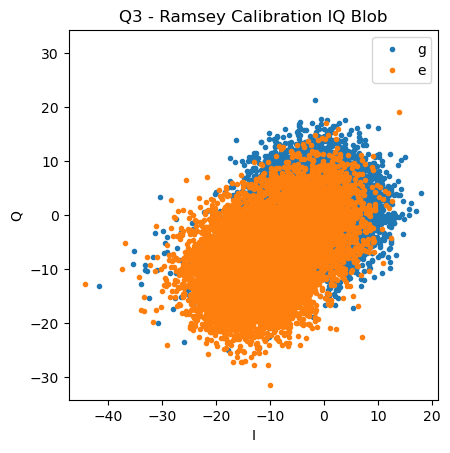

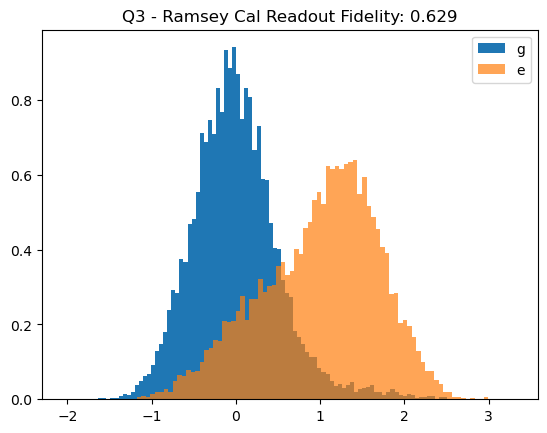

  Method 1 fidelity = 0.6286
  sigma_g = 0.5218
  sigma_e = 0.6917
  Ramsey fit results:
{'T2': [1627.1697640048153, 62.29166503061016],
 'amp': [0.6247506823606591, 0.011138141258532156],
 'f': [0.0019391119954569379, 4.152049133930143e-06],
 'final_offset': [0.5227476827944116, 0.005368605972498713],
 'fit_func': <function Fit.ramsey.<locals>.<lambda> at 0x000001D1D6D56660>,
 'initial_offset': [0.4976535551435746, 0.010575430266226598],
 'phase': [5.574772525959206, 0.02062007616766785]}
  --- config values (Q3) ---
  "qubit_freq_ge": 3740.654219551318,
  Measured Qubit frequency: 3740.654220 MHz
  Starting phase:      -40.59 deg


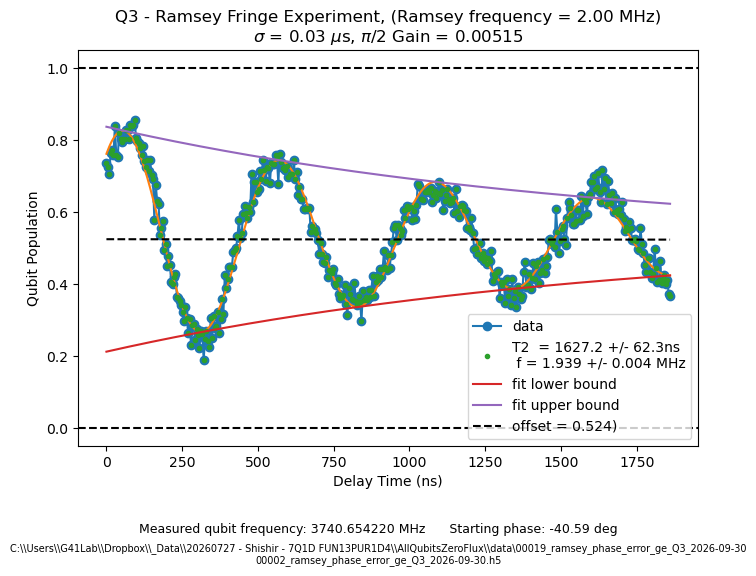

  N = 3 (6 extra pulses) -> phase +276.79 deg, fringe 1.9148 MHz, T2* 1.47 us
Data path: C:\\Users\\G41Lab\\Dropbox\\_Data\\20260727 - Shishir - 7Q1D FUN13PUR1D4\\AllQubitsZeroFlux\\data\00019_ramsey_phase_error_ge_Q3_2026-09-30\00003_ramsey_phase_error_ge_Q3_2026-09-30.h5
  --- Q3 - Ramsey g-e calibration ---


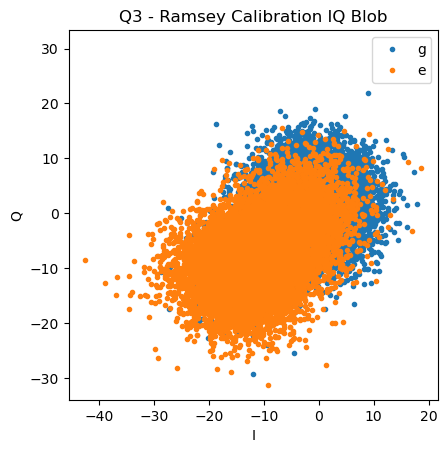

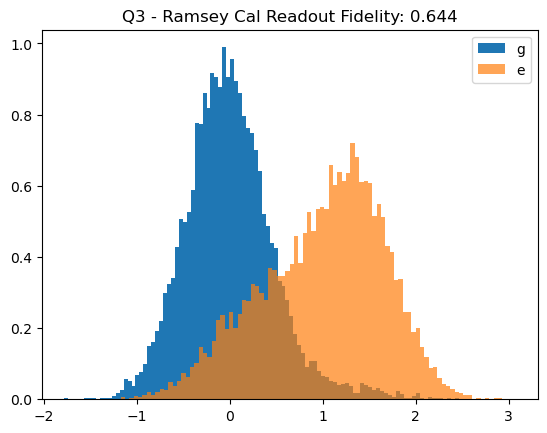

  Method 1 fidelity = 0.6443
  sigma_g = 0.4802
  sigma_e = 0.6575
  Ramsey fit results:
{'T2': [1469.762722455591, 74.32434563747421],
 'amp': [0.4490814286428897, 0.011517853990858857],
 'f': [0.0019148253149113398, 4.900918175001718e-06],
 'final_offset': [0.5380750489078431, 0.004213693793500587],
 'fit_func': <function Fit.ramsey.<locals>.<lambda> at 0x000001D1D847B6A0>,
 'initial_offset': [0.4823462923352789, 0.014109173099131773],
 'phase': [4.830825548185745, 0.02313730054019086]}
  --- config values (Q3) ---
  "qubit_freq_ge": 3740.6785062318636,
  Measured Qubit frequency: 3740.678506 MHz
  Starting phase:      -83.21 deg


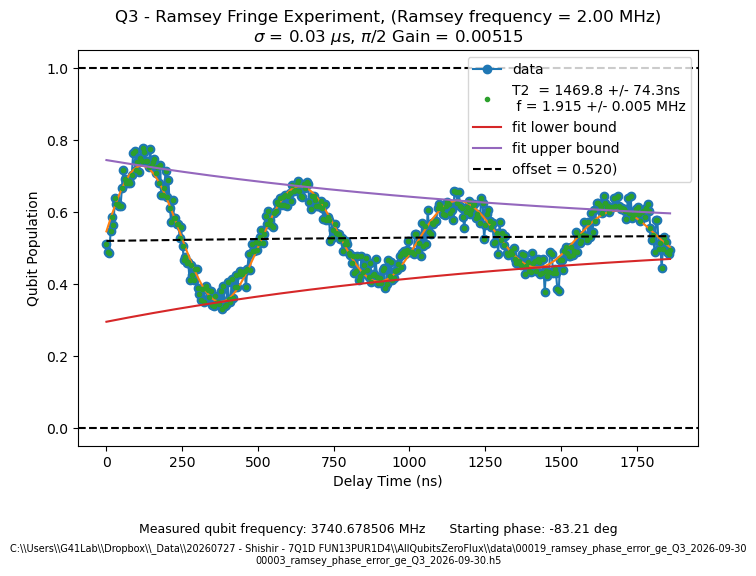

  N = 4 (8 extra pulses) -> phase +223.31 deg, fringe 1.8765 MHz, T2* 2.02 us
Data path: C:\\Users\\G41Lab\\Dropbox\\_Data\\20260727 - Shishir - 7Q1D FUN13PUR1D4\\AllQubitsZeroFlux\\data\00019_ramsey_phase_error_ge_Q3_2026-09-30\00004_ramsey_phase_error_ge_Q3_2026-09-30.h5
  --- Q3 - Ramsey g-e calibration ---


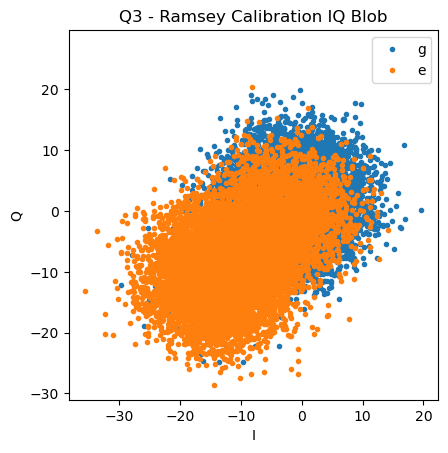

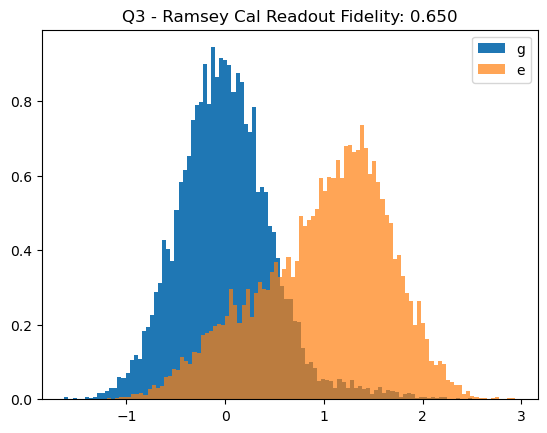

  Method 1 fidelity = 0.6501
  sigma_g = 0.4793
  sigma_e = 0.6572
  Ramsey fit results:
{'T2': [2016.4056274958791, 124.51464330962838],
 'amp': [0.39791703190507194, 0.010505028118351854],
 'f': [0.0018764819993903241, 4.823068823204062e-06],
 'final_offset': [0.5468023158127564, 0.005639329901315233],
 'fit_func': <function Fit.ramsey.<locals>.<lambda> at 0x000001D1D83998A0>,
 'initial_offset': [0.47850244442273937, 0.013768855298845724],
 'phase': [3.897487662611179, 0.02413397177327986]}
  --- config values (Q3) ---
  "qubit_freq_ge": 3740.7168495473848,
  Measured Qubit frequency: 3740.716850 MHz
  Starting phase:      -136.69 deg


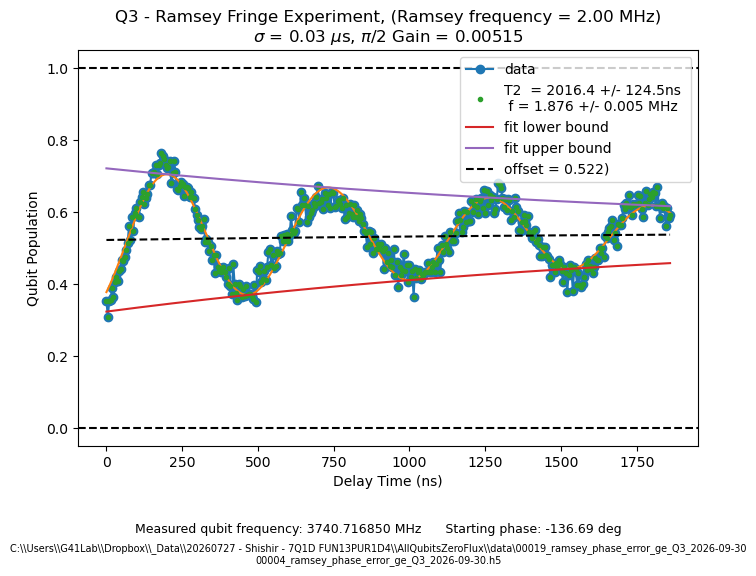

  N = 5 (10 extra pulses) -> phase +193.08 deg, fringe 1.8798 MHz, T2* 3.71 us
Data path: C:\\Users\\G41Lab\\Dropbox\\_Data\\20260727 - Shishir - 7Q1D FUN13PUR1D4\\AllQubitsZeroFlux\\data\00019_ramsey_phase_error_ge_Q3_2026-09-30\00005_ramsey_phase_error_ge_Q3_2026-09-30.h5
  --- Q3 - Ramsey g-e calibration ---


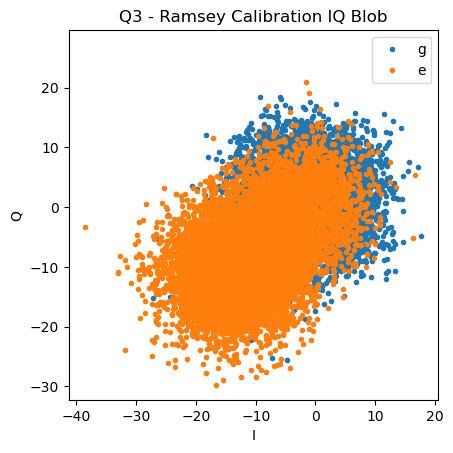

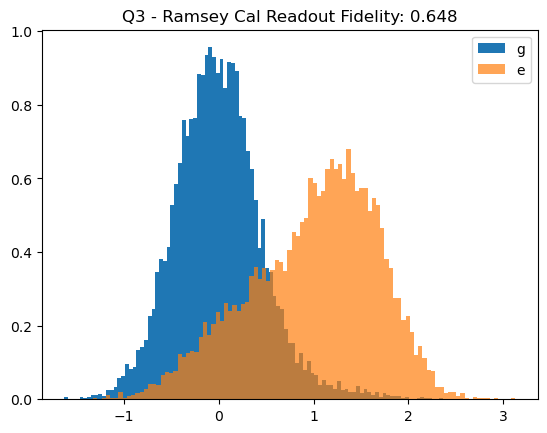

  Method 1 fidelity = 0.6484
  sigma_g = 0.4611
  sigma_e = 0.6718
  Ramsey fit results:
{'T2': [3708.275176193364, 374.2049402678394],
 'amp': [0.3985468745974533, 0.01036902354858172],
 'f': [0.0018797648200663132, 4.726852815756447e-06],
 'final_offset': [0.5824054493266685, 0.012905545692865308],
 'fit_func': <function Fit.ramsey.<locals>.<lambda> at 0x000001D1D8D327A0>,
 'initial_offset': [0.5156794353807155, 0.014247820492881666],
 'phase': [3.3698898593667668, 0.02733783720061983]}
  --- config values (Q3) ---
  "qubit_freq_ge": 3740.713566726709,
  Measured Qubit frequency: 3740.713567 MHz
  Starting phase:      -166.92 deg


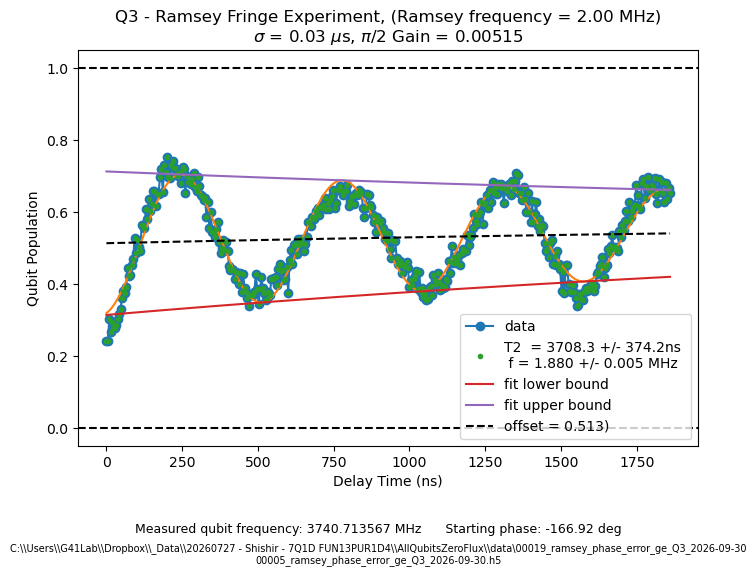


  Files:                  6 of 6
  Phase error per pulse:  -17.7194 deg
  Phase error per identity (X90, X90_neg): -35.4389 deg
  N = 0 phase (intercept): +374.532 deg
  RMS residual from line: 9.919 deg
  Fringe spread:          0.03463 MHz (should be flat - the identities do not change the detuning)


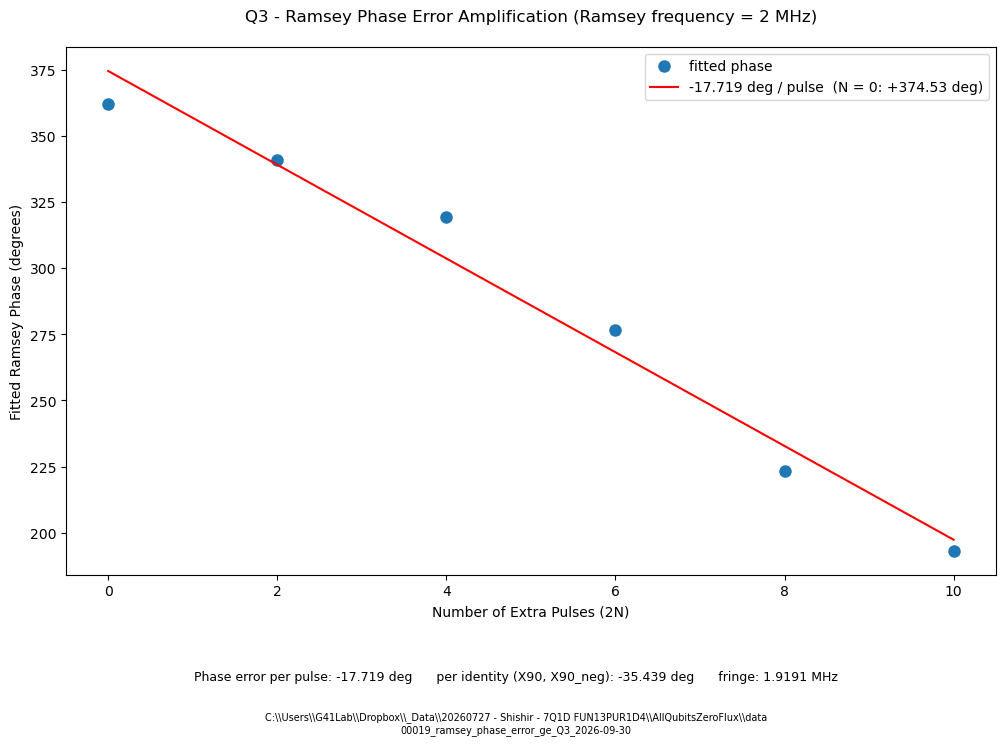

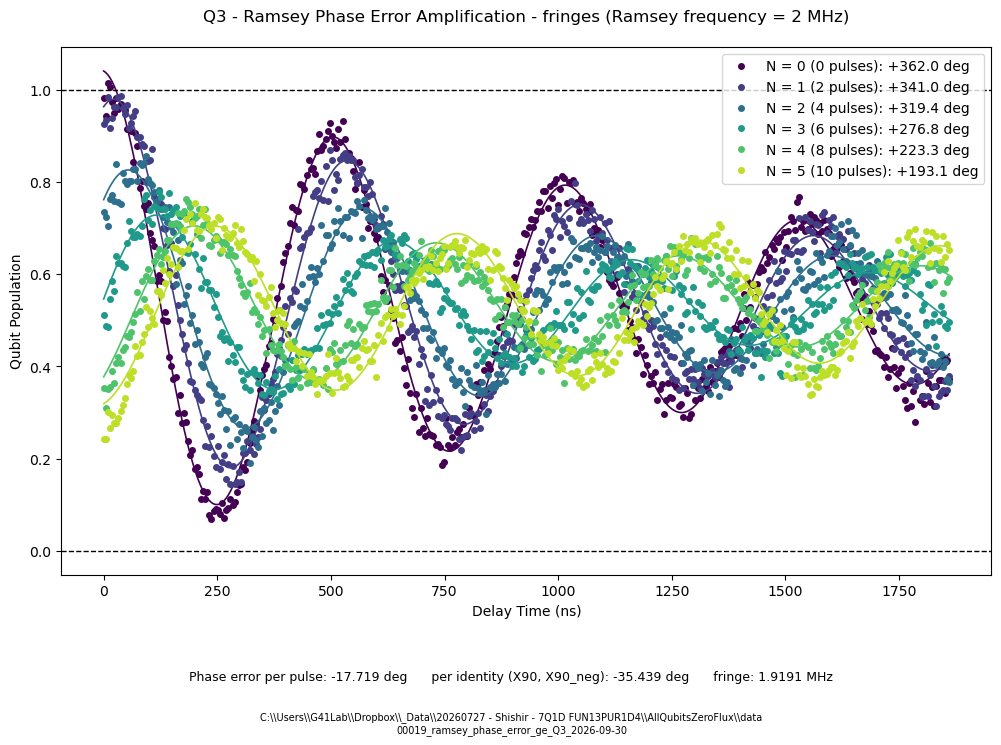

(<Figure size 1200x800 with 1 Axes>,
 <Figure size 1200x800 with 1 Axes>,
 array([ 0,  2,  4,  6,  8, 10]),
 array([361.99918967, 341.02369893, 319.41093748, 276.78591548,
        223.30959377, 193.08046637]),
 array([1.95566206, 1.94874077, 1.939112  , 1.91482531, 1.876482  ,
        1.87976482]))

In [180]:
#global_data_path = r"C:\\Users\\G41Lab\\Dropbox\\_Data\\20260727 - Shishir - 7Q1D FUN13PUR1D4\\Initial_Characterization_QICK\\data"
folder = "00019_ramsey_phase_error_ge_Q3_2026-09-30"
analyze_ramsey_phase_error(global_data_path, folder,  plot_each=True, SS=True, perform_fit=True, unwrap=False, plot_cal=True)#, custom_range=[3,5])  # custom_range=[N_min, N_max]

### Repeat Pulse Experiment

#### X90 

In [130]:
def analyze_repeat_X90_pulse(global_data_path, filenames,
                              SS=False, ef=False,
                              gain_cutoff_low=0.0, gain_cutoff_high=1.0,
                              extremum='auto', fit_window=3,
                              plot_cal=False, show_plot=True,
                              gain_offset=0.0, title_append="", vline = None,
                              perform_fit=True):
    """
    Repeated-X90 (error amplification) pulse calibration.

    The experiment repeats the X90 pulse before each readout while sweeping
    its gain, so a fractional amplitude error shows up multiplied by the
    number of pulses instead of on its own.

    Pass a list of filenames to overlay several N on one axes - each trace
    gets its own colour and is labelled by its 2N+1 pulse count, so the
    sharpening of the feature with N is visible directly.

    Parameters
    ----------
    global_data_path : str
        Root directory for all data files.
    filenames : list of str
        HDF5 filenames to overlay on one plot, e.g.
        ["00000_repeat_X90_pulse_ge_Q1_2026-08-30.h5", ...]. Always a list -
        wrap a single file in one.
    SS : bool
        True if single-shot normalisation data was collected. Scales the y
        axis to qubit population instead of raw amplitude.
    ef : bool
        True if this is an e-f experiment.
    gain_cutoff_low : float
        Lower bound of the gain range to include.
    gain_cutoff_high : float
        Upper bound of the gain range to include.
    extremum : {'auto', 'max', 'min'}
        Unused while the fit is commented out.
    fit_window : int
        Unused while the fit is commented out.
    plot_cal : bool
        If True (and SS=True), plot the g/e calibration IQ blobs and fidelity
        for each file.
    show_plot : bool
        If True, add a legend and display the figure.
    gain_offset : float
        Unused while the fit is commented out.
    title_append : str
        Extra text appended to the plot title.
    vline : float or None
        If given, draw a red dashed vertical line at this gain. Tune it by eye
        to read off where the traces cross.

    perform_fit : bool
        No effect while the fit is commented out; kept so every analysis
        function takes the same switch.
    Returns
    -------
    fig : matplotlib Figure
        Handle to the plotted figure, for further modification.
    """
    if isinstance(filenames, str):
        raise TypeError(
            "filenames must be a list, not a single string - wrap it in one: "
            f'["{filenames}"]')

    # Explicit axes, so the figures _plot_ge_calibration opens do not steal
    # the traces from underneath us.
    fig, ax = plt.subplots(figsize=(12,8))
    colors = plt.cm.tab10(np.arange(len(filenames)) % 10)
    stamp_lines = []

    for idx, fname in enumerate(filenames):
        data = _build_path(global_data_path, fname)
        print(f"Data path: {data}")

        with SlabFile(data, 'r') as f:
            gains = np.atleast_1d(array(f['gains'])[0])
            I = np.atleast_1d(array(f['avgi'])[0])
            Q = np.atleast_1d(array(f['avgq'])[0])
            amps = np.atleast_1d(array(f['amps'])[0])
            config = _load_config(f)

            if SS:
                Ig = array(f['I_g'])[0]
                Qg = array(f['Q_g'])[0]
                Ie = array(f['I_e'])[0]
                Qe = array(f['Q_e'])[0]
                If_data = array(f['I_f'])[0] if ef else None
                Qf_data = array(f['Q_f'])[0] if ef else None

        # A gain axis shorter than the measured sweep means the gain never
        # became a QickSweep1D, so every point was taken at the same gain.
        if gains.size != amps.size:
            raise ValueError(
                f"{fname}: 'gains' has {gains.size} point(s) but 'amps' has "
                f"{amps.size}. The gain did not sweep - check that "
                "build_task.py turns qubit_gain_ge into a QickSweep1D for "
                "this experiment.")

        N = config.get('N', None)
        n_pulses = 2 * N + 1 if N is not None else None

        if SS:
            if plot_cal:
                _plot_ge_calibration(Ig, Qg, Ie, Qe,
                                     title_prefix=_qubit_prefix(config) + f"Repeat X90 (N = {N}) ")
            ydata = _normalize_population(I, Q, Ig, Qg, Ie, Qe,
                                           ef=ef, If=If_data, Qf=Qf_data)
        else:
            ydata = amps

        # Restrict to the requested gain window
        cutoff = (gains >= gain_cutoff_low) & (gains <= gain_cutoff_high)
        x = gains[cutoff]
        y = ydata[cutoff]

        label = f"N = {n_pulses}" if n_pulses is not None else fname
        ax.plot(x, y, 'o-', color=colors[idx], markersize=5, label=label)

        stamp_lines.append(f"{data}  (N = {n_pulses})")

        step = np.mean(np.diff(x)) if len(x) > 1 else float('nan')
        print(f"  Pulses per point: {n_pulses}  (N = {N})")
        print(f"  Sweep window:     {x[0]:.6f} to {x[-1]:.6f} DAC units "
              f"({len(x)} pts, step {step:.6f})")

        # ----- fit commented out for now -----
        #
        # # Local quadratic fit around the turning point
        # if extremum == 'auto':
        #     if SS:
        #         use_max = True
        #     else:
        #         i_hi, i_lo = int(np.argmax(y)), int(np.argmin(y))
        #         dist_from_edge = lambda i: min(i, len(y) - 1 - i)
        #         use_max = dist_from_edge(i_hi) >= dist_from_edge(i_lo)
        # else:
        #     use_max = (extremum == 'max')
        # i_ext = int(np.argmax(y)) if use_max else int(np.argmin(y))
        #
        # lo = max(i_ext - fit_window, 0)
        # hi = min(i_ext + fit_window + 1, len(x))
        # coeffs = None
        # if hi - lo >= 3:
        #     coeffs = np.polyfit(x[lo:hi], y[lo:hi], 2)
        #     best_gain = (-coeffs[1] / (2 * coeffs[0])
        #                  if coeffs[0] != 0 else x[i_ext])
        #     # A vertex outside the fitted points means the parabola is
        #     # extrapolating, so fall back to the measured extremum.
        #     if not (x[lo] <= best_gain <= x[hi - 1]):
        #         print("  Warning: quadratic vertex fell outside the fit "
        #               "window; using the raw extremum instead.")
        #         best_gain, coeffs = x[i_ext], None
        # else:
        #     print("  Warning: fewer than 3 points available; "
        #           "using the raw extremum instead of a fit.")
        #     best_gain = x[i_ext]
        #
        # best_gain += gain_offset
        #
        # if i_ext in (0, len(x) - 1):
        #     print("  Warning: the turning point is at the edge of the "
        #           "sweep - re-centre start/stop and re-run.")
        #
        # if coeffs is not None:
        #     x_fine = np.linspace(x[lo], x[hi - 1], 200)
        #     ax.plot(x_fine, np.polyval(coeffs, x_fine), '-', linewidth=1.5,
        #             color=colors[idx])
        # ax.axvline(best_gain, color=colors[idx], linestyle='--')
        # print(f"  Calibrated gain:  {best_gain:.6f} DAC units")

    if SS:
        ax.set_ylabel("Qubit Population")
        ax.axhline(1, color='black', linestyle='--')
        ax.axhline(0, color='black', linestyle='--')
        ax.axhline(0.5, color='black', linestyle='--')
    else:
        ax.set_ylabel("a.u.")
    ax.set_xlabel("Pulse Gain (DAC units)")
    ax.set_title(_qubit_prefix(config) + "Repeated X90 Pulse Calibration\n" + title_append)

    if vline is not None:
        ax.axvline(vline, color='red', linestyle='--',
                   label=f'gain = {vline:.5f}')

    if show_plot:
        ax.legend()

    # One data path per line, each tagged with its pulse count
    _stamp_data_path(chr(10).join(stamp_lines), fig)

    if show_plot:
        plt.show()

    return fig


# =============================================================================
#  Parked: X90 calibration-point selection (target / 'half' crossing)
#
#  Not used by analyze_repeat_X90_pulse above, which just finds the turning
#  point of the signal. Kept here because it may matter later: with n_pulses
#  X90 pulses the sequence has rotated n_pulses * pi/2 at the correct gain, so
#  where it lands depends on the pulse count - a multiple of 4 returns to |g>
#  (a minimum), 2 mod 4 lands on |e> (a maximum), and an odd count stops on the
#  equator, where the population sits at 0.5 and there is no extremum to find.
#
#  To bring it back: add target='auto' and n_pulses=None to the signature and
#  drop these two blocks in where the comments say.
# =============================================================================
#
# --- goes where the extremum direction is chosen ---
#
# if target == 'auto' and n_pulses is not None:
#     target = {0: 'min', 2: 'max'}.get(n_pulses % 4, 'half')
#     print(f"  Target from n_pulses = {n_pulses}: {target}")
#     if target == 'half' and not SS:
#         print("  Note: an odd pulse count lands on the equator, which "
#               "cannot be located without a normalised population axis. "
#               "Re-run the analysis with SS=True; falling back to the "
#               "nearest extremum for now.")
#         target = 'auto'
#
# if target == 'auto':
#     # No usable pulse count - read the target off the data instead. Keep
#     # whichever extremum sits further from the sweep edges, since one on an
#     # edge is usually the sweep running out of range rather than a real
#     # turning point. 'half' is not identifiable this way.
#     target = ('max' if _dist_from_edge(int(np.argmax(y)))
#                        >= _dist_from_edge(int(np.argmin(y))) else 'min')
#     print(f"  Target (auto-detected from data): {target}")
#
# if target == 'half' and not SS:
#     raise ValueError(
#         "target='half' needs a normalised population axis to locate the "
#         "0.5 crossing - re-analyse with SS=True.")
#
# --- replaces the quadratic fit when target == 'half' ---
#
# # Calibration point is where the population crosses 0.5.
# sign_change = np.where(np.diff(np.sign(y - 0.5)) != 0)[0]
# if sign_change.size == 0:
#     raise ValueError(
#         "the population never crosses 0.5 inside the gain window - "
#         "re-centre start/stop on the X90 gain and re-run.")
# # Prefer the crossing nearest the middle of the sweep.
# i_c = int(sign_change[np.argmin(np.abs(sign_change - (len(y) - 1) / 2.0))])
# lo = max(i_c - fit_window + 1, 0)
# hi = min(i_c + fit_window + 1, len(x))
# if hi - lo >= 2:
#     coeffs = np.polyfit(x[lo:hi], y[lo:hi], 1)
# if coeffs is not None and coeffs[0] != 0:
#     best_gain = (0.5 - coeffs[1]) / coeffs[0]
#     if not (x[lo] <= best_gain <= x[hi - 1]):
#         print("  Warning: the linear fit put the crossing outside the "
#               "fit window; interpolating between neighbours instead.")
#         coeffs = None
# if coeffs is None:
#     # Straight interpolation between the two bracketing points.
#     x0, x1, y0, y1 = x[i_c], x[i_c + 1], y[i_c], y[i_c + 1]
#     best_gain = x0 + (0.5 - y0) * (x1 - x0) / (y1 - y0)
# i_mark = i_c
#
# --- and the readable guard for SS=True on a file with no single-shot data ---
#
# if SS:
#     needed = ['I_g', 'Q_g', 'I_e', 'Q_e'] + (['I_f', 'Q_f'] if ef else [])
#     missing = [k for k in needed if k not in list(f.keys())]
#     if missing:
#         raise KeyError(
#             f"{filename} has no {', '.join(missing)} - it was taken "
#             "with SS = 'False' in system_config.json. Re-run the "
#             "experiment with SS = 'True', or analyse with SS=False.")
# =============================================================================

Data path: C:\\Users\\G41Lab\\Dropbox\\_Data\\20260727 - Shishir - 7Q1D FUN13PUR1D4\\AllQubitsZeroFlux\\data\00005_repeat_X90_pulse_ge_Q3_2026-09-30.h5
  Pulses per point: 1  (N = 0)
  Sweep window:     0.003998 to 0.007477 DAC units (20 pts, step 0.000183)
Data path: C:\\Users\\G41Lab\\Dropbox\\_Data\\20260727 - Shishir - 7Q1D FUN13PUR1D4\\AllQubitsZeroFlux\\data\00006_repeat_X90_pulse_ge_Q3_2026-09-30.h5
  Pulses per point: 3  (N = 1)
  Sweep window:     0.003998 to 0.007477 DAC units (20 pts, step 0.000183)
Data path: C:\\Users\\G41Lab\\Dropbox\\_Data\\20260727 - Shishir - 7Q1D FUN13PUR1D4\\AllQubitsZeroFlux\\data\00007_repeat_X90_pulse_ge_Q3_2026-09-30.h5
  Pulses per point: 5  (N = 2)
  Sweep window:     0.003998 to 0.007477 DAC units (20 pts, step 0.000183)
Data path: C:\\Users\\G41Lab\\Dropbox\\_Data\\20260727 - Shishir - 7Q1D FUN13PUR1D4\\AllQubitsZeroFlux\\data\00008_repeat_X90_pulse_ge_Q3_2026-09-30.h5
  Pulses per point: 7  (N = 3)
  Sweep window:     0.003998 to 0.007477 DA

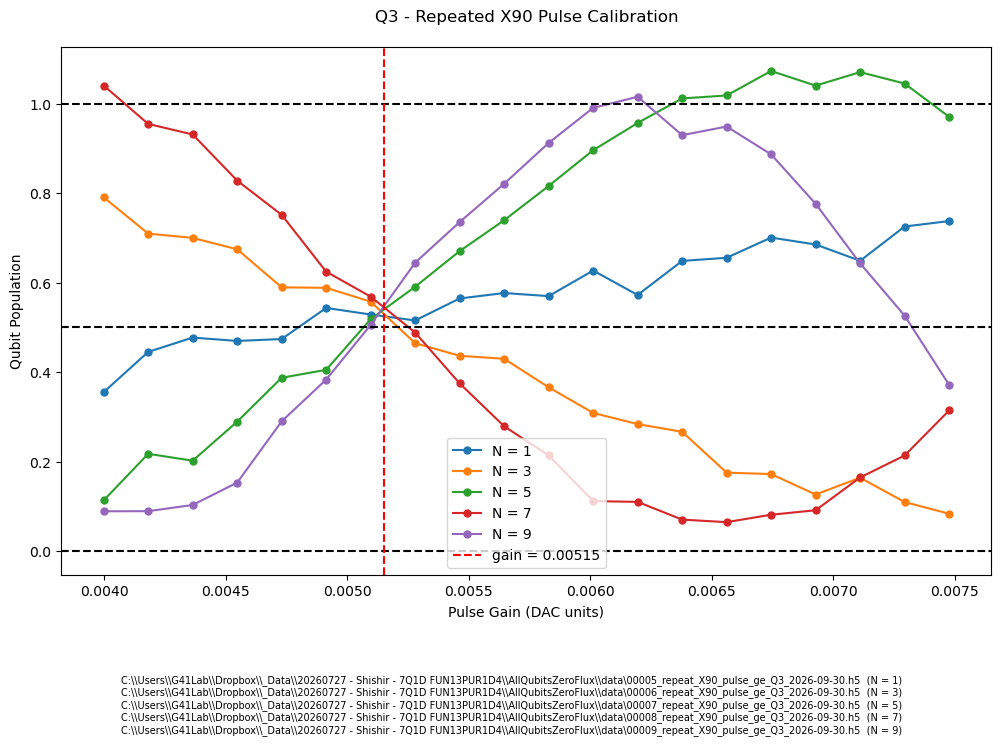

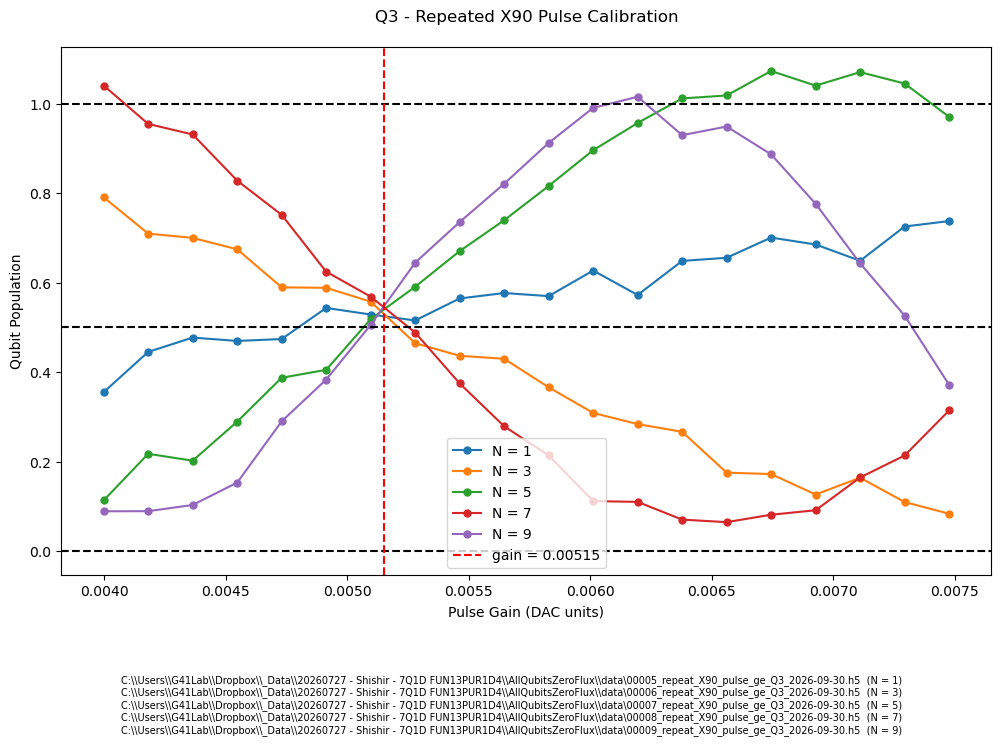

In [137]:
files = sequential_filenames("00005_repeat_X90_pulse_ge_Q3_2026-09-30.h5", 5)
analyze_repeat_X90_pulse(global_data_path, files, vline = 0.00515, SS = True)

#### X180

In [138]:
def analyze_repeat_X180_pulse(global_data_path, filenames,
                              SS=False, ef=False,
                              gain_cutoff_low=0.0, gain_cutoff_high=1.0,
                              extremum='auto', fit_window=3,
                              plot_cal=False, show_plot=True,
                              gain_offset=0.0, title_append="", vline = None,
                              perform_fit=True):
    """
    Repeated-X180 (error amplification) pulse calibration.

    The experiment repeats the X180 pulse before each readout while sweeping
    its gain, so a fractional amplitude error shows up multiplied by the
    number of pulses instead of on its own.

    Pass a list of filenames to overlay several N on one axes - each trace
    gets its own colour and is labelled by its 2N+1 pulse count, so the
    sharpening of the feature with N is visible directly.

    Parameters
    ----------
    global_data_path : str
        Root directory for all data files.
    filenames : list of str
        HDF5 filenames to overlay on one plot, e.g.
        ["00000_repeat_X180_pulse_ge_Q1_2026-09-02.h5", ...]. Always a list -
        wrap a single file in one.
    SS : bool
        True if single-shot normalisation data was collected. Scales the y
        axis to qubit population instead of raw amplitude.
    ef : bool
        True if this is an e-f experiment.
    gain_cutoff_low : float
        Lower bound of the gain range to include.
    gain_cutoff_high : float
        Upper bound of the gain range to include.
    extremum : {'auto', 'max', 'min'}
        Unused while the fit is commented out.
    fit_window : int
        Unused while the fit is commented out.
    plot_cal : bool
        If True (and SS=True), plot the g/e calibration IQ blobs and fidelity
        for each file.
    show_plot : bool
        If True, add a legend and display the figure.
    gain_offset : float
        Unused while the fit is commented out.
    title_append : str
        Extra text appended to the plot title.
    vline : float or None
        If given, draw a red dashed vertical line at this gain. Tune it by eye
        to read off where the traces cross.

    perform_fit : bool
        No effect while the fit is commented out; kept so every analysis
        function takes the same switch.
    Returns
    -------
    fig : matplotlib Figure
        Handle to the plotted figure, for further modification.
    """
    if isinstance(filenames, str):
        raise TypeError(
            "filenames must be a list, not a single string - wrap it in one: "
            f'["{filenames}"]')

    # Explicit axes, so the figures _plot_ge_calibration opens do not steal
    # the traces from underneath us.
    fig, ax = plt.subplots(figsize=(12,8))
    colors = plt.cm.tab10(np.arange(len(filenames)) % 10)
    stamp_lines = []

    for idx, fname in enumerate(filenames):
        data = _build_path(global_data_path, fname)
        print(f"Data path: {data}")

        with SlabFile(data, 'r') as f:
            gains = np.atleast_1d(array(f['gains'])[0])
            I = np.atleast_1d(array(f['avgi'])[0])
            Q = np.atleast_1d(array(f['avgq'])[0])
            amps = np.atleast_1d(array(f['amps'])[0])
            config = _load_config(f)

            if SS:
                Ig = array(f['I_g'])[0]
                Qg = array(f['Q_g'])[0]
                Ie = array(f['I_e'])[0]
                Qe = array(f['Q_e'])[0]
                If_data = array(f['I_f'])[0] if ef else None
                Qf_data = array(f['Q_f'])[0] if ef else None

        # A gain axis shorter than the measured sweep means the gain never
        # became a QickSweep1D, so every point was taken at the same gain.
        if gains.size != amps.size:
            raise ValueError(
                f"{fname}: 'gains' has {gains.size} point(s) but 'amps' has "
                f"{amps.size}. The gain did not sweep - check that "
                "build_task.py turns qubit_gain_ge into a QickSweep1D for "
                "this experiment.")

        N = config.get('N', None)
        n_pulses = N  if N is not None else None

        if SS:
            if plot_cal:
                _plot_ge_calibration(Ig, Qg, Ie, Qe,
                                     title_prefix=_qubit_prefix(config) + f"Repeat X180 (N = {N}) ")
            ydata = _normalize_population(I, Q, Ig, Qg, Ie, Qe,
                                           ef=ef, If=If_data, Qf=Qf_data)
        else:
            ydata = amps

        # Restrict to the requested gain window
        cutoff = (gains >= gain_cutoff_low) & (gains <= gain_cutoff_high)
        x = gains[cutoff]
        y = ydata[cutoff]

        label = f"N = {n_pulses}" if n_pulses is not None else fname
        ax.plot(x, y, 'o-', color=colors[idx], markersize=5, label=label)

        stamp_lines.append(f"{data}  (N = {n_pulses})")

        step = np.mean(np.diff(x)) if len(x) > 1 else float('nan')
        print(f"  Pulses per point: {n_pulses}  (N = {N})")
        print(f"  Sweep window:     {x[0]:.6f} to {x[-1]:.6f} DAC units "
              f"({len(x)} pts, step {step:.6f})")

        # ----- fit commented out for now -----
        #
        # # Local quadratic fit around the turning point
        # if extremum == 'auto':
        #     if SS:
        #         use_max = True
        #     else:
        #         i_hi, i_lo = int(np.argmax(y)), int(np.argmin(y))
        #         dist_from_edge = lambda i: min(i, len(y) - 1 - i)
        #         use_max = dist_from_edge(i_hi) >= dist_from_edge(i_lo)
        # else:
        #     use_max = (extremum == 'max')
        # i_ext = int(np.argmax(y)) if use_max else int(np.argmin(y))
        #
        # lo = max(i_ext - fit_window, 0)
        # hi = min(i_ext + fit_window + 1, len(x))
        # coeffs = None
        # if hi - lo >= 3:
        #     coeffs = np.polyfit(x[lo:hi], y[lo:hi], 2)
        #     best_gain = (-coeffs[1] / (2 * coeffs[0])
        #                  if coeffs[0] != 0 else x[i_ext])
        #     # A vertex outside the fitted points means the parabola is
        #     # extrapolating, so fall back to the measured extremum.
        #     if not (x[lo] <= best_gain <= x[hi - 1]):
        #         print("  Warning: quadratic vertex fell outside the fit "
        #               "window; using the raw extremum instead.")
        #         best_gain, coeffs = x[i_ext], None
        # else:
        #     print("  Warning: fewer than 3 points available; "
        #           "using the raw extremum instead of a fit.")
        #     best_gain = x[i_ext]
        #
        # best_gain += gain_offset
        #
        # if i_ext in (0, len(x) - 1):
        #     print("  Warning: the turning point is at the edge of the "
        #           "sweep - re-centre start/stop and re-run.")
        #
        # if coeffs is not None:
        #     x_fine = np.linspace(x[lo], x[hi - 1], 200)
        #     ax.plot(x_fine, np.polyval(coeffs, x_fine), '-', linewidth=1.5,
        #             color=colors[idx])
        # ax.axvline(best_gain, color=colors[idx], linestyle='--')
        # print(f"  Calibrated gain:  {best_gain:.6f} DAC units")

    if SS:
        ax.set_ylabel("Qubit Population")
        ax.axhline(1, color='black', linestyle='--')
        ax.axhline(0, color='black', linestyle='--')
        ax.axhline(0.5, color='black', linestyle='--')
    else:
        ax.set_ylabel("a.u.")
    ax.set_xlabel("Pulse Gain (DAC units)")
    ax.set_title(_qubit_prefix(config) + "Repeated X180 Pulse Calibration\n" + title_append)

    if vline is not None:
        ax.axvline(vline, color='red', linestyle='--',
                   label=f'gain = {vline:.5f}')

    if show_plot:
        ax.legend()

    # One data path per line, each tagged with its pulse count
    _stamp_data_path(chr(10).join(stamp_lines), fig)

    if show_plot:
        plt.show()

    return fig

Data path: C:\\Users\\G41Lab\\Dropbox\\_Data\\20260727 - Shishir - 7Q1D FUN13PUR1D4\\AllQubitsZeroFlux\\data\00006_repeat_X180_pulse_ge_Q3_2026-09-30.h5
  Pulses per point: 0  (N = 0)
  Sweep window:     0.009980 to 0.015290 DAC units (30 pts, step 0.000183)
Data path: C:\\Users\\G41Lab\\Dropbox\\_Data\\20260727 - Shishir - 7Q1D FUN13PUR1D4\\AllQubitsZeroFlux\\data\00007_repeat_X180_pulse_ge_Q3_2026-09-30.h5
  Pulses per point: 1  (N = 1)
  Sweep window:     0.009980 to 0.015290 DAC units (30 pts, step 0.000183)
Data path: C:\\Users\\G41Lab\\Dropbox\\_Data\\20260727 - Shishir - 7Q1D FUN13PUR1D4\\AllQubitsZeroFlux\\data\00008_repeat_X180_pulse_ge_Q3_2026-09-30.h5
  Pulses per point: 2  (N = 2)
  Sweep window:     0.009980 to 0.015290 DAC units (30 pts, step 0.000183)
Data path: C:\\Users\\G41Lab\\Dropbox\\_Data\\20260727 - Shishir - 7Q1D FUN13PUR1D4\\AllQubitsZeroFlux\\data\00009_repeat_X180_pulse_ge_Q3_2026-09-30.h5
  Pulses per point: 3  (N = 3)
  Sweep window:     0.009980 to 0.01529

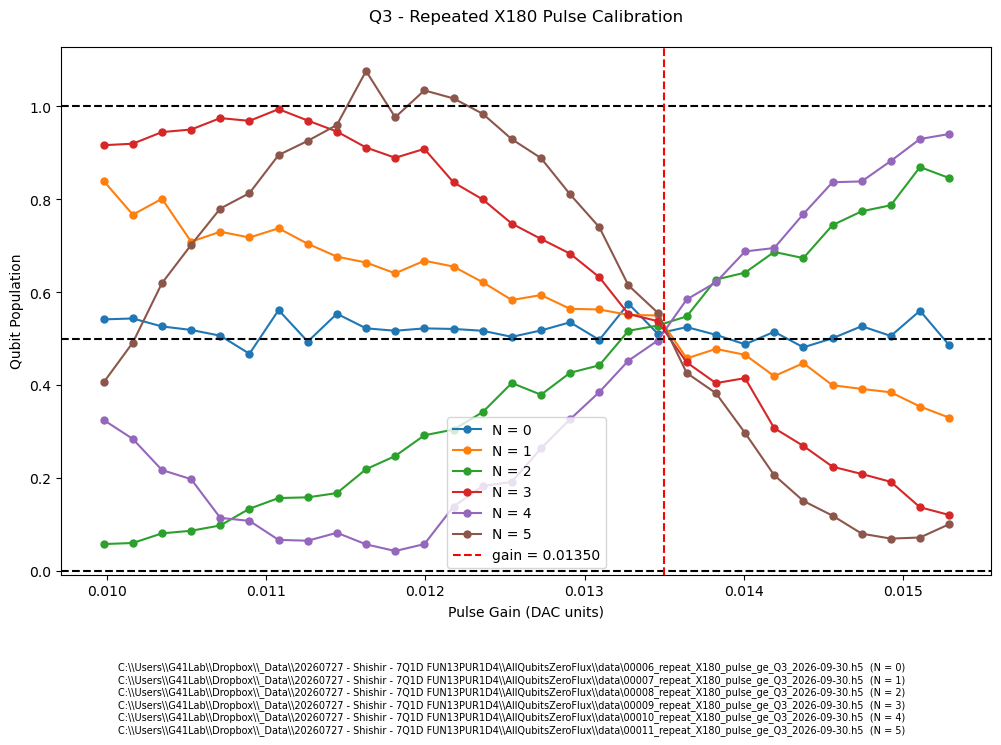

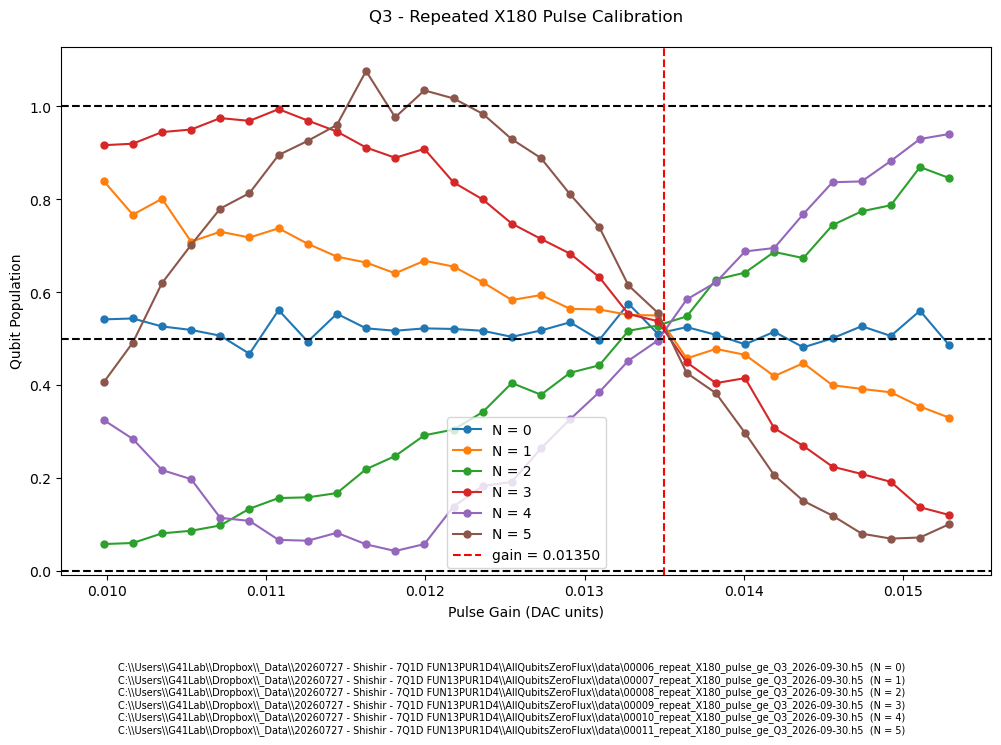

In [145]:
files =sequential_filenames("00006_repeat_X180_pulse_ge_Q3_2026-09-30.h5", 6)
analyze_repeat_X180_pulse(global_data_path, files, SS = True,  vline = 0.0135)

#### DRAG alpha (X90)

005c_drag_alpha_ge.py: X90_drag / X90_drag_neg identity pairs against alpha.

In [181]:
from scipy.optimize import curve_fit


@_accepts_folder
def analyze_drag_alpha(global_data_path, filename, SS=False, invert=False,
                       show_plot=True, perform_fit=True, ax=None):
    """
    DRAG alpha calibration of the X90 pulse (005c_drag_alpha_ge.py).

    N identity pairs (X90_drag, X90_drag_neg) are played from g for each alpha.
    With the wrong alpha every pair leaves a small rotation, so the excited
    population goes as B - A cos(2 pi N f (alpha - alpha0)): a dip at alpha0
    for every N, narrower for larger N. All N are fitted together with one
    alpha0 and one f (each N keeps its own depth A and offset B), and alpha0 is
    reported as the alpha_ge config value.

    Parameters
    ----------
    global_data_path : str
        Root directory for all data files.
    filename : str
        HDF5 filename, e.g. "00000_drag_alpha_ge_Q1_2026-09-30.h5", or a
        meas_list folder.
    SS : bool
        True if single-shot normalisation data was collected; the y axis is
        then the excited population and alpha0 is where it dips.
    invert : bool
        Without SS the raw amplitude may move either way with population. The
        fit assumes the optimum is a dip; set invert=True if it is a peak.
    show_plot : bool
        If True, add a legend and display the figure.
    perform_fit : bool
        If False, only the data is plotted.
    ax : matplotlib Axes, optional
        Draw into this axes (one panel of a collage) instead of a new figure.

    Returns
    -------
    fig : matplotlib Figure
    alpha0 : float or None
        Fitted optimum (None without a fit).
    """
    data = _build_path(global_data_path, filename)
    print(f"Data path: {data}")

    with SlabFile(data, 'r') as f:
        alphas = array(f['alphas'])[0]
        N_list = array(f['N_list'])[0].astype(int)
        I = array(f['avgi'])[0]          # one row per N
        Q = array(f['avgq'])[0]
        amps = array(f['amps'])[0]
        config = _load_config(f)
        if SS:
            Ig = array(f['I_g'])[0]
            Qg = array(f['Q_g'])[0]
            Ie = array(f['I_e'])[0]
            Qe = array(f['Q_e'])[0]

    if SS:
        Y = np.array([_normalize_population(I[k], Q[k], Ig, Qg, Ie, Qe) for k in range(len(N_list))])
    else:
        Y = amps
    sign = -1.0 if invert else 1.0      # fit a dip either way

    if ax is None:
        fig = plt.figure(figsize=(12, 8))
    else:
        plt.sca(ax)
        fig = ax.figure
    colors = plt.cm.viridis(np.linspace(0, 0.85, len(N_list)))
    for N, y, c in zip(N_list, Y, colors):
        plt.plot(alphas, y, 'o', color=c, markersize=5, label=f"N = {N} ({2 * N} pulses)")
    plt.xlabel(r"DRAG $\alpha$")
    plt.ylabel("Qubit Population" if SS else "a.u.")
    plt.title(_qubit_prefix(config) + "DRAG $\\alpha$ calibration, X90 identity pairs"
              f"\nanharmonicity = {config.get('anharmonicity_ge')} MHz, "
              f"$\\sigma$ = {config['sigma_ge']:.3f} $\\mu$s, $\\pi/2$ gain = {config['half_pi_gain_ge']}")
    if config.get('alpha_ge') is not None:
        plt.axvline(config['alpha_ge'], color='gray', linestyle=':',
                    label=f"config alpha_ge = {config['alpha_ge']:g}")

    alpha0 = None
    if perform_fit:
        x = alphas
        span = x.max() - x.min()
        Ys = sign * Y

        def model(x_all, a0, fr, *AB):
            k = len(N_list)
            out = []
            for i, N in enumerate(N_list):
                out.append(AB[k + i] - AB[i] * np.cos(2 * np.pi * N * fr * (x_all - a0)))
            return np.concatenate(out)

        # Coarse grid over (alpha0, f) first - for fixed alpha0 and f the model
        # is linear in each N's depth and offset, so those are solved directly
        # (depth >= 0) - then a full least-squares fit from the best grid point.
        a0_grid = np.linspace(x.min(), x.max(), 161)
        f_grid = np.geomspace(0.05 / span, len(x) / (4 * span * N_list.max()), 120)
        best = (np.inf, None, None)
        for fr in f_grid:
            cost = np.zeros(len(a0_grid))
            for N, y in zip(N_list, Ys):
                c = np.cos(2 * np.pi * N * fr * (x[None, :] - a0_grid[:, None]))
                cm, ym = c.mean(1, keepdims=True), y.mean()
                A = -((c - cm) * (y - ym)).sum(1) / np.maximum(((c - cm) ** 2).sum(1), 1e-30)
                A = np.clip(A, 0, None)
                B = ym + A * cm[:, 0]
                cost += ((y[None, :] - (B[:, None] - A[:, None] * c)) ** 2).sum(1)
            i = np.argmin(cost)
            if cost[i] < best[0]:
                best = (cost[i], a0_grid[i], fr)
        _, a0_guess, f_guess = best

        p0 = [a0_guess, f_guess] + [np.ptp(y) / 2 for y in Ys] + [y.mean() + np.ptp(y) / 2 for y in Ys]
        lo = [x.min() - span, 0] + [0] * len(N_list) + [-np.inf] * len(N_list)
        hi = [x.max() + span, np.inf] + [np.inf] * (2 * len(N_list))
        popt, pcov = curve_fit(model, x, Ys.ravel(), p0=p0, bounds=(lo, hi), maxfev=20000)
        alpha0, fr = popt[0], popt[1]
        alpha0_err = float(np.sqrt(pcov[0, 0])) if np.isfinite(pcov[0, 0]) else float('nan')

        x_fine = np.linspace(x.min(), x.max(), 400)
        fit_curves = sign * model(x_fine, *popt).reshape(len(N_list), -1)
        for y_fit, c in zip(fit_curves, colors):
            plt.plot(x_fine, y_fit, '-', color=c, linewidth=1.5)
        plt.axvline(alpha0, color='red', linestyle='--',
                    label=f"$\\alpha_0$ = {alpha0:.3f} $\\pm$ {alpha0_err:.3f}")

        print(f"  alpha0 = {alpha0:.4f} +/- {alpha0_err:.4f}   (N = 1 period in alpha: {1 / fr:.3g})")
        for N, y_fit in zip(N_list, fit_curves):
            print(f"    N = {N}: fitted rise across the sweep {np.ptp(y_fit):.4f}")
        if not x.min() <= alpha0 <= x.max():
            print("  alpha0 is outside the swept range - widen start/stop in drag_alpha_ge")
        _report_config_values(config, {'alpha_ge': round(float(alpha0), 4)})

    if show_plot:
        plt.legend()
    if ax is None:
        _stamp_data_path(data)
        if show_plot:
            plt.show()

    return fig, alpha0

Data path: C:\\Users\\G41Lab\\Dropbox\\_Data\\20260727 - Shishir - 7Q1D FUN13PUR1D4\\AllQubitsZeroFlux\\data\00000_drag_alpha_ge_Q3_2026-09-30.h5
  alpha0 = -1.7891 +/- 0.4863   (N = 1 period in alpha: 38)
    N = 1: fitted rise across the sweep 0.0160
    N = 3: fitted rise across the sweep 0.0979
    N = 5: fitted rise across the sweep 0.1043
  --- config values (Q3) ---
  "alpha_ge": -1.7891,


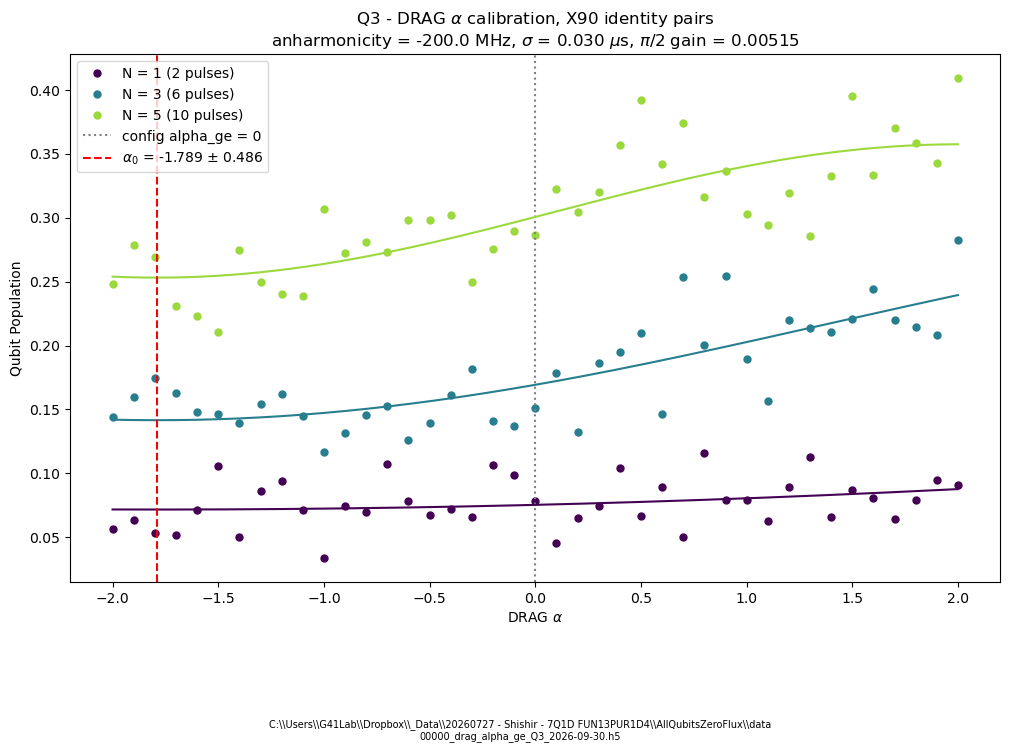

In [182]:
filename = r"00000_drag_alpha_ge_Q3_2026-09-30.h5"
fig, alpha0 = analyze_drag_alpha(global_data_path, filename, SS=True)

# every qubit of a meas_list folder, one figure each or all in one
# analyze_drag_alpha(global_data_path, "000NN_drag_alpha_ge_all_2026-09-30", SS=True, collage=True)

### T2 Spin Echo

In [ ]:
@_accepts_folder
def analyze_t2_spin_echo(global_data_path, filename,
                          SS=False, plot_cal=False, show_plot=True,
                          perform_fit=True, ax=None):
    """
    T2 spin-echo experiment.

    Parameters
    ----------
    global_data_path : str
        Root directory for all data files.
    filename : str
        HDF5 filename, e.g. "00001_SpinEcho_ge_Q3_2024-11-03.h5".
    SS : bool
        True if single-shot normalisation data was collected.
    plot_cal : bool
        If True (and SS=True), plot the g/e calibration IQ blobs and fidelity.
    show_plot : bool
        If True, add a legend and display the figure.

    perform_fit : bool
        If True (default), fit the data and draw the fit. If False, only the
        data is plotted - same scaling, labels and stamp, no fit.
    ax : matplotlib Axes, optional
        Draw into this axes (one panel of a collage) instead of a new figure;
        the data-path stamp is then left to the caller.

    Returns
    -------
    fig : matplotlib Figure
        Handle to the plotted figure, for further modification.
    """
    data = _build_path(global_data_path, filename)
    print(f"Data path: {data}")

    with SlabFile(data, 'r') as f:
        delay_times1 = array(f['delay_times1'])[0]
        delay_times2 = array(f['delay_times2'])[0]
        I = array(f['avgi'])[0]
        Q = array(f['avgq'])[0]
        amps = array(f['amps'])[0]
        config = _load_config(f)

        if SS:
            Ig = array(f['I_g'])[0]
            Qg = array(f['Q_g'])[0]
            Ie = array(f['I_e'])[0]
            Qe = array(f['Q_e'])[0]

    if SS:
        if plot_cal:
            _plot_ge_calibration(Ig, Qg, Ie, Qe, title_prefix=_qubit_prefix(config) + "Spin Echo ")
        ydata = _normalize_population(I, Q, Ig, Qg, Ie, Qe)
    else:
        ydata = amps

    delay_times = delay_times1 + delay_times2

    if ax is None:
        fig = plt.figure(figsize=(12,8))
    else:
        plt.sca(ax)
        fig = ax.figure
    plt.plot(delay_times, ydata, marker='o', label='data')
    if SS:
        plt.ylabel("Qubit Population")
    else:
        plt.ylabel("a.u.")
    plt.xlabel(r"Delay Time ($\mu$s)")
    plt.title(_qubit_prefix(config) + "Spin Echo Experiment")
    if show_plot:
        plt.legend()

    if perform_fit:
        fit = Fit()
        fit_results = fit.ramsey(delay_times, ydata, plot=show_plot)
        print("  Spin echo fit results:")
        pp.pprint(fit_results)
    if ax is None:
        _stamp_data_path(data)
        if show_plot:
            plt.show()

    return fig

In [ ]:
#filename = r"00001_SpinEcho_ge_Q3_2024-11-03.h5"
#analyze_t2_spin_echo(global_data_path, filename, SS=True) # not tested this yet

# every qubit of a meas_list folder in one figure
# analyze_t2_spin_echo(global_data_path, r"<meas_list folder>", collage=True)

### T1

In [106]:
@_accepts_folder
def analyze_t1(global_data_path, filename,
               SS=False, plot_cal=False, show_plot=True,
               perform_fit=True, ax=None):
    """
    T1 relaxation experiment.

    Parameters
    ----------
    global_data_path : str
        Root directory for all data files.
    filename : str
        HDF5 filename, e.g. "00001_T1_ge_Q1_2026-06-06.h5".
    SS : bool
        True if single-shot normalisation data was collected.
    plot_cal : bool
        If True (and SS=True), plot the g/e calibration IQ blobs and fidelity.
    show_plot : bool
        If True, add a legend and display the figure.

    perform_fit : bool
        If True (default), fit the data and draw the fit. If False, only the
        data is plotted - same scaling, labels and stamp, no fit.
    ax : matplotlib Axes, optional
        Draw into this axes (one panel of a collage) instead of a new figure;
        the data-path stamp is then left to the caller.

    Returns
    -------
    fig : matplotlib Figure
        Handle to the plotted figure, for further modification.
    """
    data = _build_path(global_data_path, filename)
    print(f"Data path: {data}")

    with SlabFile(data, 'r') as f:
        delay_times = array(f['delay_times'])[0]
        I = array(f['avgi'])[0]
        Q = array(f['avgq'])[0]
        amps = array(f['amps'])[0]
        config = _load_config(f)

        if SS:
            Ig = array(f['I_g'])[0]
            Qg = array(f['Q_g'])[0]
            Ie = array(f['I_e'])[0]
            Qe = array(f['Q_e'])[0]

    if SS:
        if plot_cal:
            _plot_ge_calibration(Ig, Qg, Ie, Qe, title_prefix=_qubit_prefix(config) + "T1 ")
        ydata = _normalize_population(I, Q, Ig, Qg, Ie, Qe)
    else:
        ydata = amps

    x_ns = delay_times * 1000  # us -> ns

    if ax is None:
        fig = plt.figure(figsize=(12,8))
    else:
        plt.sca(ax)
        fig = ax.figure
    plt.plot(x_ns, ydata, marker='o', label='data')
    if SS:
        plt.ylabel("Qubit Population")
        plt.axhline(1, color='black', linestyle='--')
        plt.axhline(0, color='black', linestyle='--')
    else:
        plt.ylabel("a.u.")
    plt.xlabel("Delay Time (ns)")
    plt.title(_qubit_prefix(config) + f"T1 Experiment: Gain = {config['qubit_gain_ge']}, "
              f"Sigma (us) = {config['sigma_ge']}")
    if show_plot:
        plt.legend()

    if perform_fit:
        fit = Fit()
        fit_results = fit.T1(x_ns, ydata, plot=show_plot)
        print("  T1 fit results:")
        pp.pprint(fit_results)
    if ax is None:
        _stamp_data_path(data)
        if show_plot:
            plt.show()

    return fig

Data folder: C:\\Users\\G41Lab\\Dropbox\\_Data\\20260727 - Shishir - 7Q1D FUN13PUR1D4\\AllQubitsZeroFlux\\data\00018_T1_ge_all_2026-09-29  (7 files)

Data path: C:\\Users\\G41Lab\\Dropbox\\_Data\\20260727 - Shishir - 7Q1D FUN13PUR1D4\\AllQubitsZeroFlux\\data\00018_T1_ge_all_2026-09-29\00000_T1_ge_Q1_2026-09-29.h5
  T1 fit results:
{'T1': [38559.38189604638, 734.7064637580465],
 'amp': [11.075292741431003, 0.06964944475610066],
 'final_offset': [2.2617065390082334, 0.06356648465559464],
 'fit_func': <function Fit.T1.<locals>.<lambda> at 0x000001D1BE605E40>}

Data path: C:\\Users\\G41Lab\\Dropbox\\_Data\\20260727 - Shishir - 7Q1D FUN13PUR1D4\\AllQubitsZeroFlux\\data\00018_T1_ge_all_2026-09-29\00000_T1_ge_Q2_2026-09-29.h5
  T1 fit results:
{'T1': [27026.37542178038, 503.27545481110667],
 'amp': [5.484108581638002, 0.04333892530587399],
 'final_offset': [0.9000499106327167, 0.02294005196595268],
 'fit_func': <function Fit.T1.<locals>.<lambda> at 0x000001D1BE5D7880>}

Data path: C:\\Users\\

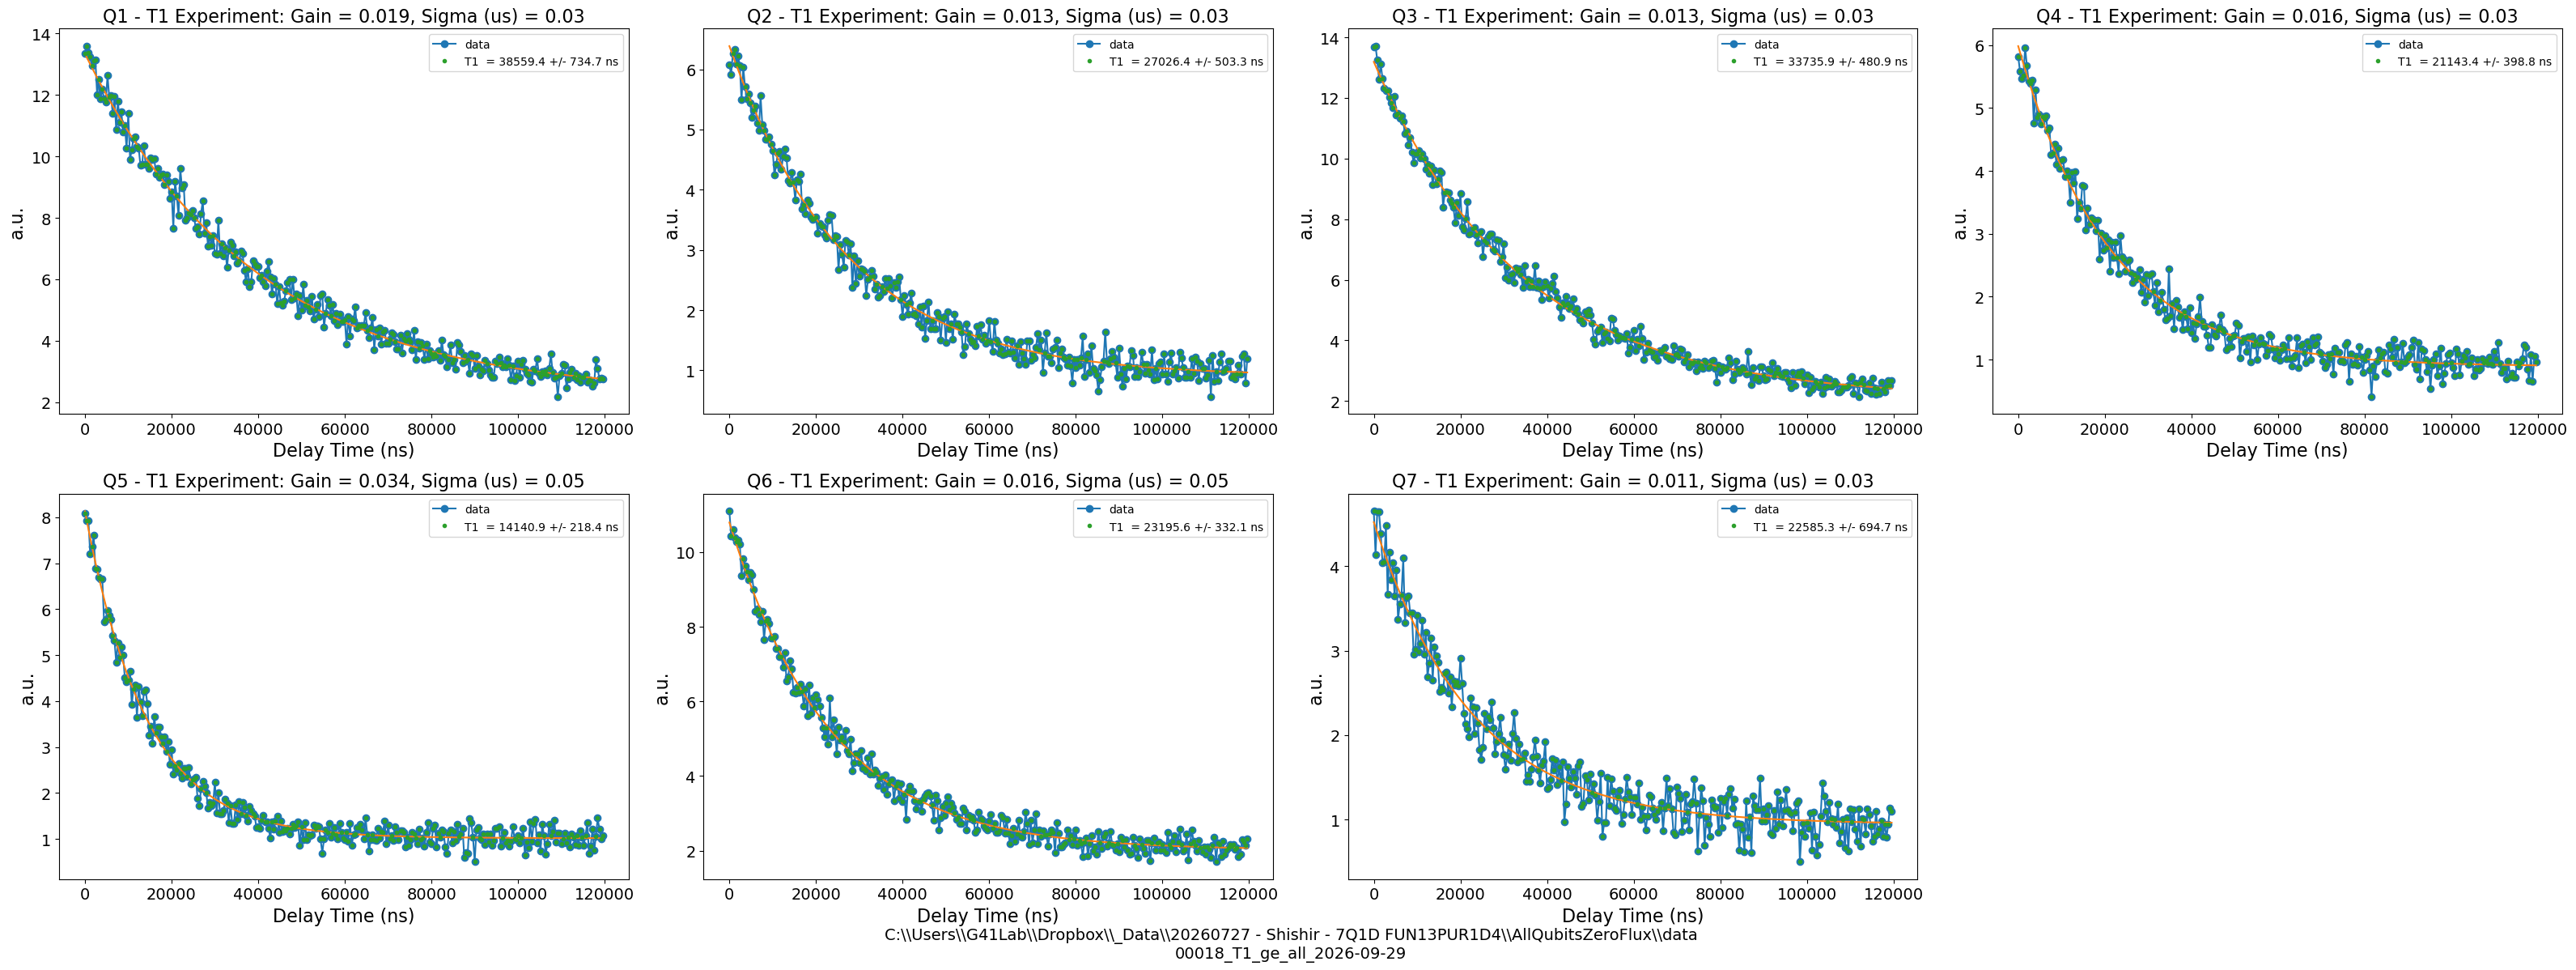

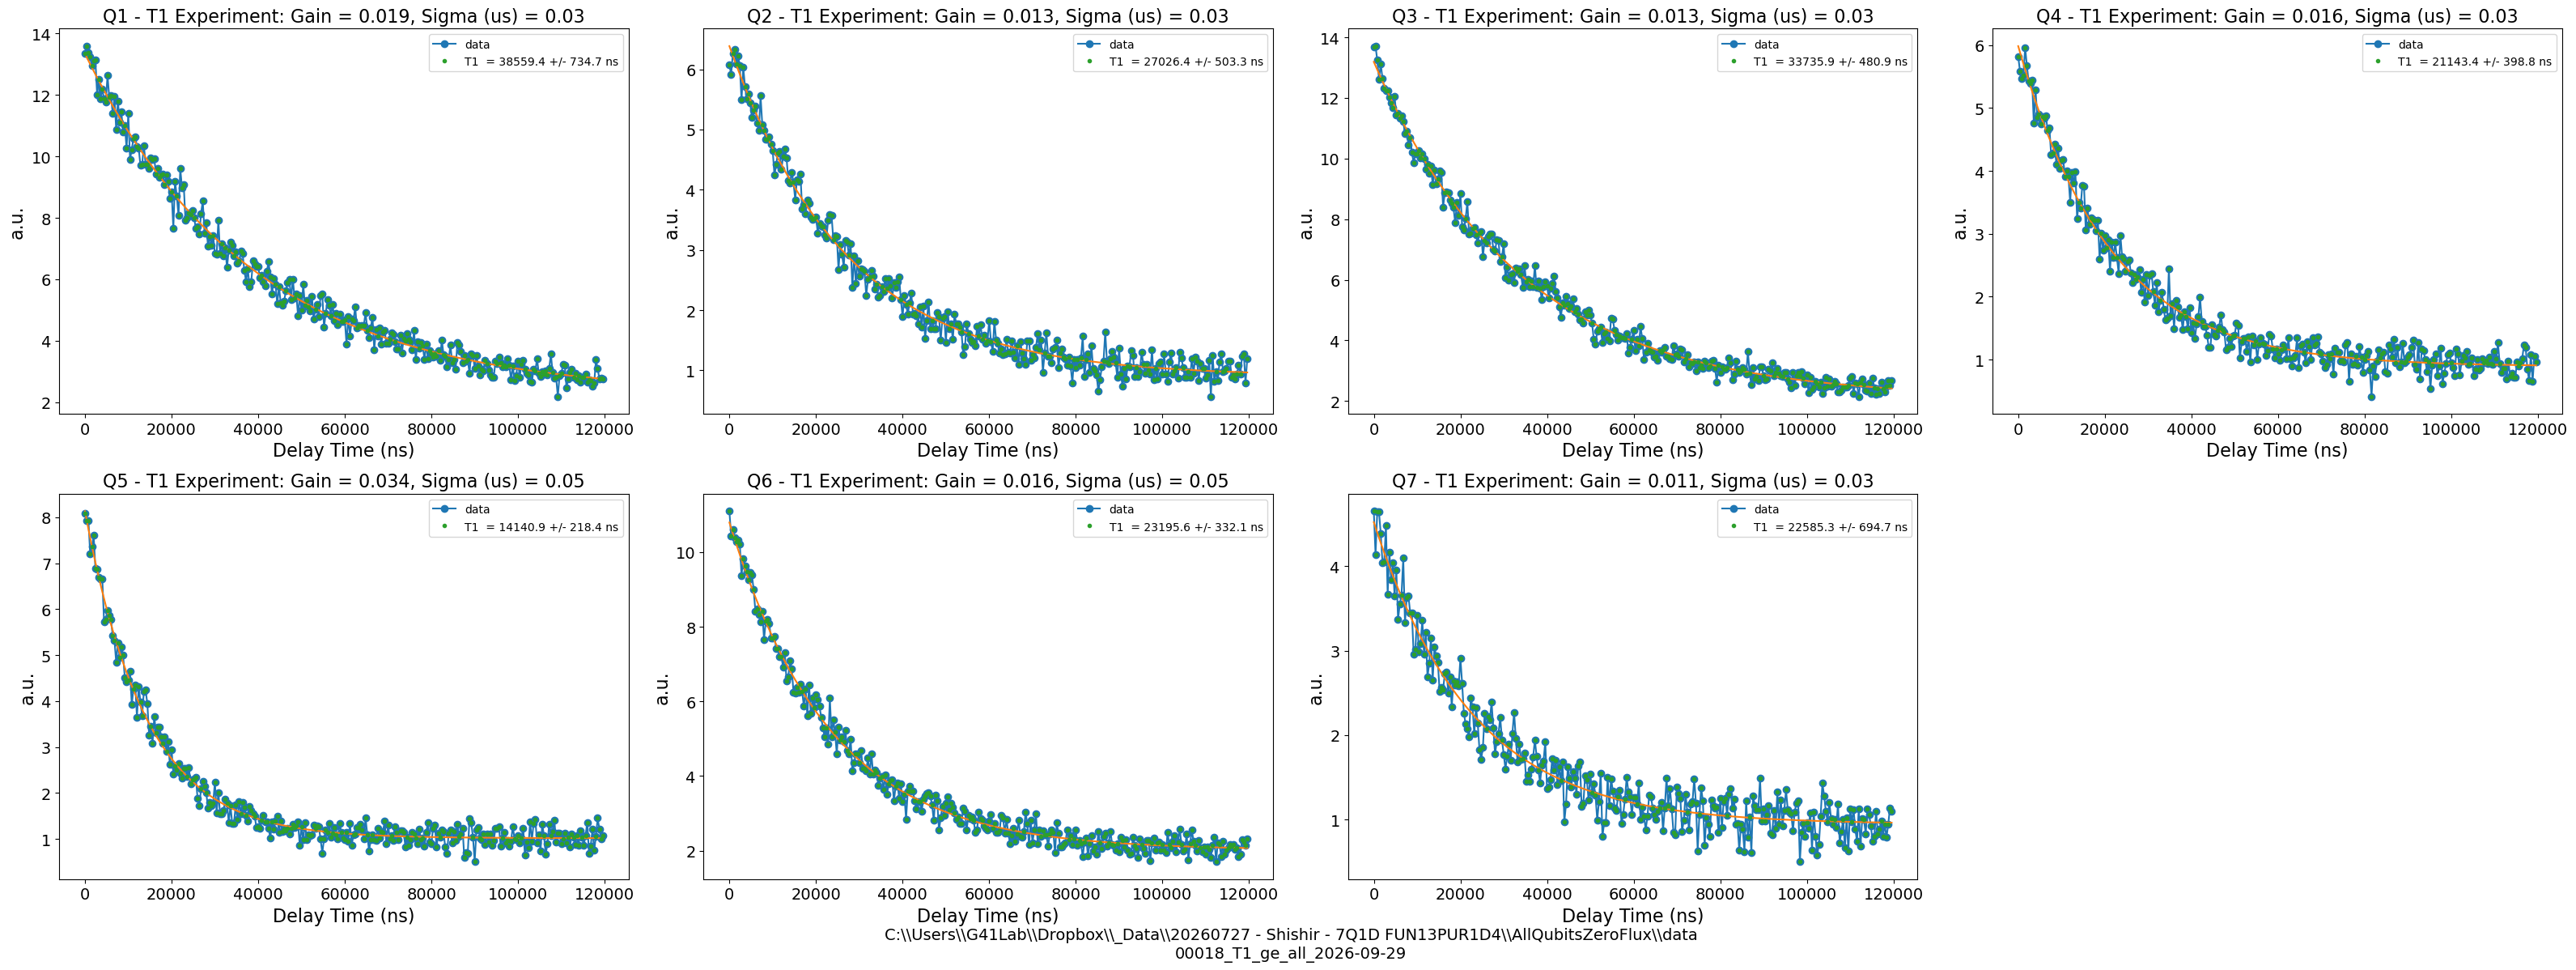

In [109]:
# idx= "52"
# filename = f"2026-08-17_overnight _T1_ge/000" + idx + "_T1_ge_Q1_2026-08-18.h5"
filename = r"00018_T1_ge_all_2026-09-29"
analyze_t1(global_data_path, filename, collage=True)

# every qubit of a meas_list folder in one figure
# analyze_t1(global_data_path, r"<meas_list folder>", collage=True)

### T1 tracking over time

In [110]:
def analyze_T1_temporal_scan(global_data_path, folder_name,
                              error_bars=True,
                              time_spacing_min=5.0, show_plot=True,
                              perform_fit=True):
    """
    T1 temporal scan (e.g. a folder of overnight T1 runs).

    Loads every T1 data file in a folder, fits T1 for each one, and plots
    the fitted T1 values against elapsed time. Measurements are assumed to
    be evenly spaced ``time_spacing_min`` minutes apart (matching e.g. the
    night_wait interval used by 008a_overnight_T1_ge.py), in the order the
    files sort alphabetically (i.e. by their sequential file number).

    Parameters
    ----------
    global_data_path : str
        Root directory for all data files.
    folder_name : str
        Name of the subfolder (under global_data_path) containing the T1
        data files, e.g. "2026-08-17overnight _T1_ge".
    error_bars : bool
        If True (default), draw whisker-style error bars (in black) on
        each point using the standard error the T1 fit itself reports.
    time_spacing_min : float
        Assumed time in minutes between consecutive measurements.
    show_plot : bool
        If True, add a legend and display the figure.

    perform_fit : bool
        Accepted for consistency with the other analysis functions, but
        must stay True here: the plotted quantity is itself a fit result.
    Returns
    -------
    fig : matplotlib Figure
        Handle to the plotted figure, for further modification.
    T1_values : 1D np.array
        Fitted T1 (us) for each file, in the order plotted.
    T1_errors : 1D np.array
        Fit standard error on T1 (us) for each file, in the order plotted.
    """
    if not perform_fit:
        raise ValueError(
            "perform_fit=False has nothing to plot here - the y axis of this "
            "scan is the fitted T1 of each file, not raw data. Use analyze_t1 "
            "with perform_fit=False to look at an individual trace.")

    folder_path = os.path.join(global_data_path, folder_name)
    print(f"Data folder: {folder_path}")

    files = sorted(f for f in os.listdir(folder_path) if f.endswith('.h5'))
    if not files:
        raise ValueError(f"No .h5 files found in {folder_path}")

    T1_values = []
    T1_errors = []
    config = {}
    for fname in files:
        with SlabFile(os.path.join(folder_path, fname), 'r') as f:
            delay_times = array(f['delay_times'])[0]
            amps = array(f['amps'])[0]
            if not config:
                config = _load_config(f)

        x_ns = delay_times * 1000  # us -> ns

        fit = Fit()
        fit_results = fit.T1(x_ns, amps, plot=False)
        T1_values.append(fit_results['T1'][0])
        T1_errors.append(fit_results['T1'][1])

    T1_values = np.array(T1_values)
    T1_errors = np.array(T1_errors)
    time_axis = np.arange(len(files)) * time_spacing_min

    # earliest file's timestamp, for the start-time stamp
    mtimes = [os.path.getmtime(os.path.join(folder_path, fname)) for fname in files]
    start_time = datetime.datetime.fromtimestamp(min(mtimes))

    fig = plt.figure(figsize=(12,8))
    if error_bars:
        plt.errorbar(time_axis, T1_values/1e3, yerr=T1_errors/1e3,
                     marker='o', linestyle='-', label='T1',
                     ecolor='black', elinewidth=1, capsize=4, capthick=1)
    else:
        plt.plot(time_axis, T1_values/1e3, marker='o', linestyle='-', label='T1')
    plt.xlabel("Elapsed Time (min)")
    plt.ylabel(r"T1 ($\mu s$)")
    plt.title(_qubit_prefix(config) + f"T1 Temporal Scan ({len(files)} measurements, "
              f"{time_spacing_min:.1f} min spacing)")
    if show_plot:
        plt.legend()
    _stamp_data_path(
        f"{folder_path}\nStart time: {start_time.strftime('%Y-%m-%d %H:%M:%S')}",
        fig)
    if show_plot:
        plt.show()

    return fig, T1_values, T1_errors

In [ ]:
data_folder = "2026-08-17_overnight _T1_ge"
analyze_T1_temporal_scan(global_data_path, data_folder, time_spacing_min=2.5)

### Overnight Ramsey + T1 (008b)

All qubits on one plot each for frequency, T1 and T2 against time.

In [111]:
import contextlib
import io


def analyze_overnight_T1_ramsey(global_data_path, folder_name, SS=True, show_plot=True):
    """
    Overnight Ramsey + T1 run from 008b_overnight_T1_Ramsey_ge.py.

    Fits every file in the folder and plots, for all qubits on one plot each:
    qubit frequency (offset from that qubit's overnight mean), T1 and T2 Ramsey
    against the time the measurement started. Error bars are the fit standard
    errors of each point; the legend gives the overnight mean +/- standard
    deviation. Prints the same numbers as a table.

    The qubit frequency is corrected for the tProc delay rounding: the Ramsey
    delay step runs shorter than the nominal (stop - start)/(steps - 1) the
    phase advance is computed from, so the applied detuning is ramsey_freq
    times nominal/actual step (1.081 for 1.5 us / 200 steps), not ramsey_freq.

    Returns
    -------
    figs : list of the three matplotlib Figures (frequency, T1, T2)
    results : dict, one entry per qubit:
        {'t_freq', 'freq', 'freq_err', 't_T1', 'T1', 'T1_err', 't_T2', 'T2', 'T2_err'}
        times in hours since the first measurement, frequencies in MHz,
        T1 / T2 in us; plus 'freq_mean', 'freq_std', 'T1_mean', ... per quantity.
    """
    folder_path = os.path.join(global_data_path, folder_name)
    print(f"Data folder: {folder_path}")
    files = sorted(f for f in os.listdir(folder_path) if f.endswith('.h5'))

    results = {}
    t_start = None
    for fname in files:
        with SlabFile(os.path.join(folder_path, fname), 'r') as f:
            delay_times = array(f['delay_times'])[0]
            delay_times -= delay_times[0]
            config = _load_config(f)
            stamp = datetime.datetime.fromisoformat(f.attrs['timestamp'])
            if SS:
                ydata = _normalize_population(array(f['avgi'])[0], array(f['avgq'])[0],
                                              array(f['I_g'])[0], array(f['Q_g'])[0],
                                              array(f['I_e'])[0], array(f['Q_e'])[0])
            else:
                ydata = array(f['amps'])[0]
        t_start = stamp if t_start is None else min(t_start, stamp)
        qb = config['qubit_index']
        r = results.setdefault(qb, {k: [] for k in ('t_freq', 'freq', 'freq_err', 't_T1', 'T1', 'T1_err',
                                                    't_T2', 'T2', 'T2_err')})
        x_ns = delay_times * 1000

        with contextlib.redirect_stdout(io.StringIO()):   # the fits print a lot
            if '_T1_ge_' in fname:
                fit = Fit().T1(x_ns, ydata, plot=False)
                r['t_T1'].append(stamp)
                r['T1'].append(fit['T1'][0] / 1e3)
                r['T1_err'].append(fit['T1'][1] / 1e3)
            elif '_Ramsey_ge_' in fname:
                fit = Fit().ramsey(x_ns, ydata, plot=False)
                nominal_step = (config['stop'] - config['start']) / (config['steps'] - 1)
                detuning = config['ramsey_freq'] * nominal_step / (delay_times[1] - delay_times[0])
                r['t_freq'].append(stamp)
                r['freq'].append(config['qubit_freq_ge'] + detuning - fit['f'][0] * 1e3)
                r['freq_err'].append(fit['f'][1] * 1e3)
                r['t_T2'].append(stamp)
                r['T2'].append(fit['T2'][0] / 1e3)
                r['T2_err'].append(fit['T2'][1] / 1e3)

    # hours since the first measurement, arrays, overnight mean and std
    for qb, r in results.items():
        for k in list(r):
            if k.startswith('t_'):
                r[k] = np.array([(t - t_start).total_seconds() / 3600 for t in r[k]])
            else:
                r[k] = np.array(r[k])
        for k in ('freq', 'T1', 'T2'):
            r[k + '_mean'] = np.mean(r[k])
            r[k + '_std'] = np.std(r[k], ddof=1)

    qubits = sorted(results)
    colors = plt.cm.tab10(np.arange(len(qubits)))
    figs = []
    for key, ylabel, title in (
            ('freq', r"$f_{qubit}$ - overnight mean (kHz)", "Qubit frequency (Ramsey)"),
            ('T1', r"T1 ($\mu$s)", "T1"),
            ('T2', r"T2 Ramsey ($\mu$s)", "T2 Ramsey")):
        fig = plt.figure(figsize=(12, 7))
        for qb, c in zip(qubits, colors):
            r = results[qb]
            if key == 'freq':
                y, yerr = (r['freq'] - r['freq_mean']) * 1e3, r['freq_err'] * 1e3
                label = f"Q{qb}: {r['freq_mean']:.3f} MHz $\\pm$ {r['freq_std'] * 1e3:.0f} kHz"
            else:
                y, yerr = r[key], r[key + '_err']
                label = f"Q{qb}: {r[key + '_mean']:.1f} $\\pm$ {r[key + '_std']:.1f} $\\mu$s"
            plt.errorbar(r['t_' + key], y, yerr=yerr, color=c, marker='o', ms=4,
                         capsize=3, elinewidth=1, label=label)
        plt.xlabel(f"Time since {t_start:%Y-%m-%d %H:%M} (hours)")
        plt.ylabel(ylabel)
        plt.title(f"{title} over time, {len(results[qubits[0]]['t_' + key])} measurements per qubit"
                  "\nerror bars: fit standard error; legend: overnight mean $\\pm$ std")
        plt.legend(loc='center left', bbox_to_anchor=(1.01, 0.5))
        _stamp_data_path(folder_path, fig)
        fig.tight_layout(rect=(0, 0.04, 1, 1))
        figs.append(fig)
        if show_plot:
            plt.show()

    print(f"\n{'':4s}{'f_qubit (MHz)':>26s}{'T1 (us)':>18s}{'T2 Ramsey (us)':>18s}")
    for qb in qubits:
        r = results[qb]
        print(f"Q{qb}  {r['freq_mean']:12.4f} +/- {r['freq_std'] * 1e3:4.0f} kHz"
              f"{r['T1_mean']:9.1f} +/- {r['T1_std']:4.1f}{r['T2_mean']:9.2f} +/- {r['T2_std']:4.2f}")
    return figs, results

Data folder: C:\\Users\\G41Lab\\Dropbox\\_Data\\20260727 - Shishir - 7Q1D FUN13PUR1D4\\AllQubitsZeroFlux\\data\overnight\overnight\2026-09-30_0235_T1_Ramsey


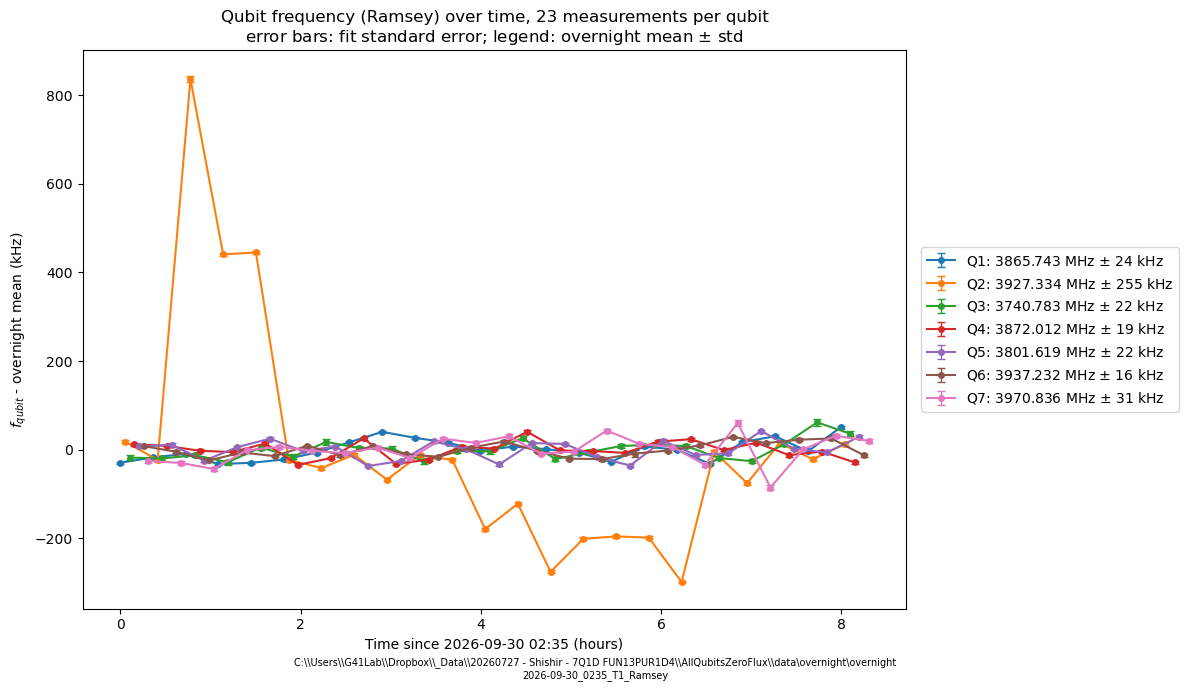

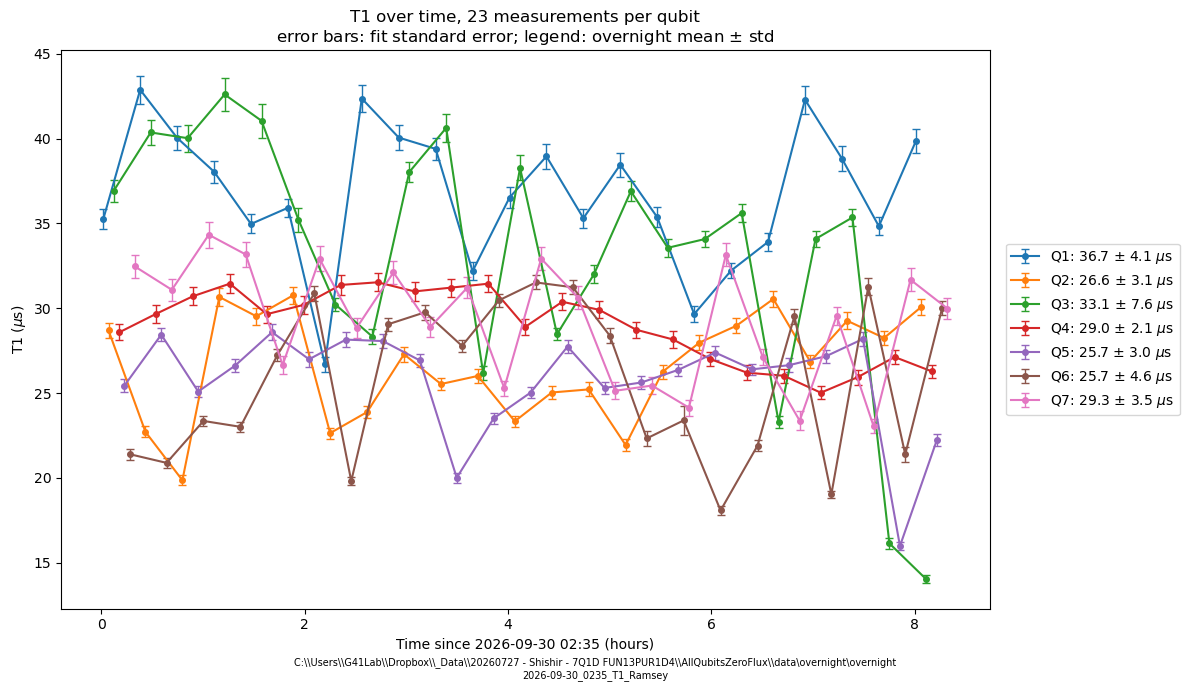

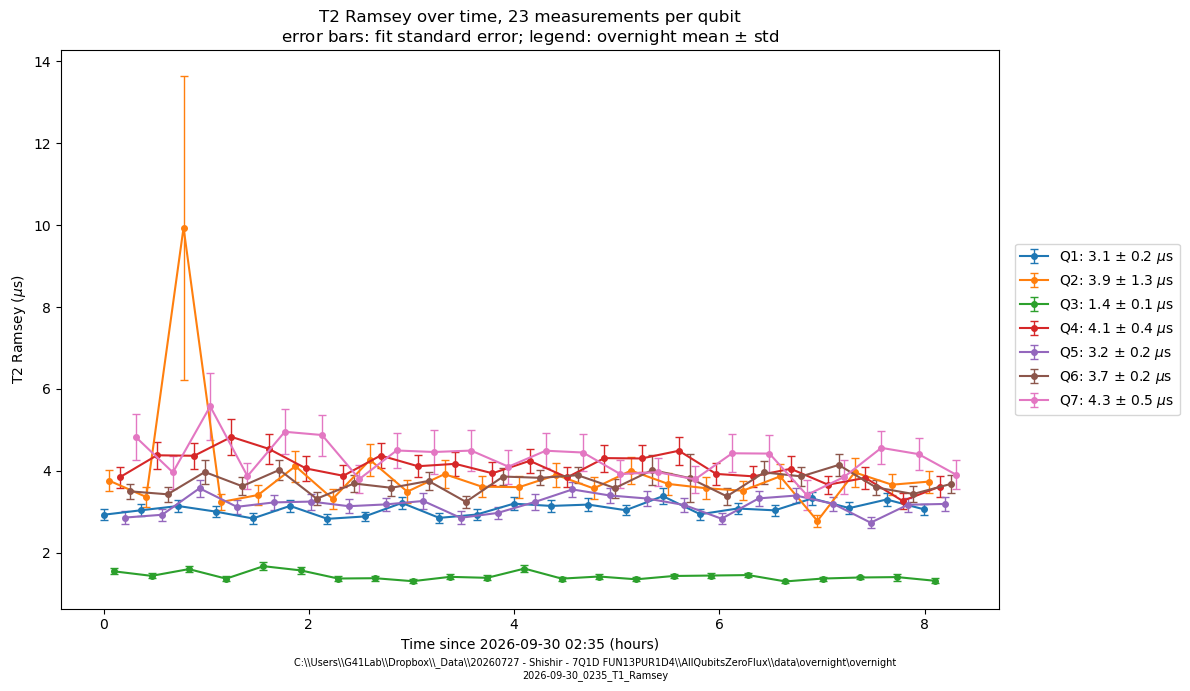


                 f_qubit (MHz)           T1 (us)    T2 Ramsey (us)
Q1     3865.7434 +/-   24 kHz     36.7 +/-  4.1     3.07 +/- 0.16
Q2     3927.3345 +/-  255 kHz     26.6 +/-  3.1     3.93 +/- 1.35
Q3     3740.7830 +/-   22 kHz     33.1 +/-  7.6     1.43 +/- 0.10
Q4     3872.0117 +/-   19 kHz     29.0 +/-  2.1     4.08 +/- 0.35
Q5     3801.6185 +/-   22 kHz     25.7 +/-  3.0     3.17 +/- 0.22
Q6     3937.2315 +/-   16 kHz     25.7 +/-  4.6     3.71 +/- 0.25
Q7     3970.8360 +/-   31 kHz     29.3 +/-  3.5     4.31 +/- 0.49


In [112]:
folder = r"overnight\overnight\2026-09-30_0235_T1_Ramsey"
figs, overnight = analyze_overnight_T1_ramsey(global_data_path, folder)

### Single Shot

In [ ]:
@_accepts_folder
def analyze_single_shot(global_data_path, filename,
                         ef=False,
                         fidelity_method="method1",
                         hist_range=50,
                         bin_num=100, show_plot=True, ax=None):
    """
    Single-shot IQ readout experiment.

    Plots the IQ blobs and computes readout fidelity using the chosen method.
    If ef=True, also computes g-f and e-f fidelity.

    Parameters
    ----------
    global_data_path : str
        Root directory for all data files.
    filename : str
        HDF5 filename, e.g. "00007_IQ_plot_Q1_2026-06-06.h5".
    ef : bool
        True if |f>-state data was also collected.
    fidelity_method : str
        "method1" — manual IQ projection + threshold sweep.
        "method2" — rotated histogram via plotting_helpers.hist().
        "both"    — run both and print both results.
    hist_range : float
        Range parameter for method2 (passed to ``hist()``).
    bin_num : int
        Number of histogram bins for method1.
    show_plot : bool
        If True, add a legend and display the IQ scatter figure.

    ax : matplotlib Axes, optional
        Draw into this axes (one panel of a collage) instead of a new figure;
        the data-path stamp is then left to the caller.

    Returns
    -------
    fig : matplotlib Figure
        Handle to the IQ scatter figure, for further modification.
    """
    data = _build_path(global_data_path, filename)
    print(f"Data path: {data}")

    with SlabFile(data, 'r') as f:
        I_g = array(f['I_g'])[0]
        Q_g = array(f['Q_g'])[0]
        I_e = array(f['I_e'])[0]
        Q_e = array(f['Q_e'])[0]
        if ef:
            I_f = array(f['I_f'])[0]
            Q_f = array(f['Q_f'])[0]
        config = _load_config(f)

    # IQ scatter plot
    if ax is None:
        fig = plt.figure()
    else:
        plt.sca(ax)
        fig = ax.figure
    plt.title(_qubit_prefix(config) + "IQ Plot")
    plt.plot(I_g, Q_g, '.', label='g')
    plt.plot(I_e, Q_e, '.', label='e')
    if ef:
        plt.plot(I_f, Q_f, '.', label='f')
    plt.xlabel("I")
    plt.ylabel("Q")
    if show_plot:
        plt.legend()
    plt.axis('square')

    # Which qubit pulse prepared |e>, and at what gain, written under the axes
    # above the data-path stamp. half_pi='True' means two X90 pulses at
    # half_pi_gain_ge; anything else (including files from before the option
    # existed) is the single pi pulse at qubit_gain_ge.
    if config.get('half_pi') == 'True':
        pulse_label, gain_key = "Half-pi pulse gain", 'half_pi_gain_ge'
    else:
        pulse_label, gain_key = "Pi pulse gain", 'qubit_gain_ge'
    pulse_note = (f"{pulse_label}: {config[gain_key]}"
                  if gain_key in config else None)

    # Rotation angle and threshold from the histogram method, worked out once
    # up front so every figure can carry them; method 2 draws the same
    # numbers below. theta is the rotation that lays the g->e separation
    # along +I, threshold is in those rotated I units.
    _, ss_threshold, ss_theta = hist(data=[I_g, Q_g, I_e, Q_e],
                                     plot=False, ran=hist_range)
    footnote = "    ".join(
        ([pulse_note] if pulse_note else [])
        + [f"threshold: {ss_threshold:.4f}",
           f"angle: {np.degrees(ss_theta):.2f} deg"])
    print(f"  {footnote}")

    if ax is None:
        _stamp_data_path(data, footnote=footnote)
        if show_plot:
            plt.show()
    else:
        # in a collage the note goes under the panel's own x label; the
        # fidelity figures below still come out separately
        ax.set_xlabel(ax.get_xlabel() + chr(10) + footnote)

    # g-e fidelity
    print("--- g-e fidelity ---")
    if fidelity_method in ("method1", "both"):
        _compute_fidelity_by_projection(I_g, Q_g, I_e, Q_e,
                                         bin_num=bin_num, plot=True,
                                         data_path=data, footnote=footnote)
    if fidelity_method in ("method2", "both"):
        _compute_fidelity_by_hist(I_g, Q_g, I_e, Q_e,
                                   plot=True, ran=hist_range,
                                   data_path=data, footnote=footnote)

    # g-f and e-f fidelity if ef data present
    if ef:
        print("--- g-f fidelity ---")
        _compute_fidelity_gf_projection(I_g, Q_g, I_f, Q_f,
                                         bin_num=bin_num, plot=True,
                                         data_path=data, footnote=footnote)
        print("--- e-f fidelity ---")
        _compute_fidelity_ef_projection(I_e, Q_e, I_f, Q_f,
                                         bin_num=bin_num, plot=True,
                                         data_path=data, footnote=footnote)

    return fig

In [ ]:
filename = r"00013_IQ_plot_Q1_2026-09-17.h5"
analyze_single_shot(global_data_path, filename, fidelity_method="both")

# every qubit of a meas_list folder in one figure
# analyze_single_shot(global_data_path, r"<meas_list folder>", collage=True)

### Readout Optimization

In [ ]:
@_accepts_folder
def analyze_readout_optimization(global_data_path, filename,
                                  ge=True, gf=False, ef=False,
                                  fidelity_method="method1",
                                  hist_range=50, show_plot=True, ax=None):
    """
    Readout optimisation sweep (frequency x gain).

    Computes a 2D fidelity map, plots it, prints the optimal indices,
    and returns the fidelity array so it can be inspected further with
    ``inspect_readout_optimization_point()``.

    Parameters
    ----------
    global_data_path : str
        Root directory for all data files.
    filename : str
        HDF5 filename, e.g. "00001_Readout_Optimization_ge_Q1_2026-05-31.h5".
    ge : bool
        Discriminate g-e.
    gf : bool
        Discriminate g-f (requires f-state data in file).
    ef : bool
        Discriminate e-f (requires f-state data in file).
    fidelity_method : str
        "method1" — manual IQ projection (used to build the 2D map).
        "method2" — plotting_helpers.hist() (used to build the 2D map).
        Note: method1 is significantly faster for the full sweep.
    hist_range : float
        Range parameter for method2.
    show_plot : bool
        If True, display the fidelity colormap figure.

    ax : matplotlib Axes, optional
        Draw into this axes (one panel of a collage) instead of a new figure;
        the data-path stamp is then left to the caller.

    Returns
    -------
    fid_Array : 2D np.array, shape (gain_steps, freq_steps)
        Fidelity at each (gain, freq) point.
    gains_list : 1D np.array
        Gain values corresponding to rows.
    freqs_list : 1D np.array
        Frequency values corresponding to columns.
    fig : matplotlib Figure
        Handle to the fidelity colormap figure, for further modification.
    """
    data = _build_path(global_data_path, filename)
    print(f"Data path: {data}")

    with SlabFile(data, 'r') as f:
        I_g_array = array(f['I_g_array'])[0]
        Q_g_array = array(f['Q_g_array'])[0]
        I_e_array = array(f['I_e_array'])[0]
        Q_e_array = array(f['Q_e_array'])[0]
        if ef or gf:
            I_f_array = array(f['I_f_array'])[0]
            Q_f_array = array(f['Q_f_array'])[0]
        config = _load_config(f)

    # Build frequency and gain axes from config
    freq_start = config['freq_start']
    freq_steps = config['freq_steps']
    freq_step_size = config['freq_step_size']
    gain_start = config['gain_start']
    gain_steps = config['gain_steps']
    gain_step_size = config['gain_step_size']

    freqs_list = np.array([freq_start + i * freq_step_size for i in range(freq_steps)])
    gains_list = np.array([gain_start + i * gain_step_size for i in range(gain_steps)])

    fid_Array = np.zeros((gain_steps, freq_steps))

    for idx_f in range(freq_steps):
        for idx_g in range(gain_steps):
            if ge:
                I_g = I_g_array[idx_f][0][idx_g][0]
                Q_g = Q_g_array[idx_f][0][idx_g][0]
                I_e = I_e_array[idx_f][0][idx_g][0]
                Q_e = Q_e_array[idx_f][0][idx_g][0]

                if fidelity_method == "method2":
                    fid, _, _ = hist(data=[I_g, Q_g, I_e, Q_e],
                                     plot=False, ran=hist_range)
                    fid_Array[idx_g, idx_f] = fid
                else:
                    # method1: projection
                    vec_I = np.mean(I_e) - np.mean(I_g)
                    vec_Q = np.mean(Q_e) - np.mean(Q_g)
                    norm = abs(vec_I + 1j * vec_Q) ** 2
                    gstate = ((I_g - np.mean(I_g)) * vec_I
                              + (Q_g - np.mean(Q_g)) * vec_Q) / norm
                    estate = ((I_e - np.mean(I_g)) * vec_I
                              + (Q_e - np.mean(Q_g)) * vec_Q) / norm
                    th_list = np.linspace(min(gstate), max(estate), 1000)
                    fid_curve = [
                        (np.sum(gstate < th) + np.sum(estate > th))
                        / len(gstate) / 2
                        for th in th_list
                    ]
                    fid_Array[idx_g, idx_f] = max(fid_curve) * 2 - 1

            elif gf:
                I_g = I_g_array[idx_f][0][idx_g][0]
                Q_g = Q_g_array[idx_f][0][idx_g][0]
                I_f = I_f_array[idx_f][0][idx_g][0]
                Q_f = Q_f_array[idx_f][0][idx_g][0]
                vec_I = np.mean(I_f) - np.mean(I_g)
                vec_Q = np.mean(Q_f) - np.mean(Q_g)
                norm = abs(vec_I + 1j * vec_Q) ** 2
                gstate = ((I_g - np.mean(I_g)) * vec_I
                          + (Q_g - np.mean(Q_g)) * vec_Q) / norm
                fstate = ((I_f - np.mean(I_g)) * vec_I
                          + (Q_f - np.mean(Q_g)) * vec_Q) / norm
                th_list = np.linspace(min(gstate), max(fstate), 1000)
                fid_curve = [
                    (np.sum(gstate < th) + np.sum(fstate > th))
                    / len(gstate) / 2
                    for th in th_list
                ]
                fid_Array[idx_g, idx_f] = max(fid_curve) * 2 - 1

            elif ef:
                I_e = I_e_array[idx_f][0][idx_g][0]
                Q_e = Q_e_array[idx_f][0][idx_g][0]
                I_f = I_f_array[idx_f][0][idx_g][0]
                Q_f = Q_f_array[idx_f][0][idx_g][0]
                vec_I = np.mean(I_f) - np.mean(I_e)
                vec_Q = np.mean(Q_f) - np.mean(Q_e)
                norm = abs(vec_I + 1j * vec_Q) ** 2
                estate = ((I_e - np.mean(I_e)) * vec_I
                          + (Q_e - np.mean(Q_e)) * vec_Q) / norm
                fstate = ((I_f - np.mean(I_e)) * vec_I
                          + (Q_f - np.mean(Q_e)) * vec_Q) / norm
                th_list = np.linspace(min(estate), max(fstate), 1000)
                fid_curve = [
                    (np.sum(estate < th) + np.sum(fstate > th))
                    / len(estate) / 2
                    for th in th_list
                ]
                fid_Array[idx_g, idx_f] = max(fid_curve) * 2 - 1

    # 2D fidelity colormap
    if ax is None:
        fig = plt.figure(figsize=(24, 8), dpi=80)
    else:
        plt.sca(ax)
        fig = ax.figure
    norm_color = matplotlib.colors.Normalize(vmin=0.0, vmax=1.0)
    figA = plt.pcolormesh(freqs_list, gains_list, fid_Array, norm=norm_color)
    figB = plt.contour(freqs_list, gains_list, fid_Array, 10, colors='w')
    plt.clabel(figB, figB.levels, inline=True, fontsize=20 if ax is None else 9)
    plt.ylabel("Gain, DAC Unit")
    plt.xlabel("Frequency, (MHz)")
    if ge:
        plt.title(_qubit_prefix(config) + "Fidelity, Discriminate g-e")
    elif gf:
        plt.title(_qubit_prefix(config) + "Fidelity, Discriminate g-f")
    elif ef:
        plt.title(_qubit_prefix(config) + "Fidelity, Discriminate e-f")
    plt.colorbar(figA)
    if ax is None:
        _stamp_data_path(data)
        if show_plot:
            plt.show()

    # Print optimal point
    idx_amp_max, idx_freq_max = np.where(fid_Array == np.max(fid_Array))
    print(f"  Max fidelity:  {np.max(fid_Array):.4f}")
    print(f"  Optimal gain:  {gains_list[idx_amp_max[0]]:.4f}  (index {idx_amp_max[0]})")
    print(f"  Optimal freq:  {freqs_list[idx_freq_max[0]]:.4f} MHz  (index {idx_freq_max[0]})")

    return fid_Array, gains_list, freqs_list, fig

In [ ]:
filename = r"00000_Readout_Optimization_ge_Q1_2026-09-16.h5"
fid_Array, gains_list, freqs_list, fig = analyze_readout_optimization(global_data_path, filename)

In [ ]:
def inspect_readout_optimization_point(global_data_path, filename,
                                        gain_index, freq_index,
                                        ge=True, gf=False, ef=False,
                                        fidelity_method="method1",
                                        hist_range=50, bin_num=100,
                                        show_plot=True):
    """
    Inspect a specific (gain, freq) point from the readout optimisation sweep.

    Plots the IQ scatter and projected histogram for the chosen indices.

    Parameters
    ----------
    global_data_path : str
        Root directory for all data files.
    filename : str
        Same file used in ``analyze_readout_optimization()``.
    gain_index : int
        Index into the gain axis.
    freq_index : int
        Index into the frequency axis.
    ge, gf, ef : bool
        Which pair of states to discriminate.
    fidelity_method : str
        "method1", "method2", or "both".
    hist_range : float
        Range parameter for method2.
    bin_num : int
        Number of histogram bins for method1.
    show_plot : bool
        If True, add a legend and display the IQ scatter figure.

    Returns
    -------
    fig : matplotlib Figure
        Handle to the IQ scatter figure, for further modification.
    """
    data = _build_path(global_data_path, filename)

    with SlabFile(data, 'r') as f:
        I_g_array = array(f['I_g_array'])[0]
        Q_g_array = array(f['Q_g_array'])[0]
        I_e_array = array(f['I_e_array'])[0]
        Q_e_array = array(f['Q_e_array'])[0]
        if ef or gf:
            I_f_array = array(f['I_f_array'])[0]
            Q_f_array = array(f['Q_f_array'])[0]
        config = _load_config(f)

    # Rebuild axes for labelling
    freq_start = config['freq_start']
    freq_step_size = config['freq_step_size']
    gain_start = config['gain_start']
    gain_step_size = config['gain_step_size']
    freq_val = freq_start + freq_index * freq_step_size
    gain_val = gain_start + gain_index * gain_step_size

    I_g = I_g_array[freq_index][0][gain_index][0]
    Q_g = Q_g_array[freq_index][0][gain_index][0]
    I_e = I_e_array[freq_index][0][gain_index][0]
    Q_e = Q_e_array[freq_index][0][gain_index][0]

    # IQ scatter
    fig = plt.figure()
    plt.title(_qubit_prefix(config) + f"IQ Plot\nGain = {gain_val}, Frequency = {freq_val} MHz")
    plt.plot(I_g, Q_g, '.', label='g', zorder=1)
    plt.plot(I_e, Q_e, '.', label='e', zorder=2)
    plt.xlabel("I")
    plt.ylabel("Q")
    if show_plot:
        plt.legend()
    plt.axis('square')
    _stamp_data_path(data)
    if show_plot:
        plt.show()

    print(f"  Gain:      {gain_val} (index {gain_index})")
    print(f"  Frequency: {freq_val} MHz (index {freq_index})")

    if ge:
        if fidelity_method in ("method1", "both"):
            _compute_fidelity_by_projection(I_g, Q_g, I_e, Q_e,
                                             bin_num=bin_num, plot=True,
                                             data_path=data)
        if fidelity_method in ("method2", "both"):
            _compute_fidelity_by_hist(I_g, Q_g, I_e, Q_e,
                                       plot=True, ran=hist_range,
                                       data_path=data)
    elif gf:
        I_f = I_f_array[freq_index][0][gain_index][0]
        Q_f = Q_f_array[freq_index][0][gain_index][0]
        _compute_fidelity_gf_projection(I_g, Q_g, I_f, Q_f,
                                         bin_num=bin_num, plot=True,
                                         data_path=data)
    elif ef:
        I_f = I_f_array[freq_index][0][gain_index][0]
        Q_f = Q_f_array[freq_index][0][gain_index][0]
        _compute_fidelity_ef_projection(I_e, Q_e, I_f, Q_f,
                                         bin_num=bin_num, plot=True,
                                         data_path=data)

    return fig

In [ ]:
# Inspect a specific (gain_index, freq_index) point from the fidelity map
inspect_readout_optimization_point(global_data_path, filename,
                                    gain_index=4, freq_index=4,
                                    fidelity_method="both")

#### Readout Optimization - Readout Length

In [ ]:
def analyze_readout_fidelity_ro_length(global_data_path, folder_name,
                                        fidelity_method="method1",
                                        hist_range=50, bin_num=100,
                                        plot_each=False,
                                        show_plot=True, title_append=""):
    """
    Readout fidelity against readout duration.

    Reads a folder written by 014b_readout_fidelity_ro_length_ge.py - one
    single-shot g/e file per readout length - computes the fidelity of each
    the same way analyze_single_shot does, and plots it against the ro_length
    that produced it.

    Both fidelity estimates are always computed and returned; fidelity_method
    only decides which are drawn.

    Parameters
    ----------
    global_data_path : str
        Root directory for all data files.
    folder_name : str
        Subfolder holding the scan, e.g.
        "00000_readout_fidelity_ro_length_ge_Q1_2026-09-16". Every .h5 in it
        is used.
    fidelity_method : {"method1", "method2", "both"}
        Which estimate to plot: "method1" is the centroid-axis projection with
        a threshold sweep, "method2" the optimal-angle rotation and histogram
        overlap from plotting_helpers.hist, "both" draws both.
    hist_range : float
        Histogram range passed to method 2.
    bin_num : int
        Number of bins for method 1.
    plot_each : bool
        If True, also run analyze_single_shot on every file, so each IQ blob
        and its histograms can be eyeballed.
    show_plot : bool
        If True, add a legend and display the figure.
    title_append : str
        Extra text appended to the plot title.

    Returns
    -------
    fig : matplotlib Figure
        Handle to the fidelity figure.
    ro_lengths : 1D np.array
        Readout duration (us) for each file, in the order plotted.
    fid_projection : 1D np.array
        Method 1 fidelity for each file, in the order plotted.
    fid_hist : 1D np.array
        Method 2 fidelity for each file, in the order plotted.
    """
    if fidelity_method not in ("method1", "method2", "both"):
        raise ValueError(
            f"fidelity_method must be 'method1', 'method2' or 'both', "
            f"got {fidelity_method!r}")

    folder_path = os.path.join(global_data_path, folder_name)
    print(f"Data folder: {folder_path}")

    files = sorted(f for f in os.listdir(folder_path) if f.endswith('.h5'))
    if not files:
        raise ValueError(f"No .h5 files found in {folder_path}")

    ro_lengths, fid_projection, fid_hist = [], [], []
    thresholds, angles = [], []
    config = {}

    for fname in files:
        data = os.path.join(folder_path, fname)

        with SlabFile(data, 'r') as f:
            I_g = array(f['I_g'])[0]
            Q_g = array(f['Q_g'])[0]
            I_e = array(f['I_e'])[0]
            Q_e = array(f['Q_e'])[0]
            cfg = _load_config(f)

        if not config:
            config = cfg

        # Same two estimates analyze_single_shot uses, without their plots.
        fid1, _, _ = _compute_fidelity_by_projection(I_g, Q_g, I_e, Q_e,
                                                     bin_num=bin_num, plot=False)
        fid2, threshold, angle = _compute_fidelity_by_hist(I_g, Q_g, I_e, Q_e,
                                                           plot=False, ran=hist_range)
        ro = cfg['ro_length']

        ro_lengths.append(ro)
        fid_projection.append(fid1)
        fid_hist.append(fid2)
        thresholds.append(threshold)
        angles.append(np.degrees(angle))
        print(f"  ro_length {ro} us -> fidelity {fid1:.4f} (projection), "
              f"{fid2:.4f} (histogram), threshold {threshold:.4f}, "
              f"angle {np.degrees(angle):.2f} deg")

        if plot_each:
            analyze_single_shot(folder_path, fname,
                                fidelity_method=fidelity_method,
                                hist_range=hist_range, bin_num=bin_num,
                                show_plot=show_plot)

    ro_lengths = np.array(ro_lengths, dtype=float)
    fid_projection = np.array(fid_projection, dtype=float)
    fid_hist = np.array(fid_hist, dtype=float)
    thresholds = np.array(thresholds, dtype=float)
    angles = np.array(angles, dtype=float)

    order = np.argsort(ro_lengths)
    ro_lengths = ro_lengths[order]
    fid_projection, fid_hist = fid_projection[order], fid_hist[order]
    thresholds, angles = thresholds[order], angles[order]

    fig, ax = plt.subplots(figsize=(12,8))
    if fidelity_method in ("method1", "both"):
        ax.plot(ro_lengths, fid_projection, 'o-', color='tab:blue',
                markersize=7, label='projection (method 1)')
    if fidelity_method in ("method2", "both"):
        ax.plot(ro_lengths, fid_hist, 's-', color='tab:orange',
                markersize=7, label='histogram (method 2)')
    ax.set_xlabel("Readout Pulse Length (us)")
    ax.set_ylabel("Readout Fidelity")
    ax.set_title(_qubit_prefix(config) + "Readout Fidelity vs Readout Duration"
                 + chr(10) + title_append)

    # Which pulse prepared |e>, as on the single-shot plots. Every file in the
    # scan shares it, so the first file's config is enough.
    if config.get('half_pi') == 'True':
        pulse_label, gain_key = "Half-pi pulse gain", 'half_pi_gain_ge'
    else:
        pulse_label, gain_key = "Pi pulse gain", 'qubit_gain_ge'
    pulse_note = (f"{pulse_label}: {config[gain_key]}"
                  if gain_key in config else None)

    best = fid_projection if fidelity_method == "method1" else fid_hist
    i_best = int(np.argmax(best))
    print("")
    print(f"  Files:            {len(files)}")
    print(f"  ro_length:        {ro_lengths[0]:.3f} to {ro_lengths[-1]:.3f} us")
    print(f"  Best fidelity:    {best[i_best]:.4f} at ro_length = "
          f"{ro_lengths[i_best]} us"
          f"{'' if fidelity_method == 'method1' else ' (histogram)'}")
    print(f"  Angle spread:     {angles.max() - angles.min():.2f} deg across the scan")

    if show_plot:
        ax.legend()
    _stamp_data_path(folder_path, fig, footnote=pulse_note)
    if show_plot:
        plt.show()

    return fig, ro_lengths, fid_projection, fid_hist

In [ ]:
data_folder = "00003_readout_fidelity_ro_length_ge_Q1_2026-09-16"
analyze_readout_fidelity_ro_length(global_data_path, data_folder)